##**Project:** The Backpack Doctor — Field-based dysglycemia triage
##**Module:** CIP02, Autumn 2026
##Owner: M. Mogos

# 0. Overview

This notebook takes the project from external data sources to a frozen,
analysis-ready dataset, and then explores that dataset before modelling.
It covers the first two of the three tasks the module evaluates:

- **Data acquisition.** Retrieving NHANES and CDC PLACES programmatically,
  reading the NHANES documentation, and interacting with the dynamic
  variable search interface.
- **Data cleaning and transformation.** Applying the six mandatory
  cleansing steps the module specifies, plus additional checks this
  project requires.

It ends with a saved analytic sample, a data dictionary, and an
acquisition metadata table. The modelling notebook loads the analytic
sample directly and does not re-run any of the work here.

## Contents

| Section | Content |
|---|---|
| 1 | Project context |
| 2 | Setup |
| 3 | Data acquisition |
| 3.1 | The NHANES 2021–2023 file listing |
| 3.2 | Files in scope |
| 3.3 | The codebook for the in-scope files |
| 3.3.1 | Static codebook pages (pipeline source) |
| 3.3.2 | Dynamic search interface (Selenium interaction) |
| 3.4 | Variable requirements |
| 3.5 | Variable selection |
| 3.6 | Retrieval, merge, decode, and label |
| 3.7 | CDC PLACES acquisition (REST API) |
| 4 | Cleaning |
| 4.0 | Introduction to the cleansing steps |
| 4.1 | Datatypes |
| 4.2 | Gaps and missing data |
| 4.3 | Expected ranges |
| 4.4 | Outliers |
| 4.5 | Format for task |
| 4.6 | Enrichment |
| 4.7 | Additional checks |
| 4.8 | Clinical exclusions |
| 5 | Exploratory analysis |
| 6 | Freeze and handoff |

### The three acquisition methods

The module names three acceptable approaches to data acquisition. Each is
used where it is the natural fit:

| Method | Used for |
|---|---|
| Web scraping | NHANES codebook pages (static, Section 3.3.1); NHANES variable search interface (dynamic, Section 3.3.2) |
| Programmatic package | NHANES data files (`pynhanes`) |
| REST API | CDC PLACES county prevalence (Section 3.7) |

The dynamic-element requirement is satisfied by the Selenium interaction
in Section 3.3.2: the search box is located by id, a keyword is
submitted, the cycle filter is applied, and the rendered table is parsed
with BeautifulSoup. The rendered HTML is archived as evidence.

### The six mandatory cleansing steps

The module specifies six cleansing steps and requires each to be
addressed, even where a step turns out to require no action. They are
applied in dependency order rather than listing order:

| Module's step | Applied in | Result |
|---|---|---|
| 2 — Datatypes | 4.1 | 4 columns retyped; 10 unchanged |
| 1 — Gaps and missing data | 4.2 | Pattern analysed; complete-case filter applied in 4.5 |
| 3 — Expected ranges | 4.3 | No violations against published source; external plausibility check in 4.3.1 |
| 4 — Outliers | 4.4 | Two methods compared; no records removed |
| 5 — Format for task | 4.5 | First BP reading primary, average retained for sensitivity; adults only; complete cases |
| 6 — Enrichment | 4.6 | Derived columns added and validated |

### Additional checks

Four checks are added beyond the module's requirements, motivated by the
structure of NHANES and the clinical question:

| Check | Purpose |
|---|---|
| Primary key uniqueness | Confirm no participant appears twice |
| Skip-pattern verification | Distinguish structural missingness from data loss |
| Cross-file consistency | Confirm the merge introduced no records and dropped none |
| Survey-weight decision | State whether sampling weights are used, and why |

### Blood pressure columns

NHANES records up to three oscillometric readings per participant. A
backpack doctor takes one reading, so the primary model uses the first
reading (`systolic`, `diastolic`). The average of available readings
(`systolic_avg`, `diastolic_avg`) is retained as a sensitivity comparison
in the modelling notebook. Both pairs are kept; the choice is documented
in Section 4.5.

### Clinical exclusions

Section 4.8 removes three groups of records that fall outside the
project's scope:

| Group | Records | Reason |
|---|---|---|
| Pregnant women | 32 | Pregnancy alters A1C independently of glycemia |
| Pregnancy status cannot be ascertained | 13 | A1C confound cannot be ruled out |
| Prior diabetes diagnosis | 741 | Glucose-lowering treatment alters A1C |

The exclusions remove 786 records with no overlap, leaving an analytic
sample of **4,613 records**. This is the sample the model will be trained
on and that Section 5 explores.

### Outputs

| File | Description |
|---|---|
| `data/processed/nhanes_file_listing.csv` | Complete inventory of the 2021–2023 cycle |
| `data/processed/nhanes_codebook.csv` | Variable-level dictionary for the in-scope files (81 variables, 6 files) |
| `data/processed/nhanes_merged.csv` | Raw merged data, before cleaning |
| `data/raw/nhanes_search_rendered.html` | Rendered HTML from the dynamic search interaction (Section 3.3.2) |
| `data/raw/places_diabetes_raw.json` | Raw PLACES API response (Section 3.7) |
| `data/processed/places_county.csv` | County-level diagnosed diabetes prevalence (2,957 counties) |
| `data/processed/acquisition_metadata.csv` | Source, endpoint, retrieval date, and row count for each input |
| `data/processed/nhanes_clean.csv` | Complete-case sample after cleaning, before clinical exclusions (5,399 records) |
| `data/processed/nhanes_analytic.csv` | **The analytic sample — 4,613 records, 12 columns** |

### Definition of done

- The NHANES documentation is read programmatically, and a data
  dictionary is exported as a CSV (Section 3.3.1).
- The dynamic variable search interface is interacted with via Selenium
  (Section 3.3.2), and the rendered output is parsed and archived.
- CDC PLACES is retrieved via the Socrata API (Section 3.7), with raw
  JSON and a metadata table saved.
- Each variable the project uses is traceable to a stated requirement and
  to a description in the documentation.
- The six mandatory cleansing steps are documented, each with the module
  requirement named.
- The four additional checks are documented.
- Exploratory analysis establishes distributions, class balance, and
  subgroup patterns.
- The clinical exclusions are applied and verified, and the analytic
  sample is written to `data/processed/nhanes_analytic.csv`.

### How the two notebooks connect

Notebook 01 produces the dataset. Notebook 02 loads it directly and
performs the modelling for RQ1 and RQ3, and the recalibration analysis
for RQ2. Every number in the final report traces to code in one of the
two notebooks.

---



## 1. Project context

A field health worker carrying portable tools — a blood pressure cuff, a
tape measure, and a scale — needs to identify patients who should be
referred for a laboratory A1C test. The A1C test is outside the assumed
toolkit, so the referral decision must rest on measurements taken in the
field.

The project addresses three questions:

- **RQ1.** How accurately do backpack-measurable variables predict
  A1C-defined dysglycemia?
- **RQ2.** How does the reliability of a positive result change with local
  disease prevalence?
- **RQ3.** Does the model perform equally well across demographic
  subgroups?

The outcome combines prediabetes (A1C 5.7–6.4%) and diabetes (A1C ≥ 6.5%)
into a single category, because both warrant laboratory confirmation. The
diabetes-only threshold is reported as a sensitivity analysis in the
modelling notebook.

Clinical exclusions — pregnant women, women whose pregnancy status could
not be ascertained, and participants with a prior diabetes diagnosis — are
applied in Section 4.8. The reasons and the counts are documented there.

---


# 2. Setup

### Packages

| Package | Purpose |
|---|---|
| `pynhanes` | Retrieval of NHANES data files from the CDC website |
| `requests`, `BeautifulSoup` | Scraping the static NHANES codebook pages; parsing the dynamic search results |
| `Selenium` | Driving the NHANES variable search interface (Section 3.3.2) |
| `pandas`, `numpy` | Data handling |
| `matplotlib`, `seaborn` | Figures |

### Constants

| Constant | Value | Meaning |
|---|---|---|
| `NHANES_CYCLE` | `2021-2023` | Survey cycle |
| `NHANES_FILES` | `DEMO, BMX, BPXO, GHB, BPQ, DIQ` | Files identified in Section 3.2 |
| `A1C_DYSGLYCEMIA` | `5.7` | Primary outcome threshold |
| `A1C_DIABETES` | `6.5` | Diabetes-only threshold |
| `MIN_AGE` | `20` | Adult cutoff |
| `PLACES_ENDPOINT` | `https://data.cdc.gov/resource/swc5-untb.json` | County prevalence source (Socrata) |

In [1]:
#Install (uncomment on a fresh machine / Colab)
# %pip install -r requirements.txt --quiet

#Imports
import os
import re
import json
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from bs4 import BeautifulSoup
import subprocess
import shutil
import time
from pathlib import Path
from datetime import date

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

import pynhanes.downloader as nhanes_dl
import pynhanes.parser as parser

#Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

#Paths
DATA_RAW       = 'data/raw'
DATA_PROCESSED = 'data/processed'
FIGURES        = 'figures'

for p in (DATA_RAW, DATA_PROCESSED, FIGURES):
    os.makedirs(p, exist_ok=True)

#NHANES
NHANES_CYCLE  = '2021-2023'
NHANES_FILES  = ['DEMO', 'BMX', 'BPXO', 'GHB', 'DIQ']
NHANES_DOC_BASE = 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles'

#Clinical thresholds
A1C_DYSGLYCEMIA = 5.7
A1C_DIABETES    = 6.5
MIN_AGE         = 20

#External source
PLACES_ENDPOINT = 'https://data.cdc.gov/resource/swc5-untb.json'

#Display
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')


# ── Selenium environment check ─────────────────────────────────────────
# Selenium 4 downloads a matching driver automatically (Selenium Manager).
# Set the CHROME_BINARY environment variable if Chrome/Chromium is installed
# in a non-standard location.
CHROME_BINARY = os.environ.get('CHROME_BINARY') or shutil.which('google-chrome') or shutil.which('chromium') or None
print(f'Chrome binary: {CHROME_BINARY or "system default"}')

print('Environment ready.')

Chrome binary: /opt/pw-browsers/chromium-1194/chrome-linux/chrome
Environment ready.


In [2]:
# Packages are listed in requirements.txt (pip install -r requirements.txt).
print('Environment ready.')


Environment ready.


# 3. Data acquisition
The acquisition works in four steps:

1. **Read the NHANES file listing** for the 2021–2023 cycle. This tells us
   what data files the cycle contains, with a short description of each.
2. **Identify the files in scope**, based on the file descriptions and the
   clinical requirement.
3. **Read the documentation** for each in-scope file. Each file has a
   companion page listing every variable it contains, with its
   description and permitted values.
4. **Select the variables** the project needs, and retrieve the files.

The file listing and the codebook pages are both read programmatically.
The codebook pages are static HTML; the CDC's variable search interface is
JavaScript-rendered, and its behaviour is examined in Section 3.3 as part
of the scraping requirement.



## 3.1 The NHANES 2021–2023 file listing

NHANES publishes its data as SAS transport files, one per data file. The
2021–2023 cycle contains multiple files, organised into components. This
section retrieves the file listing.

The listing is read through `pynhanes.downloader.plan()`, which queries the
CDC's data page and returns the available files with their names,
components, and descriptions.

In [3]:
# ── Retrieve the NHANES 2021-2023 file listing ─────────────────────────
plan = nhanes_dl.plan(
    output='XPT',
    surveys=[NHANES_CYCLE],
    log=lambda *a, **k: None,
)

file_listing = pd.DataFrame([
    {
        'file_code':   item.file.code,
        'file_name':   item.file.name,
        'component':   item.file.component,
        'description': item.file.description,
        'published':   item.file.published,
    }
    for item in plan.items
]).sort_values(['component', 'file_code']).reset_index(drop=True)

print(f'Files in the {NHANES_CYCLE} cycle: {len(file_listing)}')
print()
print(file_listing['component'].value_counts().to_string())
print()
print(file_listing.to_string(index=False))

Files in the 2021-2023 cycle: 31

component
Questionnaire    18
Laboratory        8
Dietary           2
Examination       2
Demographics      1

file_code file_name     component                                                  description          published
     DEMO    DEMO_L  Demographics                     Demographic Variables and Sample Weights     September 2024
   DR1TOT  DR1TOT_L       Dietary        Dietary Interview - Total Nutrient Intakes, First Day       October 2024
   DSQTOT  DSQTOT_L       Dietary    Dietary Supplement Use 30-Day - Total Dietary Supplements Updated April 2025
      BMX     BMX_L   Examination                                                Body Measures     September 2024
     BPXO    BPXO_L   Examination                  Blood Pressure - Oscillometric Measurements     September 2024
   BIOPRO  BIOPRO_L    Laboratory                                Standard Biochemistry Profile     September 2025
      CBC     CBC_L    Laboratory Complete Blood Count wi

**Output.**

    Files in the 2021-2023 cycle: 31

    component
    Questionnaire    18
    Laboratory        8
    Examination       2
    Dietary           2
    Demographics      1

**Full listing.**

| file_code | file_name | component | description | published |
|---|---|---|---|---|
| DEMO | DEMO_L | Demographics | Demographic Variables and Sample Weights | September 2024 |
| DR1TOT | DR1TOT_L | Dietary | Dietary Interview – Total Nutrient Intakes, First Day | October 2024 |
| DSQTOT | DSQTOT_L | Dietary | Dietary Supplement Use 30-Day – Total Dietary Supplements | April 2025 |
| BMX | BMX_L | Examination | Body Measures | September 2024 |
| BPXO | BPXO_L | Examination | Blood Pressure – Oscillometric Measurements | September 2024 |
| BIOPRO | BIOPRO_L | Laboratory | Standard Biochemistry Profile | September 2025 |
| CBC | CBC_L | Laboratory | Complete Blood Count with 5-Part Differential in Whole Blood | September 2024 |
| GHB | GHB_L | Laboratory | Glycohemoglobin | September 2024 |
| HDL | HDL_L | Laboratory | Cholesterol – High-Density Lipoprotein | September 2024 |
| HSCRP | HSCRP_L | Laboratory | High-Sensitivity C-Reactive Protein | September 2024 |
| TCHOL | TCHOL_L | Laboratory | Cholesterol – Total | September 2024 |
| TRIGLY | TRIGLY_L | Laboratory | Cholesterol – Low-Density Lipoproteins (LDL) & Triglycerides | September 2025 |
| TST | TST_L | Laboratory | Sex Steroid Hormone Panel – Serum | October 2024 |
| ACQ | ACQ_L | Questionnaire | Acculturation | September 2024 |
| ALQ | ALQ_L | Questionnaire | Alcohol Use | September 2024 |
| BPQ | BPQ_L | Questionnaire | Blood Pressure & Cholesterol | September 2024 |
| DBQ | DBQ_L | Questionnaire | Diet Behavior & Nutrition | September 2024 |
| DIQ | DIQ_L | Questionnaire | Diabetes | September 2024 |
| DPQ | DPQ_L | Questionnaire | Mental Health – Depression Screener | September 2024 |
| FNQ | FNQ_L | Questionnaire | Functioning | September 2024 |
| HIQ | HIQ_L | Questionnaire | Health Insurance | September 2024 |
| HOQ | HOQ_L | Questionnaire | Housing Characteristics | September 2024 |
| HSQ | HSQ_L | Questionnaire | Current Health Status | September 2024 |
| HUQ | HUQ_L | Questionnaire | Hospital Utilization & Access to Care | September 2024 |
| INQ | INQ_L | Questionnaire | Income | September 2024 |
| MCQ | MCQ_L | Questionnaire | Medical Conditions | September 2024 |
| OCQ | OCQ_L | Questionnaire | Occupation | September 2024 |
| PAQ | PAQ_L | Questionnaire | Physical Activity | September 2024 |
| RXQ_RX | RXQ_RX_L | Questionnaire | Prescription Medications | September 2024 |
| SLQ | SLQ_L | Questionnaire | Sleep Disorders | September 2024 |
| SMQ | SMQ_L | Questionnaire | Smoking – Cigarette Use | September 2024 |

**Interpretation.** The 2021–2023 cycle contains 31 data files, organised
into five components. The Questionnaire component holds 18 of the 31 —
more than half — reflecting the breadth of interview-based data the
survey collects. Laboratory follows with 8 files, Examination and Dietary
each contribute 2, and Demographics contributes 1.

Each file carries a short description. The descriptions are the basis for
the next section, where the files in scope for this project are identified.

**What this establishes.** The complete file inventory for the cycle is
retrieved, with names, components, descriptions, and publication dates.
The publication dates range from September 2024 to April 2025, which
indicates that files within a single cycle are released at different
times — a detail that matters for version traceability in Section 3.7.

The next section identifies which of these 31 files are in scope for the
project, using the file descriptions as the basis.

## 3.2 Files in scope

The project has a identified three research questions, and these questions determine what
the data must contain. Before retrieving anything, the file listing is
narrowed to the files that could answer it.

The project needs three categories of data:

| Category | What it provides | Derived from |
|---|---|---|
| Outcome | A laboratory A1C measurement | RQ1 |
| Predictors | Blood pressure, body measures, and demographic attributes a field worker can record | Project specification |
| Sample definition | Prior diabetes diagnosis, pregnancy status | Feasibility study |

Everything else in the cycle is out of scope. The listing is filtered
against these categories using the file descriptions.

### Method

Each requirement is matched against the descriptions in the file listing.
The matching is stated in terms the reader can check. The filter is
deliberately restrictive: a file is retained only if its description names
one of the categories above. The Files whose descriptions
indicate a different laboratory measurement, dietary recall, or a
questionnaire on an unrelated topic are excluded.



In [4]:
# ── Filter the file listing to files in scope ──────────────────────────
# Each requirement is matched against the file description. The matching
# is case-insensitive and uses short phrases.

SCOPE_PATTERNS = {
    'outcome':           ['glycohemoglobin'],
    'examination':       ['blood pressure', 'body measures'],
    'demographics':      ['demographic'],
    'sample_definition': ['diabetes'],
}

def matches_scope(description, patterns):
    text = str(description).lower()
    return [cat for cat, terms in patterns.items()
            if any(t in text for t in terms)]

file_listing['scope'] = file_listing['description'].apply(
    lambda d: matches_scope(d, SCOPE_PATTERNS)
)
file_listing['in_scope'] = file_listing['scope'].apply(lambda x: len(x) > 0)

in_scope  = file_listing[file_listing['in_scope']].reset_index(drop=True)
out_scope = file_listing[~file_listing['in_scope']].reset_index(drop=True)

print(f'Files in scope:     {len(in_scope)}')
print(f'Files out of scope: {len(out_scope)}')
print()
print('IN SCOPE')
print(in_scope[['file_code', 'component', 'description', 'scope']].to_string(index=False))

Files in scope:     6
Files out of scope: 25

IN SCOPE
file_code     component                                 description               scope
     DEMO  Demographics    Demographic Variables and Sample Weights      [demographics]
      BMX   Examination                               Body Measures       [examination]
     BPXO   Examination Blood Pressure - Oscillometric Measurements       [examination]
      GHB    Laboratory                             Glycohemoglobin           [outcome]
      BPQ Questionnaire                Blood Pressure & Cholesterol       [examination]
      DIQ Questionnaire                                    Diabetes [sample_definition]




**Interpretation.** The filter reduced the 31 files of the cycle to **6 in
scope**. Each of the three data categories the project requires is
represented:

- **Outcome** — `GHB` (Glycohemoglobin), the only file whose description
  names the A1C laboratory measurement.
- **Predictors** — `BMX` (Body Measures), `BPXO` (Blood Pressure –
  Oscillometric Measurements), and `BPQ` (Blood Pressure & Cholesterol).
- **Demographics** — `DEMO` (Demographic Variables and Sample Weights).
- **Sample definition** — `DIQ` (Diabetes).

Twenty-five files were excluded. The largest group is the Questionnaire
component, where 16 of 18 files describe topics unrelated to the clinical
question: acculturation, alcohol use, diet behaviour, depression,
functioning, health insurance, housing, current health status, hospital
utilisation, income, medical conditions, occupation, physical activity,
prescription medications, sleep, and smoking. The Laboratory component
contributed 7 exclusions (standard biochemistry, complete blood count, and
five cholesterol and hormone measurements) and the Dietary component both
of its files.

The exclusions are not because those files lack data of value. They are
because the project's requirement is a specific one: field-measurable
predictors and a laboratory A1C outcome. A file that describes a
laboratory measurement other than A1C, or a questionnaire on a topic
other than diabetes and pregnancy, does not contribute to that
requirement.

**One candidate requires checking.** `BPQ` matched the pattern "blood
pressure" in its description, but its description — "Blood Pressure &
Cholesterol" — does not name a measurement, and its component is
Questionnaire, not Examination (the file matched the description pattern but its inclusion is provisional pending its contents). `BPXO`, by contrast, is described as
"Blood Pressure – Oscillometric Measurements" and is filed under
Examination. The two descriptions differ in a way that matters for the
project: the backpack doctor takes a blood pressure measurement, not a
questionnaire answer. Whether `BPQ` contains a measurement that could
serve the project, or a self-reported history that cannot, is resolved in
Section 3.3 by reading the variables it actually contains. It is retained
in scope for now rather than excluded on the description alone.

**What this establishes.** The file listing is narrowed to six files on
the basis of their published descriptions. Each is traceable to one of the
three data categories the project requires. The next section reads the
documentation for these six files, which lists the variables each
contains, and resolves the question about `BPQ`.

## 3.3 The codebook for the in-scope files

Each of the six in-scope files has a companion codebook page listing every
variable it contains. This section reads those pages and builds a
consolidated dictionary: one row per variable, with its code, its short
label, its description, and the file it belongs to.

### Why this is needed

The file descriptions in Section 3.2 tell us the topic of each file. They
do not tell us which variables the file contains. To select variables, we
need the variable-level detail.

The dictionary also resolves the open question about `BPQ`. Its
description — "Blood Pressure & Cholesterol" — could indicate either a
measurement or a self-reported history. The variables it contains settle
this: `BPQ020`, `BPQ150` and related items are self-reported diagnosis and
medication questions, not measurements.

### Two retrieval methods

Two acquisition methods were used, each for a different purpose.

- **3.3.1 Static codebook pages** — the pipeline source. Complete, static
  HTML, parse deterministically.
- **3.3.2 Dynamic search interface** — the interaction evidence. A
  JavaScript-rendered search interface driven with Selenium, satisfying
  the module's requirement to interact with a dynamic element.

The two are complementary: 3.3.1 produces the 81-variable dictionary used
throughout the cleaning and modelling steps, and 3.3.2 demonstrates the
required dynamic-element skill.

## 3.3.1 Static codebook pages (pipeline source)

Each codebook page is at a predictable address derived from the file name.
The pages are static HTML, with one block per variable containing the
variable code, its SAS label, an English description, the target
population, and — for categorical variables — a value distribution table
that maps each code to its meaning.

The parser extracts six fields per variable: `code`, `label`, `sas_label`,
`english_text`, `target`, and `value_labels`. The last field is the
code-to-meaning mapping, which is what the sentinel decoder in Section 3.6
and the categorical retyping in Section 4.1 read.

**A note on pynhanes.** A Python package called `pynhanes` ships its own
codebook, and it was an option to use that as the pipeline source. We
build our own scraper instead, for three reasons:


1.   The scraped codebook is scoped to the six files we selected, so it carries no extraneous rows
2.   It captures the value-label mapping the analysis needs for sentinel decoding
3. it is reproducible from the code in this notebook


The last two cells of this section compare the two codebooks as a robustness check.

In [5]:
# ── Scrape the codebook for each in-scope file ─────────────────────────

IN_SCOPE_FILES = in_scope['file_name'].tolist()   # DEMO_L, BMX_L, ...

def parse_values_table(table):
    """Turn a <table class='values'> into a dict {code: description}.

    Returns None when the table has more than 30 rows, which means the
    variable is continuous (values are not a fixed set of categories).
    Storing thousands of unique values as a dict would bloat the CSV
    and provide no useful labels.
    """
    rows = table.find_all('tr')
    if not rows:
        return None
    body_rows = rows[1:]  # skip the header row
    if len(body_rows) > 30:
        return None
    labels = {}
    for row in body_rows:
        cells = row.find_all('td')
        if len(cells) < 2:
            continue
        code = cells[0].get_text(strip=True)
        desc = cells[1].get_text(' ', strip=True)
        labels[code] = desc
    return labels or None


def parse_codebook_page(file_name):
    """Parse one NHANES codebook page into a DataFrame of variables."""
    url = f'{NHANES_DOC_BASE}/{file_name}.htm'
    r = requests.get(url, timeout=30)
    if r.status_code != 200:
        return pd.DataFrame()

    soup = BeautifulSoup(r.text, 'html.parser')
    records = []
    pattern = re.compile(r'^([A-Z][A-Z0-9_]{2,})\s*-\s*(.+)$')

    for h3 in soup.find_all('h3', class_='vartitle'):
        text = h3.get_text(strip=True)
        m = pattern.match(text)
        if not m:
            continue
        code, label = m.group(1), m.group(2)

        record = {'code': code, 'label': label,
                  'sas_label': None, 'english_text': None, 'target': None,
                  'value_labels': None,
                  'source_file': file_name}

        parent = h3.find_parent('div')
        if parent is None:
            records.append(record); continue

        # The <dl> holds the description fields
        dl = parent.find('dl')
        if dl is not None:
            for dt in dl.find_all('dt'):
                key = dt.get_text(strip=True).rstrip(':').lower()
                dd = dt.find_next_sibling('dd')
                if dd is None:
                    continue
                val = re.sub(r'\s+', ' ', dd.get_text(' ', strip=True)).strip()
                if key == 'sas label':
                    record['sas_label'] = val
                elif key == 'english text':
                    record['english_text'] = val
                elif key == 'target':
                    record['target'] = val

        # The value distribution table holds the code-to-label mapping
        values_table = parent.find('table', class_='values')
        if values_table is not None:
            record['value_labels'] = parse_values_table(values_table)

        records.append(record)

    return pd.DataFrame(records)


frames = []
for file_name in IN_SCOPE_FILES:
    df_file = parse_codebook_page(file_name)
    frames.append(df_file)
    print(f'{file_name:12s}  {len(df_file):3d} variables')

codebook = pd.concat(frames, ignore_index=True)

# Store value labels as a JSON string so they survive the CSV round trip
codebook['value_labels'] = codebook['value_labels'].apply(
    lambda d: json.dumps(d) if isinstance(d, dict) else None
)

codebook.to_csv('data/processed/nhanes_codebook.csv', index=False)

print()
print(f'Total file-variable entries: {len(codebook)}')
print(f'Unique variable codes:       {codebook["code"].nunique()}')
print(f'Variables with value labels: {codebook["value_labels"].notna().sum()}')

DEMO_L         27 variables


BMX_L          22 variables


BPXO_L         12 variables


GHB_L           3 variables


BPQ_L           6 variables


DIQ_L          11 variables

Total file-variable entries: 81
Unique variable codes:       76
Variables with value labels: 73


In [6]:
# ── Inspect BPQ — the file whose scope was uncertain ───────────────────
# BPQ matched the "blood pressure" pattern in its description, but its
# component is Questionnaire, not Examination. Its variables will show
# whether it contains a measurement or a self-reported history.

bpq = codebook[codebook['source_file'] == 'BPQ_L'].copy()
print('Variables in BPQ_L:')
print()
print(bpq[['code', 'sas_label', 'english_text']].to_string(index=False))

Variables in BPQ_L:

   code                                sas_label                                                                                                                                 english_text
   SEQN               Respondent sequence number                                                                                                                   Respondent sequence number
 BPQ020    Ever told you had high blood pressure {Have you/Has SP} ever been told by a doctor or other health professional that {you/s/he} had hypertension, also called high blood pressure?
 BPQ030  Told had high blood pressure - 2+ times                      {Were you/Was SP} told on 2 or more different visits that {you/s/he} had hypertension, also called high blood pressure?
 BPQ150    Taking high blood pressure medication                                {Are you/Is SP} now taking any medication prescribed by a doctor for {your/his/her/SP's} high blood pressure?
 BPQ080 Doctor told you - hig

**BPQ_L** is included for two variables: BPQ020 (ever told you have high blood
pressure) and BPQ150 (currently taking BP medication). Both are field-askable
and BPQ150 is needed to interpret the measured blood pressure: a treated
hypertensive may show normal measured pressure despite underlying risk.
BPQ030, BPQ080 and BPQ101D are not carried into the model.

In [7]:
# ── Generate the pynhanes codebook for comparison ──────────────────────
# We use our own scraped codebook as the pipeline source. The pynhanes
# codebook is generated here only to cross-check variable coverage.

PYNHANES_CB_PATH = 'data/raw/codebook_pynhanes.csv'

if not os.path.exists(PYNHANES_CB_PATH):
    subprocess.run(['pynhanes-scraper', '-o', PYNHANES_CB_PATH], check=False)

print(f'pynhanes codebook: {PYNHANES_CB_PATH}')
print(f'Exists:            {os.path.exists(PYNHANES_CB_PATH)}')
print(f'Size:              {os.path.getsize(PYNHANES_CB_PATH) / 1024:.1f} KB')

Wrote the codebook that ships with pynhanes to data/raw/codebook_pynhanes.csv: 12774 variables of 385 data files, scraped on 2026-09-24
One row per variable, merged across surveys - see the documentation. Add --refresh to read the NHANES website instead (about 5 minutes)


pynhanes codebook: data/raw/codebook_pynhanes.csv
Exists:            True
Size:              6169.1 KB


In [8]:
# ── Robustness check: our scraper vs pynhanes ──────────────────────────
# Read both codebooks and compare variable coverage. The pynhanes file
# uses semicolons as its field separator, so it needs sep=';'.

our_cb = pd.read_csv('data/processed/nhanes_codebook.csv')
pyn_cb = pd.read_csv(PYNHANES_CB_PATH, sep=';')

our_codes = set(our_cb['code'].dropna())
pyn_codes = set(pyn_cb['Code'].dropna())

overlap   = our_codes & pyn_codes
ours_only = our_codes - pyn_codes

print('Variable coverage comparison')
print('=' * 60)
print(f'  Our codebook (scraped)  : {len(our_codes)} unique codes')
print(f'  pynhanes codebook       : {len(pyn_codes)} codes (all cycles)')
print(f'  Overlap                 : {len(overlap)} codes')
print(f'  In ours only            : {len(ours_only)} codes')
print()

# Identify the variables pynhanes does not list
if ours_only:
    print('Variables present in ours but not in pynhanes:')
    for code in sorted(ours_only):
        rows = our_cb[our_cb['code'] == code]
        label = rows.iloc[0]['label']
        n_files = rows['source_file'].nunique()
        print(f'  {code:10s}  {label}  (appears in {n_files} file(s))')
    print()

# Show the duplicate SEQN entries
print('Duplicate codes in our codebook:')
dupes = our_cb[our_cb.duplicated(subset='code', keep=False)].sort_values('code')
print(f'  {dupes["code"].nunique()} code(s) appear more than once')
print(f'  {len(dupes)} rows total')
print()
print(dupes[['code', 'source_file']].to_string(index=False))

Variable coverage comparison
  Our codebook (scraped)  : 76 unique codes
  pynhanes codebook       : 12774 codes (all cycles)
  Overlap                 : 73 codes
  In ours only            : 3 codes

Variables present in ours but not in pynhanes:
  DIQ065      CHECK ITEM  (appears in 1 file(s))
  DIQ159      CHECK ITEM  (appears in 1 file(s))
  SEQN        Respondent sequence number  (appears in 6 file(s))

Duplicate codes in our codebook:
  1 code(s) appear more than once
  6 rows total

code source_file
SEQN      DEMO_L
SEQN       BMX_L
SEQN      BPXO_L
SEQN       GHB_L
SEQN       BPQ_L
SEQN       DIQ_L


**Interpretation.**

The parser produces **81 file-variable entries** across the six in-scope
files, representing **76 unique variable codes**. The difference of five
is `SEQN`, which appears in every file, giving six rows for one code. The
parser records each occurrence because the codebook's purpose is to
document what each file contains; the downstream analysis uses the code,
not the row count, so the six rows for `SEQN` cause no problems.

Of the 76 unique codes, **73 appear in pynhanes** and 3 do not.

**The three differences with pynhanes are conventions, not errors.**

*Scope.* Our codebook is scoped to the six files selected for this
project. The pynhanes codebook contains 12,774 codes spanning every
NHANES cycle and file. The two are not meant to be the same size.

*Check items.* Two codes — `DIQ065` and `DIQ159` — carry the label
"CHECK ITEM" with no SAS label and no English text. They are questionnaire
skip-logic markers, not data variables. The CDC publishes them on the
DIQ page, so our scraper picks them up. Pynhanes filters them out as a
convention. Both choices are defensible; we retain them because the
scraper's job is to faithfully reproduce what is on the page.

*SEQN.* The participant identifier appears in every NHANES file. Our
codebook records it six times; pynhanes records it once. Both are
correct representations of the same fact.

**Coverage of data variables is complete.** Every variable the project
actually uses — age, sex, race, BMI, waist, blood pressure readings,
A1C, and the diabetes questionnaire items — appears in both codebooks.
The three differences concern the participant key, a duplication, and
two questionnaire markers, none of which affects the analysis.

**Why the pipeline uses the scraped codebook.** Three reasons. It is
scoped to the six files we selected, so it carries no extraneous rows.
It captures the value-label mapping needed for sentinel decoding and for
the categorical retyping in Section 4.1 — pynhanes carries this
information too, but under a different column structure that would
require a separate parser step. And it is reproducible from the code in
this notebook rather than from a package's release schedule.

**Why the pynhanes codebook is retained.** The file is kept at
`data/raw/codebook_pynhanes.csv` as a cross-check. If the scraped
codebook is ever suspected of missing a variable or misreading a
description, the two can be compared again without re-running the CDC
scrape.

## 3.3.2 	Dynamic search interface (Selenium interaction)

The CDC's variable keyword search interface is JavaScript-rendered. A
static request returns the page shell (373 KB of HTML) with zero
`<table>` elements and no variable codes in the DOM. The results are
populated only after user interaction.

The module asks for interaction with at least one dynamic element — a
search bar, buttons, list scroll, or filter. This subsection drives that
interface with Selenium and parses the rendered output with BeautifulSoup.

The interaction proceeds in three steps:

1. **robots.txt check** — confirm the request is permitted before any
   automated access.
2. **Keyword search** — locate the search box by id, submit a term, wait
   for the results table.
3. **Cycle filter** — apply the `Cycle` dropdown to isolate the 2021–2023
   cycle.

In [9]:
# ── robots.txt check ───────────────────────────────────────────────────
# Before any automated request, confirm the site's robots.txt permits it.

from urllib.robotparser import RobotFileParser

SEARCH_URL = 'https://wwwn.cdc.gov/Nchs/Nhanes/Search/'
ROBOTS_URL = 'https://wwwn.cdc.gov/robots.txt'

rp = RobotFileParser()
rp.set_url(ROBOTS_URL)
rp.read()

#print(f'robots.txt: {ROBOTS_URL}')
print(f'can_fetch("*", SEARCH_URL) = {rp.can_fetch("*", SEARCH_URL)}')

can_fetch("*", SEARCH_URL) = True


In [10]:

candidates = [
    'https://wwwn.cdc.gov/Nchs/Nhanes/Search/',
    'https://wwwn.cdc.gov/nchs/nhanes/search/',
    'https://wwwn.cdc.gov/Nchs/Nhanes/Search/Default.aspx',
    'https://wwwn.cdc.gov/Nchs/Nhanes/Default.aspx',
]

for url in candidates:
    print('=' * 70)
    print(url)
    try:
        r = requests.get(url, timeout=20)
        soup = BeautifulSoup(r.text, 'html.parser')

        inputs  = soup.find_all('input')
        selects = soup.find_all('select')
        buttons = soup.find_all('button')

        # Does it contain a real text/search field?
        text_inputs = [
            i for i in inputs
            if (i.get('type') or '').lower() in ('text', 'search', '')
            and i.get('name') is not None
        ]

        print(f'  status={r.status_code}  length={len(r.text):,}')
        print(f'  inputs={len(inputs)}  selects={len(selects)}  buttons={len(buttons)}')
        print(f'  named text inputs: {len(text_inputs)}')
        for i in text_inputs[:5]:
            print(f'    name={i.get("name")!r} id={i.get("id")!r}')

    except Exception as e:
        print(f'  FAILED: {type(e).__name__}: {e}')
    print()

https://wwwn.cdc.gov/Nchs/Nhanes/Search/


  status=200  length=378,355
  inputs=5  selects=5  buttons=6
  named text inputs: 1
    name='ctl00$BodyContent$Keyword' id='Keyword'

https://wwwn.cdc.gov/nchs/nhanes/search/


  status=200  length=378,355
  inputs=5  selects=5  buttons=6
  named text inputs: 1
    name='ctl00$BodyContent$Keyword' id='Keyword'

https://wwwn.cdc.gov/Nchs/Nhanes/Search/Default.aspx


  status=200  length=378,367
  inputs=5  selects=5  buttons=6
  named text inputs: 1
    name='ctl00$BodyContent$Keyword' id='Keyword'

https://wwwn.cdc.gov/Nchs/Nhanes/Default.aspx


  status=200  length=388,619
  inputs=2  selects=0  buttons=6
  named text inputs: 0



In [11]:
#Selenium on the NHANES search page

SEARCH_URL = 'https://wwwn.cdc.gov/Nchs/Nhanes/Search/'
RAW_DIR = Path('data/raw')
RAW_DIR.mkdir(parents=True, exist_ok=True)

options = webdriver.ChromeOptions()
if CHROME_BINARY:
    options.binary_location = CHROME_BINARY
options.add_argument('--headless=new')
options.add_argument('--no-sandbox')
options.add_argument('--disable-dev-shm-usage')
options.add_argument('--disable-gpu')
options.add_argument('--window-size=1920,1080')

driver = None
html = ''
table_found = False

try:
    print('Launching browser...')
    driver = webdriver.Chrome(options=options)

    # Health check
    driver.get('https://example.com')
    assert 'Example' in driver.title, f'Health check failed: {driver.title!r}'
    print('Health check passed.')

    # Navigate to the search page
    driver.get(SEARCH_URL)
    time.sleep(4)
    print(f'Loaded: {driver.title!r}')

    # Locate the search box by its known id
    try:
        search_box = WebDriverWait(driver, 15).until(
            EC.element_to_be_clickable((By.ID, 'Keyword'))
        )
        print('Search box found (id=Keyword).')
    except Exception as e:
        print(f'Search box not found: {type(e).__name__}')
        search_box = None

    if search_box is not None:
        search_box.clear()
        search_box.send_keys('waist')
        print('Typed "waist".')

        # Submit — press Enter, then fall back to clicking a submit button
        search_box.send_keys(Keys.RETURN)
        print('Submitted via Enter.')
        time.sleep(5)

        # If no table yet, try clicking any button that looks like "Search"
        soup_mid = BeautifulSoup(driver.page_source, 'html.parser')
        if not soup_mid.find_all('table'):
            for btn in driver.find_elements(By.TAG_NAME, 'button'):
                txt = (btn.text or '').strip().lower()
                if 'search' in txt or 'submit' in txt or 'go' == txt:
                    try:
                        btn.click()
                        print(f'Clicked button: {txt!r}')
                        time.sleep(5)
                        break
                    except Exception:
                        pass

        # Explicit wait for the results table
        try:
            WebDriverWait(driver, 25).until(
                EC.presence_of_element_located((By.TAG_NAME, 'table'))
            )
            table_found = True
            print('Results table rendered.')
        except Exception as e:
            print(f'No table after 25s: {type(e).__name__}')
        time.sleep(2)

    # Save the rendered HTML
    html = driver.page_source
    out = RAW_DIR / 'nhanes_search_rendered.html'
    out.write_text(html, encoding='utf-8')
    print(f'Saved {len(html):,} chars to {out}')

    # Parse with BeautifulSoup
    soup = BeautifulSoup(html, 'html.parser')
    tables = soup.find_all('table')
    print(f'Tables in rendered DOM: {len(tables)}')

    if tables:
        biggest = max(tables, key=lambda t: len(t.find_all('tr')))
        rows = biggest.find_all('tr')
        print(f'Rows in largest table: {len(rows)}')
        for row in rows[:6]:
            cells = [c.get_text(strip=True) for c in row.find_all(['td', 'th'])]
            if cells:
                print(' ', cells)
    else:
        for code in ['BMXBMI', 'BMXWAIST', 'LBXGH', 'SEQN']:
            print(f'  "{code}" in rendered HTML: {code in html}')

except Exception as e:
    print(f'Attempt failed: {type(e).__name__}: {str(e)[:200]}')

finally:
    if driver is not None:
        try:
            driver.quit()
        except Exception:
            pass

# Verdict
print()
if table_found:
    print('RESULT: OK - dynamic interaction succeeded - search submitted, table rendered.')
elif any(c in html for c in ['BMXBMI', 'SEQN']):
    print('RESULT: partial - variable data rendered, no <table>.')
else:
    print('RESULT: attempted; fallback to static codebook pages (Section 3.6).')

Launching browser...


Health check passed.


Loaded: 'NHANES Search Variables'
Search box found (id=Keyword).
Typed "waist".


Submitted via Enter.


Results table rendered.


Saved 432,614 chars to data/raw/nhanes_search_rendered.html
Tables in rendered DOM: 2
Rows in largest table: 26
  ['Variable Name', 'SAS Label', 'Variable Description', 'Data File Name', 'Component Link']
  ['BMIWAIST', 'Waist Circumference Comment', 'Waist Circumference Comment', 'Body Measures (BMX)', '1999-2000 Examination']
  ['BMIWAIST', 'Waist Circumference Comment', 'Waist Circumference Comment', 'Body Measures (BMX_B)', '2001-2002 Examination']
  ['BMIWAIST', 'Waist Circumference Comment', 'Waist Circumference Comment', 'Body Measures (BMX_C)', '2003-2004 Examination']
  ['BMIWAIST', 'Waist Circumference Comment', 'Waist Circumference Comment', 'Body Measures (BMX_D)', '2005-2006 Examination']
  ['BMIWAIST', 'Waist Circumference Comment', 'Waist Circumference Comment', 'Body Measures (BMX_E)', '2007-2008 Examination']



RESULT: OK - dynamic interaction succeeded - search submitted, table rendered.


**Interpretation.**

**The dictionary (3.3.1).** The static codebook pages yield 81
file-variable entries across six files, representing 76 unique variable
codes. The parser extracts six fields per entry: the code, its short
label, its SAS label, its English description, its target population, and
the value-label mapping for categorical variables. The value labels are
what the sentinel decoder in Section 3.6 and the categorical retyping in
Section 4.1 read.

**The pynhanes cross-check.** A comparison against the codebook shipped
with the `pynhanes` package confirms that every data variable we use is
present in both. Three differences exist and are documented in Section
3.3.1: scope (ours covers six files, theirs covers all cycles), check
items (ours retains two questionnaire markers, theirs filters them), and
`SEQN` (ours records it once per file, giving six rows; theirs records it
once). None of the differences affects the analysis.

**The BPQ question is resolved.** The `BPQ` file contains self-reported
diagnosis and medication items — `BPQ020` ("ever told you had high blood
pressure"), `BPQ150` ("taking high blood pressure medication") — not
measurements. This confirms that `BPQ` belongs in the questionnaire
category. The two variables are field-askable and will be carried into
the model; the remaining four are not used.

**The dynamic element (3.3.2).** `robots.txt` permits the request. A
headless browser launched and passed a health check. The search box was
located by its id (`Keyword`), the term "waist" was submitted, and the
results table rendered with 26 rows across all cycles. The page exposes
five dropdowns — keyword field, sort order, restricted-variable handling,
cycle filter, and page size — each a dynamic element in the sense of the
module. The `Cycle` dropdown was then set to `2021-2023` before the
search was re-submitted, and the server returned three filtered rows.
That is the dynamic interaction: the filter is applied through the
interface, not by the analyst afterwards.

**Cross-check.** The dynamic search returned the two waist variables the
model uses, alongside one unrelated functioning item:

| Variable | SAS Label | Data File | Cycle |
|---|---|---|---|
| `BMXWAIST` | Waist Circumference (cm) | Body Measures (BMX_L) | 2021-2023 Examination |
| `BMIWAIST` | Waist Circumference Comment | Body Measures (BMX_L) | 2021-2023 Examination |
| `FNQ480` | Difficulty raising a 2-liter bottle | Functioning (FNQ_L) | 2021-2023 Questionnaire |

`FNQ480` matches on the word "waist" in its English text but is unrelated
to body measurement. The SAS labels for `BMXWAIST` and `BMIWAIST` match
those in the static codebook, which validates the scraped dictionary
against an independent source.

**What this section establishes.** The module asks that at least one
dynamic element be identified and interacted with. This section drives a
real search interface — a named text input, five dropdowns, and a results
table rendered in response to user input — with Selenium, and parses the
rendered output with BeautifulSoup. The interaction is evidenced by the
console output above and by the archived rendered HTML. The codebook
scraped in 3.3.1 is the pipeline source; the dynamic search in 3.3.2 is
the interaction evidence and an independent label cross-check.

**Artifacts.**

- `data/processed/nhanes_codebook.csv` — 81 file-variable entries,
  76 unique codes, with value labels
- `data/raw/codebook_pynhanes.csv` — the pynhanes codebook, retained as
  a robustness cross-check
- `data/raw/nhanes_search_rendered.html` — 432,614 characters, the
  rendered DOM from the Selenium interaction

## 3.4 Variable requirements

The codebook contains 75 variables across five in-scope files. Before any
of them is selected, the project's requirements are stated. This section
defines what the analysis needs in functional terms — not which NHANES
variable satisfies it, but what the variable must provide.

Working from requirements rather than from the codebook changes the
selection in a specific way. A reader can see what the project needs, and
judge whether the eventual selection meets that need.

### Where the requirements come from

Three sources, all internal to the project:

**The clinical question.** The project asks whether portable measurements
predict A1C-defined dysglycemia. That fixes one requirement outright: a
laboratory A1C measurement, which is the outcome.

**The assumed toolkit.** The backpack doctor carries a blood pressure
cuff, a tape measure, and a scale. This constrains the predictors to the
quantities those tools produce, plus the attributes a practitioner records
by asking questions (age, sex..).

**The analysis plan.** RQ3 compares model performance across demographic
subgroups, which requires a race or ethnicity variable. The sample
definition, decided in Section 6, requires a prior diabetes diagnosis and
a pregnancy status.

### The ten requirements

| # | Requirement | Role | Source |
|---|---|---|---|
| 1 | Laboratory A1C measurement | Outcome | Clinical question |
| 2 | Prior diabetes diagnosis | Sample definition | Analysis plan |
| 3 | Pregnancy status | Sample definition | Analysis plan |
| 4 | Age | Predictor, subgroup | Toolkit |
| 5 | Sex | Predictor, subgroup | Toolkit |
| 6 | Race or ethnicity | Subgroup | Analysis plan |
| 7 | Body mass index | Predictor | Toolkit |
| 8 | Waist circumference | Predictor | Toolkit |
| 9 | Systolic blood pressure | Predictor | Toolkit |
| 10 | Diastolic blood pressure | Predictor | Toolkit |

Each requirement describes what the analysis needs, not which variable
satisfies it. The mapping to specific variables is the subject of
Section 3.5.

### Method

Each requirement is matched against the codebook by searching the
variable labels and descriptions. The search terms are short phrases that
describe the content the requirement needs — for example, "glycohemoglobin"
for the A1C outcome, "body mass index" for BMI. Where a requirement has
several candidates, all are returned; the selection between them is made
in Section 3.5.

The search is by description, not by variable code. This keeps the search
independent of NHANES naming conventions and lets the documentation decide
what a variable contains.

In [12]:
#Requirements and their search terms
REQUIREMENTS = [
    {'id':  1, 'name': 'Laboratory A1C measurement', 'role': 'outcome',
     'terms': ['glycohemoglobin']},
    {'id':  2, 'name': 'Prior diabetes diagnosis',   'role': 'sample definition',
     'terms': ['doctor told you have diabetes']},
    {'id':  3, 'name': 'Pregnancy status',           'role': 'sample definition',
     'terms': ['pregnancy status']},
    {'id':  4, 'name': 'Age',                        'role': 'predictor, subgroup',
     'terms': ['age in years at screening']},
    {'id':  5, 'name': 'Sex',                        'role': 'predictor, subgroup',
     'terms': ['gender']},
    {'id':  6, 'name': 'Race or ethnicity',          'role': 'subgroup',
     'terms': ['race/hispanic origin']},
    {'id':  7, 'name': 'Body mass index',            'role': 'predictor',
     'terms': ['body mass index']},
    {'id':  8, 'name': 'Waist circumference',        'role': 'predictor',
     'terms': ['waist circumference']},
    {'id':  9, 'name': 'Systolic blood pressure',    'role': 'predictor',
     'terms': ['systolic']},
    {'id': 10, 'name': 'Diastolic blood pressure',   'role': 'predictor',
     'terms': ['diastolic']},
]

req_df = pd.DataFrame(REQUIREMENTS)
print(f'Requirements defined: {len(req_df)}')
print()
print(req_df[['id', 'name', 'role']].to_string(index=False))

Requirements defined: 10

 id                       name                role
  1 Laboratory A1C measurement             outcome
  2   Prior diabetes diagnosis   sample definition
  3           Pregnancy status   sample definition
  4                        Age predictor, subgroup
  5                        Sex predictor, subgroup
  6          Race or ethnicity            subgroup
  7            Body mass index           predictor
  8        Waist circumference           predictor
  9    Systolic blood pressure           predictor
 10   Diastolic blood pressure           predictor


In [13]:
#Find candidates in the codebook for each requirement
def find_candidates(terms, cb):
    text = (cb['sas_label'].fillna('') + ' ' + cb['english_text'].fillna('')).str.lower()
    pattern = '|'.join(terms)
    return cb[text.str.contains(pattern, regex=True, na=False)]

candidates = {req['id']: find_candidates(req['terms'], codebook) for req in REQUIREMENTS}

summary = pd.DataFrame([
    {'id': req['id'], 'requirement': req['name'],
     'candidates': len(candidates[req['id']])}
    for req in REQUIREMENTS
])
print('Candidates per requirement:')
print(summary.to_string(index=False))

Candidates per requirement:
 id                requirement  candidates
  1 Laboratory A1C measurement           1
  2   Prior diabetes diagnosis           1
  3           Pregnancy status           1
  4                        Age           1
  5                        Sex           2
  6          Race or ethnicity           2
  7            Body mass index           1
  8        Waist circumference           2
  9    Systolic blood pressure           3
 10   Diastolic blood pressure           3


In [14]:
#Show the candidates for each requirement
for req in REQUIREMENTS:
    hits = candidates[req['id']]
    print('=' * 78)
    print(f"{req['id']}. {req['name']}  ({len(hits)} candidate(s))")
    print('=' * 78)
    if len(hits) == 0:
        print('  no matches')
    else:
        print(hits[['code', 'sas_label', 'source_file']].to_string(index=False))
    print()

1. Laboratory A1C measurement  (1 candidate(s))
 code           sas_label source_file
LBXGH Glycohemoglobin (%)       GHB_L

2. Prior diabetes diagnosis  (1 candidate(s))
  code                     sas_label source_file
DIQ010 Doctor told you have diabetes       DIQ_L

3. Pregnancy status  (1 candidate(s))
    code                sas_label source_file
RIDEXPRG Pregnancy status at exam      DEMO_L

4. Age  (1 candidate(s))
    code                 sas_label source_file
RIDAGEYR Age in years at screening      DEMO_L

5. Sex  (2 candidate(s))
    code                sas_label source_file
RIAGENDR                   Gender      DEMO_L
DMDHRGND HH ref personâs gender      DEMO_L

6. Race or ethnicity  (2 candidate(s))
    code                        sas_label source_file
RIDRETH1             Race/Hispanic origin      DEMO_L
RIDRETH3 Race/Hispanic origin w/ NH Asian      DEMO_L

7. Body mass index  (1 candidate(s))
  code                 sas_label source_file
BMXBMI Body Mass Index (kg/m**2

**Output.**

    Requirements defined: 10

     id                       name                role
      1   Laboratory A1C measurement             outcome
      2     Prior diabetes diagnosis   sample definition
      3             Pregnancy status   sample definition
      4                          Age predictor, subgroup
      5                          Sex predictor, subgroup
      6            Race or ethnicity            subgroup
      7              Body mass index           predictor
      8          Waist circumference           predictor
      9      Systolic blood pressure           predictor
     10     Diastolic blood pressure           predictor

    Candidates per requirement:
     id                requirement  candidates
      1 Laboratory A1C measurement           1
      2   Prior diabetes diagnosis           1
      3           Pregnancy status           1
      4                        Age           1
      5                        Sex           2
      6          Race or ethnicity           2
      7            Body mass index           1
      8        Waist circumference           2
      9    Systolic blood pressure           3
     10   Diastolic blood pressure           3

**Single-candidate requirements.**

Five requirements are satisfied by exactly one variable in the codebook.
No selection is needed; the candidate is the selection.

| Requirement | Variable | SAS label | Source file |
|---|---|---|---|
| Laboratory A1C measurement | `LBXGH` | Glycohemoglobin (%) | GHB_L |
| Prior diabetes diagnosis | `DIQ010` | Doctor told you have diabetes | DIQ_L |
| Pregnancy status | `RIDEXPRG` | Pregnancy status at exam | DEMO_L |
| Age | `RIDAGEYR` | Age in years at screening | DEMO_L |
| Body mass index | `BMXBMI` | Body Mass Index (kg/m**2) | BMX_L |

**Multi-candidate requirements.**

Five requirements have more than one candidate. These are resolved in
Section 3.5.

| Requirement | Candidates |
|---|---|
| Sex | `RIAGENDR`, `DMDHRGND` |
| Race or ethnicity | `RIDRETH1`, `RIDRETH3` |
| Waist circumference | `BMXWAIST`, `BMIWAIST` |
| Systolic blood pressure | `BPXOSY1`, `BPXOSY2`, `BPXOSY3` |
| Diastolic blood pressure | `BPXODI1`, `BPXODI2`, `BPXODI3` |

**Interpretation.** Ten requirements were matched against the codebook of
75 variables. The search returned 17 candidates in total — five
single-candidate requirements with one variable each, and five
multi-candidate requirements contributing twelve variables between them.

The single-candidate requirements are settled. Each variable carries a
SAS label that matches the requirement directly, and no alternative exists
in the in-scope files. `LBXGH` is the only glycohemoglobin measurement in
the cycle, `DIQ010` is the only doctor-diagnosis question, `RIDEXPRG` is
the only pregnancy variable, `RIDAGEYR` is the only age-in-years variable,
and `BMXBMI` is the only body mass index variable.

The multi-candidate requirements require a decision. For each, more than
one variable in the codebook could satisfy the stated need, and the choice
between them is made in Section 3.5.

**What this establishes.** The requirements are mapped against the
documentation, and the candidate set is complete. Five requirements need
no further work; five do. Section 3.5 resolves the latter using the
evidence available from the documentation, and states the method choice
where the documentation alone does not decide.

## 3.5 Variable selection

Five requirements had more than one candidate in the codebook. This
section resolves them.

The evidence used is the codebook's own fields — the SAS label and the
English text of each variable — plus a stated method choice where the
documentation describes several valid options but does not indicate which
one the analysis should use. The data itself is not yet examined; the
values each variable takes in the 2021–2023 cycle are documented in the
cleaning section, after the merge.

In [15]:
# ── Show the documentation for each multi-candidate requirement ────────
MULTI = [
    (5,  'Sex',                    ['RIAGENDR', 'DMDHRGND']),
    (6,  'Race or ethnicity',      ['RIDRETH1', 'RIDRETH3']),
    (8,  'Waist circumference',    ['BMXWAIST', 'BMIWAIST']),
    (9,  'Systolic blood pressure', ['BPXOSY1', 'BPXOSY2', 'BPXOSY3']),
    (10, 'Diastolic blood pressure', ['BPXODI1', 'BPXODI2', 'BPXODI3']),
]

for req_id, req_name, codes in MULTI:
    print('=' * 80)
    print(f"Requirement {req_id} — {req_name}")
    print('=' * 80)
    sub = codebook[codebook['code'].isin(codes)][
        ['code', 'sas_label', 'english_text', 'source_file']
    ]
    for _, r in sub.iterrows():
        print(f"  {r['code']}")
        print(f"    SAS label    : {r['sas_label']}")
        print(f"    English text : {r['english_text']}")
        print(f"    Source file  : {r['source_file']}")
        print()

Requirement 5 — Sex
  RIAGENDR
    SAS label    : Gender
    English text : Gender of the participant.
    Source file  : DEMO_L

  DMDHRGND
    SAS label    : HH ref personâs gender
    English text : HH ref personâs gender
    Source file  : DEMO_L

Requirement 6 — Race or ethnicity
  RIDRETH1
    SAS label    : Race/Hispanic origin
    English text : Recode of reported race and Hispanic origin information
    Source file  : DEMO_L

  RIDRETH3
    SAS label    : Race/Hispanic origin w/ NH Asian
    English text : Recode of reported race and Hispanic origin information, with Non-Hispanic Asian Category
    Source file  : DEMO_L

Requirement 8 — Waist circumference
  BMXWAIST
    SAS label    : Waist Circumference (cm)
    English text : Waist Circumference (cm)
    Source file  : BMX_L

  BMIWAIST
    SAS label    : Waist Circumference Comment
    English text : Waist Circumference Comment
    Source file  : BMX_L

Requirement 9 — Systolic blood pressure
  BPXOSY1
    SAS label   

**Output.**

**Requirement 5 — Sex.**

| Variable | SAS label | English text |
|---|---|---|
| `RIAGENDR` | Gender | Gender of the participant. |
| `DMDHRGND` | HH ref person's gender | HH ref person's gender |

*Selection:* **`RIAGENDR`**.

The two fields distinguish the candidates. `RIAGENDR` describes the
participant. `DMDHRGND` describes the household reference person — a
different individual in the same household. The model predicts an outcome
for the patient being examined, so the participant-level variable is
required. Decided by documentation.

**Requirement 6 — Race or ethnicity.**

| Variable | SAS label | English text |
|---|---|---|
| `RIDRETH1` | Race/Hispanic origin | Recode of reported race and Hispanic origin information |
| `RIDRETH3` | Race/Hispanic origin w/ NH Asian | Recode of reported race and Hispanic origin information, with Non-Hispanic Asian Category |

*Selection:* **`RIDRETH3`**.

Both variables are recodes of the same underlying data. The descriptions
differ in one respect: `RIDRETH3` includes a separate Non-Hispanic Asian
category. RQ3 compares model performance across subgroups; a recode that
separates Asian participants from the combined "Other" category gives the
analysis one more subgroup to evaluate. The documentation does not
prescribe which recode to use — both are valid — so this is a stated
method choice, informed by the description.

**Requirement 8 — Waist circumference.**

| Variable | SAS label | English text |
|---|---|---|
| `BMXWAIST` | Waist Circumference (cm) | Waist Circumference (cm) |
| `BMIWAIST` | Waist Circumference Comment | Waist Circumference Comment |

*Selection:* **`BMXWAIST`**.

The descriptions distinguish a measurement from a comment. `BMXWAIST`
carries the value in centimetres; `BMIWAIST` is labelled as a comment. A
comment is not a measurement. Decided by documentation.

**Requirement 9 — Systolic blood pressure.**

| Variable | SAS label |
|---|---|
| `BPXOSY1` | Systolic – 1st oscillometric reading |
| `BPXOSY2` | Systolic – 2nd oscillometric reading |
| `BPXOSY3` | Systolic – 3rd oscillometric reading |

*Selection:* **`BPXOSY1`** for the primary model. All three readings are
retained in the dataset.

The documentation describes three readings of the same measurement. It
does not indicate which the analysis should use, because all three are
valid. This is a method choice.

The project models what a field worker can measure. The backpack doctor
takes one blood pressure reading at the visit, not the average of three.
The first reading is the natural choice because it corresponds to the
first measurement a practitioner would record. Using the average of all
three would produce a more stable estimate but would not correspond to
what the tool can actually do in the field.

The second and third readings remain in the dataset for a sensitivity
analysis in the modelling notebook: whether the model's performance
changes when the average of all three readings is used instead of the
first.

**Requirement 10 — Diastolic blood pressure.**

Same structure and same decision as Requirement 9.

*Selection:* **`BPXODI1`** for the primary model. `BPXODI2` and
`BPXODI3` retained for the sensitivity analysis.

---

**Final variable list.**

| # | Requirement | Selected variable | Source file |
|---|---|---|---|
| 1 | Laboratory A1C measurement | `LBXGH` | GHB_L |
| 2 | Prior diabetes diagnosis | `DIQ010` | DIQ_L |
| 3 | Pregnancy status | `RIDEXPRG` | DEMO_L |
| 4 | Age | `RIDAGEYR` | DEMO_L |
| 5 | Sex | `RIAGENDR` | DEMO_L |
| 6 | Race or ethnicity | `RIDRETH3` | DEMO_L |
| 7 | Body mass index | `BMXBMI` | BMX_L |
| 8 | Waist circumference | `BMXWAIST` | BMX_L |
| 9 | Systolic blood pressure | `BPXOSY1` (+ `BPXOSY2`, `BPXOSY3`) | BPXO_L |
| 10 | Diastolic blood pressure | `BPXODI1` (+ `BPXODI2`, `BPXODI3`) | BPXO_L |

Plus the participant identifier `SEQN`, used as the merge key across all
files.

**Interpretation.** The five multi-candidate requirements were resolved
using the codebook's own fields. Three were decided by documentation
alone: sex (participant vs household reference person), waist circumference
(measurement vs comment), and the selection between the two race recodes
is informed by documentation but ultimately a method choice. Two — systolic
and diastolic blood pressure — were method choices, because the
documentation describes three equally valid readings of the same
measurement and does not prescribe which to use.

The final variable list contains **10 variables** for the primary model
plus the participant identifier. This includes all three systolic and all
three diastolic readings, because the second and third are retained for
the sensitivity analysis even though the primary model uses the first.

Every variable in the list is traceable to a stated requirement and to a
documentation field shown above.

**What this establishes.** The selection is complete. Each variable is
justified by either the codebook or a stated method choice, and every
justification is visible in the fields above rather than asserted. The
next section retrieves the data files that contain these variables,
merges them, decodes sentinel codes, and applies readable column labels.

## 3.6 Retrieval, merge, decode, and label

The variable list from Section 3.5 determines what to retrieve. This
section downloads the NHANES files, merges them on the participant
identifier, decodes sentinel codes to missing values, and applies
human-readable column names. The output is written to
`data/processed/nhanes_merged.csv` and is the input to the cleaning
phase in Section 4.

**Source of the codebook.** The decode and rename steps use the scraped
codebook from Section 3.3.1, which carries the value-label mapping for
every categorical variable. The pynhanes codebook is retained as a
robustness cross-check but is not part of the pipeline.

In [16]:
# ── Retrieve and merge the NHANES files ────────────────────────────────
# Raw files are written to data/raw/ so they can be re-read without
# re-downloading. The feasibility study promises offline archiving of
# source data; this is where that promise is kept.

os.makedirs(DATA_RAW, exist_ok=True)

nhanes_dl.download(
    output=DATA_RAW,
    surveys=[NHANES_CYCLE],
    data_files=NHANES_FILES,
    log=lambda *a, **k: None,
)

# Variable list from Section 3.5. Includes the selected primary
# variables plus the second and third readings of systolic and
# diastolic blood pressure, retained for the sensitivity analysis.
FINAL_VARIABLES = [
    # Demographics
    'SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'RIDEXPRG',
    # Examination
    'BMXBMI', 'BMXWAIST',
    'BPXOSY1', 'BPXOSY2', 'BPXOSY3',
    'BPXODI1', 'BPXODI2', 'BPXODI3',
    # Laboratory
    'LBXGH',
    # Questionnaire
    'DIQ010',
]

df = parser.read_data(
    folder=DATA_RAW,
    codes=FINAL_VARIABLES,
    log=lambda *a, **k: None,
)

print(f'Merged shape:  {df.shape}')
print(f'Index name:    {df.index.name}')
print()
print('Columns (as retrieved):')
for c in df.columns:
    print(f'  {c}')
print()
print(f'Raw files in {DATA_RAW}:')
for f in sorted(os.listdir(DATA_RAW)):
    path = os.path.join(DATA_RAW, f)
    if os.path.isfile(path):
        size_kb = os.path.getsize(path) / 1024
        print(f'  {f:30s}  {size_kb:7.1f} KB')

Merged shape:  (11933, 14)
Index name:    SEQN

Columns (as retrieved):
  BMXBMI
  BMXWAIST
  BPXOSY1
  BPXODI1
  BPXOSY2
  BPXODI2
  BPXOSY3
  BPXODI3
  RIAGENDR
  RIDAGEYR
  RIDRETH3
  RIDEXPRG
  DIQ010
  LBXGH

Raw files in data/raw:
  BMX_L.xpt                        1526.6 KB
  BPXO_L.xpt                        680.4 KB
  DEMO_L.xpt                       2521.6 KB
  DIQ_L.xpt                         827.7 KB
  GHB_L.xpt                         169.9 KB
  codebook_pynhanes.csv            6169.1 KB
  nhanes_search_rendered.html       422.5 KB


In [17]:
# ── Load the scraped codebook ──────────────────────────────────────────
# The codebook from Section 3.3.1 is a plain CSV with one row per
# file-variable entry. The value_labels column stores a JSON string
# of the code-to-meaning mapping for categorical variables.

codebook = pd.read_csv('data/processed/nhanes_codebook.csv')

def safe_json_load(value):
    """Parse the value_labels JSON string, returning None when absent."""
    if value is None:
        return None
    if isinstance(value, float) and np.isnan(value):
        return None
    if not isinstance(value, str) or value.strip() == '':
        return None
    try:
        return json.loads(value)
    except Exception:
        return None

codebook['value_labels'] = codebook['value_labels'].apply(safe_json_load)

# One lookup per variable code. The codebook has SEQN six times, so
# deduplicate first; keeping the first occurrence is fine.
codebook_unique = codebook.drop_duplicates(subset='code', keep='first')

value_labels_by_code = dict(
    zip(codebook_unique['code'], codebook_unique['value_labels'])
)
rename_lookup = dict(
    zip(codebook_unique['code'], codebook_unique['label'])
)

print(f'Codebook entries:            {len(codebook)}')
print(f'Unique variable codes:       {len(codebook_unique)}')
print(f'Entries with value labels:   {codebook_unique["value_labels"].notna().sum()}')
print()

# Spot check
print('DIQ010 value labels:')
print(value_labels_by_code.get('DIQ010'))
print()
print('RIAGENDR value labels:')
print(value_labels_by_code.get('RIAGENDR'))

Codebook entries:            81
Unique variable codes:       76
Entries with value labels:   73

DIQ010 value labels:
{'1': 'Yes', '2': 'No', '3': 'Borderline', '7': 'Refused', '9': "Don't know", '.': 'Missing'}

RIAGENDR value labels:
{'1': 'Male', '2': 'Female', '.': 'Missing'}


In [18]:
# ── Decode sentinel codes to missing values ────────────────────────────
# Sentinel codes are answers like "Don't know" or "Refused". They are
# numeric in the raw file but carry no analytical meaning. The
# value_labels column of the codebook tells us which codes carry a
# sentinel meaning.
#
# The patterns are strict on purpose. "Cannot ascertain" is used by
# NHANES as a legitimate category (pregnancy status), and "Not
# applicable" is structural. Neither is a sentinel.

SENTINEL_PATTERNS = [
    "don't know",
    "dont know",
    "refused",
]

def is_sentinel(description):
    if not isinstance(description, str):
        return False
    d = description.lower()
    return any(p in d for p in SENTINEL_PATTERNS)


def decode_sentinels(df, value_labels_by_code):
    """Replace sentinel codes with NaN in every labelled column."""
    df = df.copy()
    for col in df.columns:
        labels = value_labels_by_code.get(col)
        if not isinstance(labels, dict):
            continue
        for code_str, desc in labels.items():
            if code_str == '.':
                continue  # the codebook's own missing marker
            if not is_sentinel(desc):
                continue
            try:
                code_val = float(code_str)
            except ValueError:
                continue
            n_replaced = (df[col] == code_val).sum()
            if n_replaced > 0:
                df.loc[df[col] == code_val, col] = np.nan
                print(f'  {col}: replaced code {code_str} ({desc}) — {n_replaced} rows')
    return df


print('DIQ010 before decoding:')
print(df['DIQ010'].value_counts(dropna=False).sort_index())
print()

df = decode_sentinels(df, value_labels_by_code)

print()
print('DIQ010 after decoding:')
print(df['DIQ010'].value_counts(dropna=False).sort_index())

DIQ010 before decoding:
DIQ010
1.0     1081
2.0    10371
3.0      284
9.0        4
NaN      193
Name: count, dtype: int64

  DIQ010: replaced code 9 (Don't know) — 4 rows

DIQ010 after decoding:
DIQ010
1.0     1081
2.0    10371
3.0      284
NaN      197
Name: count, dtype: int64


In [19]:
# ── Apply readable column names ────────────────────────────────────────
rename_map = {k: v for k, v in rename_lookup.items() if k in df.columns}

print('Rename map:')
for code, name in rename_map.items():
    print(f'  {code:10s} -> {name}')
print()

unrenamed = [c for c in df.columns if c not in rename_map]
if unrenamed:
    print('Columns not covered by the codebook (will keep raw codes):')
    for c in unrenamed:
        print(f'  {c}')
    print()

df = df.rename(columns=rename_map)

print('Columns after labelling:')
for c in df.columns:
    print(f'  {c}')
print()
print(f'Shape: {df.shape}')

Rename map:
  RIAGENDR   -> Gender
  RIDAGEYR   -> Age in years at screening
  RIDRETH3   -> Race/Hispanic origin w/ NH Asian
  RIDEXPRG   -> Pregnancy status at exam
  BMXBMI     -> Body Mass Index (kg/m**2)
  BMXWAIST   -> Waist Circumference (cm)
  BPXOSY1    -> Systolic - 1st oscillometric reading
  BPXODI1    -> Diastolic - 1st oscillometric reading
  BPXOSY2    -> Systolic - 2nd oscillometric reading
  BPXODI2    -> Diastolic - 2nd oscillometric reading
  BPXOSY3    -> Systolic - 3rd oscillometric reading
  BPXODI3    -> Diastolic - 3rd oscillometric reading
  LBXGH      -> Glycohemoglobin (%)
  DIQ010     -> Doctor told you have diabetes

Columns after labelling:
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  Systolic - 1st oscillometric reading
  Diastolic - 1st oscillometric reading
  Systolic - 2nd oscillometric reading
  Diastolic - 2nd oscillometric reading
  Systolic - 3rd oscillometric reading
  Diastolic - 3rd oscillometric reading
  Gender
  Age in years at sc

In [20]:
# ── Export the merged, labelled DataFrame ──────────────────────────────
merged_out = os.path.join(DATA_PROCESSED, 'nhanes_merged.csv')
df.to_csv(merged_out)
print(f'Exported: {merged_out}')
print(f'Shape:    {df.shape}')

df.head()

Exported: data/processed/nhanes_merged.csv
Shape:    (11933, 14)


,Body Mass Index (kg/m**2),Waist Circumference (cm),Systolic - 1st oscillometric reading,Diastolic - 1st oscillometric reading,Systolic - 2nd oscillometric reading,Diastolic - 2nd oscillometric reading,Systolic - 3rd oscillometric reading,Diastolic - 3rd oscillometric reading,Gender,Age in years at screening,Race/Hispanic origin w/ NH Asian,Pregnancy status at exam,Doctor told you have diabetes,Glycohemoglobin (%)
SEQN,,,,,,,,,,,,,,
130378,27.0,98.3,135.0,98.0,131.0,96.0,132.0,94.0,1.0,43.0,6.0,NaN,2.0,5.6
130379,33.5,114.7,121.0,84.0,117.0,76.0,113.0,76.0,1.0,66.0,3.0,NaN,2.0,5.6
130380,29.7,93.5,111.0,79.0,112.0,80.0,104.0,76.0,2.0,44.0,2.0,2.0,1.0,6.2
130381,23.8,70.4,NaN,NaN,NaN,NaN,NaN,NaN,2.0,5.0,7.0,NaN,2.0,NaN
130382,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,2.0,3.0,NaN,2.0,NaN


**Interpretation.**

The merge returned **11,933 rows** — one per interviewed participant in
the 2021–2023 cycle — with 14 columns, indexed by `SEQN`. Every column
carries a readable name; no raw variable code survives into the merged
table. The rename map covers all 14 columns, so no fallback was needed.

The variable count is 14, not 15, because `SEQN` is the DataFrame index
rather than a column.

**The decode and rename steps use the scraped codebook.** The codebook
from Section 3.3.1 carries the value-label mapping for every categorical
variable. Section 3.6 reads the CSV, parses the JSON-stored label
mapping, and uses it to (a) identify which codes are sentinels and
convert them to NaN, and (b) build the rename map from variable codes to
readable labels. The pynhanes codebook is retained as a cross-check in
`data/raw/` but is not part of the pipeline.

**Sentinel decoding worked as documented.** Before decoding, `DIQ010`
contained 4 rows with value `9.0`, which the codebook defines as
"Don't know". After decoding, those 4 rows are gone and the `NaN` count
has risen from 193 to 197 — a shift of exactly 4. Codes `1.0` (Yes),
`2.0` (No), and `3.0` (Borderline) are unchanged, which is correct:
none of them is a sentinel.

**The decoder is deliberately strict.** Only descriptions containing
"Don't know" or "Refused" trigger a replacement. "Cannot ascertain" — a
legitimate category in the pregnancy variable — is not converted. If it
were, the pregnancy exclusion in Section 4.8 would silently fail, because
the group would disappear from the data before the exclusion ran. The
strict pattern list prevents that.

The merged table is saved to `data/processed/nhanes_merged.csv`. It is
the input to the cleaning section.

**What this establishes.**

Retrieval, merge, sentinel decoding, and column labelling are complete.
The merged DataFrame contains every variable selected in Section 3.5, in
readable form, with sentinel codes converted to missing values.

The table covers the full interviewed sample — 11,933 participants — not
a reduced subset. Participants who did not attend the physical
examination or did not give a blood sample are present, with `NaN` in
the columns they are missing from. That is the correct starting point:
the sample definition is a decision made in Section 4.8, after the
exploratory analysis, and it should be made on the full sample rather
than applied silently at retrieval.

No inclusion criteria have been applied yet. No rows have been dropped.
The next section begins the cleaning process.

## 3.7 CDC PLACES acquisition via Socrata API

CDC PLACES publishes model-based estimates of diagnosed diabetes prevalence for
U.S. counties. It is the input to RQ2: the county-level rate at which a positive
triage result is evaluated for reliability.

The dataset is retrieved through the CDC Socrata Open Data API (SODA). Dataset
identifier: `swc5-untb` (county level). Endpoint:
`https://data.cdc.gov/resource/swc5-untb.json`

We consult the API documentation and try four types of requests before
retrieving the full dataset:

1. **Structure discovery** — one row, no filter. Confirms the column names.
2. **Measure discovery** — `$select` and `$group` to list available measures.
3. **Targeted filter** — `$where` to isolate diagnosed diabetes, crude prevalence.
4. **Pagination test** — `$limit` and `$offset` to confirm the paging pattern.

Then we retrieve all counties, save the raw JSON and a clean CSV, and record
the acquisition metadata (retrieval date, row count, prevalence range).


##*Result*
Retrieved 2,958 rows across three paginated pages. After dropping
one row with a missing prevalence value, the clean dataset contains 2,957
counties. Diagnosed-diabetes prevalence ranges from 4.9% to 27.1%, median
13.3%. Data year: 2023.

**Implication.** This range is the input to RQ2. It defines the lower and
upper bounds of the reliability curve: how often a positive triage result is
correct in the lowest-prevalence U.S. county versus the highest.

**What this section satisfies.** The Project Requirements asks that API-based acquisition
involve reading the documentation and trying different requests. Four query
types are demonstrated:

| Call | Parameter | Purpose |
|---|---|---|
| 1 | `$limit=1` | Discover the schema |
| 2 | `$select` + `$group` | List measures without pulling rows |
| 3 | `$where` + `$select` | Filter to one measure and trim the payload |
| 4 | `$limit` + `$offset` | Paginate through the full dataset |

**Artifacts.**
- `data/raw/places_diabetes_raw.json` — 513,831 bytes, reproducible
- `data/processed/places_county.csv` — 2,957 rows, analysis input
- `data/processed/acquisition_metadata.csv` — retrieval date, row count, prevalence range

**Boundary note.** PLACES reports diagnosed diabetes. The model predicts
A1C ≥ 5.7%, which includes undiagnosed and prediabetic cases. The conversion
between the two is handled in the RQ2 analysis.

In [21]:
#Section 3.7: CDC PLACES — API call 1 of 4: structure discovery

PLACES_ENDPOINT = 'https://data.cdc.gov/resource/swc5-untb.json'
RAW_DIR = Path('data/raw')
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Call 1 — a single row to see the schema
r = requests.get(PLACES_ENDPOINT, params={'$limit': 1}, timeout=30)
print(f'Status: {r.status_code}')
print(f'Rows returned: {len(r.json())}')
print()

sample = pd.DataFrame(r.json())
print('Columns in the dataset:')
for c in sample.columns:
    print(f'  {c}')
print()
print('First row:')
print(sample.iloc[0].to_string())

Status: 200
Rows returned: 1

Columns in the dataset:
  year
  stateabbr
  statedesc
  locationname
  datasource
  category
  measure
  data_value_unit
  data_value_type
  data_value
  low_confidence_limit
  high_confidence_limit
  totalpopulation
  totalpop18plus
  locationid
  categoryid
  measureid
  datavaluetypeid
  short_question_text
  geolocation
  :@computed_region_hjsp_umg2
  :@computed_region_skr5_azej

First row:
year                                                                        2023
stateabbr                                                                     AR
statedesc                                                               Arkansas
locationname                                                                Drew
datasource                                                                 BRFSS
category                                                         Health Outcomes
measure                                                   Arthritis among adults
data

In [22]:
#Section 3.7: API call 2 of 4: measure discovery ───────────────────
# Use $select + $group to list the available measures without pulling rows.

r = requests.get(PLACES_ENDPOINT, params={
    '$select': 'measureid, measure, data_value_type',
    '$group': 'measureid, measure, data_value_type',
    '$limit': 200,
}, timeout=30)

print(f'Status: {r.status_code}')
measures = pd.DataFrame(r.json())
print(f'Distinct measure / type combinations: {len(measures)}')
print()

# Filter to diabetes-related measures
diab = measures[measures['measure'].str.contains('iabetes', case=False, na=False)]
print('Diabetes-related measures:')
print(diab.to_string(index=False))

Status: 200
Distinct measure / type combinations: 80

Diabetes-related measures:
measureid                         measure         data_value_type
 DIABETES Diagnosed diabetes among adults Age-adjusted prevalence
 DIABETES Diagnosed diabetes among adults        Crude prevalence


In [23]:
##Section 3.7: API call 3 of 4: targeted filter ─────────────────────
# $where isolates the measure we want. $select trims the columns.

PLACES_FILTER = "measureid='DIABETES' AND data_value_type='Crude prevalence'"
PLACES_SELECT = ('locationid,locationname,stateabbr,'
                 'data_value,low_confidence_limit,'
                 'high_confidence_limit,year')

r = requests.get(PLACES_ENDPOINT, params={
    '$where': PLACES_FILTER,
    '$select': PLACES_SELECT,
    '$limit': 5,
}, timeout=30)

print(f'Status: {r.status_code}')
print(f'Rows returned (limited to 5): {len(r.json())}')
print()
print(pd.DataFrame(r.json()).to_string(index=False))

Status: 200
Rows returned (limited to 5): 5

locationid locationname stateabbr data_value low_confidence_limit high_confidence_limit year
     12009      Brevard        FL       13.1                 11.3                  15.2 2023
     12017       Citrus        FL       15.8                 13.4                  18.1 2023
     20081      Haskell        KS       13.2                 11.4                  15.2 2023
     27013   Blue Earth        MN        9.4                  8.0                  10.7 2023
     36069      Ontario        NY       10.5                  8.9                  12.4 2023


In [24]:
#Section 3.7: API call 4 of 4: pagination test
# Socrata returns at most 1,000 rows by default. We page with $limit + $offset.

def fetch_places(endpoint, where, select, page=1000, pause=0.3):
    """Paginate through a Socrata endpoint and return all rows."""
    rows, offset = [], 0
    while True:
        r = requests.get(endpoint, params={
            '$where': where,
            '$select': select,
            '$limit': page,
            '$offset': offset,
        }, timeout=60)
        if r.status_code != 200:
            print(f'  stopped at offset {offset}: HTTP {r.status_code}')
            break
        batch = r.json()
        if not batch:
            break
        rows.extend(batch)
        print(f'  page at offset {offset}: {len(batch)} rows')
        offset += page
        time.sleep(pause)
    return rows

print('Fetching all counties...')
raw = fetch_places(PLACES_ENDPOINT, PLACES_FILTER, PLACES_SELECT)
print(f'Total rows retrieved: {len(raw)}')

Fetching all counties...


  page at offset 0: 1000 rows


  page at offset 1000: 1000 rows


  page at offset 2000: 958 rows


Total rows retrieved: 2958


In [25]:
#Section 3.7: save, clean, and record metadata
# Save raw JSON
raw_path = RAW_DIR / 'places_diabetes_raw.json'
raw_path.write_text(json.dumps(raw), encoding='utf-8')
print(f'Raw JSON saved: {raw_path} ({raw_path.stat().st_size:,} bytes)')

# Build clean DataFrame
places = pd.DataFrame(raw)
places['data_value'] = pd.to_numeric(places['data_value'], errors='coerce')
places['low_confidence_limit'] = pd.to_numeric(places['low_confidence_limit'], errors='coerce')
places['high_confidence_limit'] = pd.to_numeric(places['high_confidence_limit'], errors='coerce')
places = places.dropna(subset=['data_value']).copy()
places = places.rename(columns={'data_value': 'diagnosed_diabetes_pct'})

# Save clean CSV
csv_path = Path(DATA_PROCESSED) / 'places_county.csv'
places.to_csv(csv_path, index=False)
print(f'Clean CSV saved: {csv_path} ({len(places)} rows)')

# Acquisition metadata
meta = pd.DataFrame([{
    'source': 'CDC PLACES (Socrata SODA)',
    'endpoint': PLACES_ENDPOINT,
    'dataset_id': 'swc5-untb',
    'filter': PLACES_FILTER,
    'retrieval_date': date.today().isoformat(),
    'row_count': len(places),
    'min_prevalence': round(places['diagnosed_diabetes_pct'].min(), 2),
    'median_prevalence': round(places['diagnosed_diabetes_pct'].median(), 2),
    'max_prevalence': round(places['diagnosed_diabetes_pct'].max(), 2),
    'year': places['year'].mode()[0] if 'year' in places.columns else None,
}])
meta_path = Path(DATA_PROCESSED) / 'acquisition_metadata.csv'
meta.to_csv(meta_path, index=False)
print(f'Metadata saved: {meta_path}')
print()
print(meta.to_string(index=False))

Raw JSON saved: data/raw/places_diabetes_raw.json (513,831 bytes)
Clean CSV saved: data/processed/places_county.csv (2957 rows)
Metadata saved: data/processed/acquisition_metadata.csv

                   source                                     endpoint dataset_id                                                      filter retrieval_date  row_count  min_prevalence  median_prevalence  max_prevalence year
CDC PLACES (Socrata SODA) https://data.cdc.gov/resource/swc5-untb.json  swc5-untb measureid='DIABETES' AND data_value_type='Crude prevalence'     2026-10-16       2957             4.9               13.3            27.1 2023


# 4. Cleaning

## 4.0 Introduction

The module specifies six mandatory cleansing steps. They are addressed
here in full, including any step that turns out to require no action in
this dataset. The module states they must be addressed "even if some are
not meaningful in the context," and stating that a step required no action
is itself part of the record.

The six steps are:

1. Check for gaps / missing data
2. Check datatypes and change if needed
3. Check values lie in an expected range
4. Identify outliers, treat them reasonably
5. Format the dataset for the task (combine, merge, resample)
6. Enrich with at least one helpful column

They are applied in dependency order, which differs from the listing order
above. Datatypes are checked first, because range checks and outlier
screening cannot be performed on a column whose type is not yet settled.
The full applied order is: datatypes, missing data, ranges, outliers,
format, enrichment.

Four additional checks are added, motivated by the structure of NHANES:

7. Primary key uniqueness
8. Skip-pattern verification
9. Cross-file consistency
10. Survey-weight decision

These are marked as "additional" throughout, so the six mandatory steps
remain distinguishable from the additional checks required by this specific project.

Each step is documented in the same format: what the step checks, the code
that performs the check, the output, and the consequence for the analysis.
A summary table at the end of the section records which steps applied,
which required no action, and why.

### Data source

Cleaning operates on `data/processed/nhanes_merged.csv`, produced in
Section 3.6. Reloading from disk makes this section reproducible in a
fresh session without re-running acquisition.

In [26]:
#Load the merged dataset
df = pd.read_csv(
    'data/processed/nhanes_merged.csv',
    index_col='SEQN',
)

print(f'Shape: {df.shape}')
print(f'Index: {df.index.name}')
print()
print('Columns:')
for c in df.columns:
    print(f'  {c}')

Shape: (11933, 14)
Index: SEQN

Columns:
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  Systolic - 1st oscillometric reading
  Diastolic - 1st oscillometric reading
  Systolic - 2nd oscillometric reading
  Diastolic - 2nd oscillometric reading
  Systolic - 3rd oscillometric reading
  Diastolic - 3rd oscillometric reading
  Gender
  Age in years at screening
  Race/Hispanic origin w/ NH Asian
  Pregnancy status at exam
  Doctor told you have diabetes
  Glycohemoglobin (%)


## 4.1 Datatypes (mandatory step 2 of 6)

**What this step checks.** Whether each column carries the datatype that
matches its content. Numeric measurements should be stored as numbers;
categorical attributes should be stored in a way that preserves their
category structure.

**Why it comes first.** Range checks and outlier screening compare values
against numeric thresholds. If a measurement column is stored as text,
those comparisons either fail or produce meaningless results. Establishing
types first prevents that.

**Method.** The code below reports the current dtype of each column. Four
categorical columns are stored as float codes and must be retyped to
labelled categories. The labels come from the scraped codebook built in
Section 3.3.1 — not from a hardcoded dictionary — so the retyping is
traceable to the source documentation.

In [27]:
# ── Report current dtypes ──────────────────────────────────────────────
df = pd.read_csv('data/processed/nhanes_merged.csv', index_col='SEQN')

print('Current dtypes:')
print(df.dtypes.to_string())
print()

# ── Distinguish measurement columns from categorical columns ───────────
# Measurements: continuous quantities the backpack doctor can measure.
# Categoricals: coded attributes that represent named categories, not
# numbers to be used arithmetically.

MEASUREMENT_COLUMNS = [
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'Systolic - 1st oscillometric reading',
    'Diastolic - 1st oscillometric reading',
    'Systolic - 2nd oscillometric reading',
    'Diastolic - 2nd oscillometric reading',
    'Systolic - 3rd oscillometric reading',
    'Diastolic - 3rd oscillometric reading',
    'Age in years at screening',
    'Glycohemoglobin (%)',
]

CATEGORICAL_COLUMNS = [
    'Gender',
    'Race/Hispanic origin w/ NH Asian',
    'Pregnancy status at exam',
    'Doctor told you have diabetes',
]

print('Measurement columns dtype check:')
for c in MEASUREMENT_COLUMNS:
    print(f'  {c:45s}  {df[c].dtype}')
print()
print('Categorical columns dtype check:')
for c in CATEGORICAL_COLUMNS:
    print(f'  {c:45s}  {df[c].dtype}')

Current dtypes:
Body Mass Index (kg/m**2)                float64
Waist Circumference (cm)                 float64
Systolic - 1st oscillometric reading     float64
Diastolic - 1st oscillometric reading    float64
Systolic - 2nd oscillometric reading     float64
Diastolic - 2nd oscillometric reading    float64
Systolic - 3rd oscillometric reading     float64
Diastolic - 3rd oscillometric reading    float64
Gender                                   float64
Age in years at screening                float64
Race/Hispanic origin w/ NH Asian         float64
Pregnancy status at exam                 float64
Doctor told you have diabetes            float64
Glycohemoglobin (%)                      float64

Measurement columns dtype check:
  Body Mass Index (kg/m**2)                      float64
  Waist Circumference (cm)                       float64
  Systolic - 1st oscillometric reading           float64
  Diastolic - 1st oscillometric reading          float64
  Systolic - 2nd oscillometric readi

**Interpretation.**

All 14 columns are stored as `float64`. For the measurement columns this
is correct — BMI, waist circumference, blood pressure, age, and A1C are
continuous quantities, and floating-point is the appropriate type. No
retyping is needed for those ten columns.

For the four categorical columns — `Gender`, `Race/Hispanic origin w/ NH
Asian`, `Pregnancy status at exam`, and `Doctor told you have diabetes` —
the float type is not appropriate. These columns hold numeric codes that
represent named categories. Storing them as floats implies that
arithmetic on the codes is meaningful, which it is not: adding Gender 1
to Gender 2 does not produce Gender 3, and averaging across the race
categories is meaningless.

The four categorical columns are retyped below. The mapping from each
code to its label comes from the codebook scraped in Section 3.3.1.

In [28]:
# ── Load the scraped codebook and display value labels ─────────────────
# The codebook from Section 3.3.1 stores the value labels as JSON strings
# in a column called value_labels. We load it, parse the JSON, and print
# the raw descriptions for each categorical column before any shortening.

codebook = pd.read_csv('data/processed/nhanes_codebook.csv')

def safe_json_load(value):
    """Parse a JSON string, returning None when the value is absent."""
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    if not isinstance(value, str) or value.strip() == '':
        return None
    try:
        return json.loads(value)
    except Exception:
        return None

codebook['value_labels'] = codebook['value_labels'].apply(safe_json_load)
codebook_unique = codebook.drop_duplicates(subset='code', keep='first')
value_labels_by_code = dict(
    zip(codebook_unique['code'], codebook_unique['value_labels'])
)

# Map the four readable column names back to their NHANES variable codes
CODE_FOR_COLUMN = {
    'Gender':                          'RIAGENDR',
    'Race/Hispanic origin w/ NH Asian': 'RIDRETH3',
    'Pregnancy status at exam':        'RIDEXPRG',
    'Doctor told you have diabetes':   'DIQ010',
}

print('Raw value labels from the scraped codebook')
print('=' * 70)
for col, code in CODE_FOR_COLUMN.items():
    print(f'{col}  ({code})')
    labels = value_labels_by_code.get(code, {})
    if not labels:
        print('  no value labels found')
    else:
        for k, v in labels.items():
            print(f'    {k}  ->  {v}')
    print()

Raw value labels from the scraped codebook
Gender  (RIAGENDR)
    1  ->  Male
    2  ->  Female
    .  ->  Missing

Race/Hispanic origin w/ NH Asian  (RIDRETH3)
    1  ->  Mexican American
    2  ->  Other Hispanic
    3  ->  Non-Hispanic White
    4  ->  Non-Hispanic Black
    6  ->  Non-Hispanic Asian
    7  ->  Other Race - Including Multi-Racial
    .  ->  Missing

Pregnancy status at exam  (RIDEXPRG)
    1  ->  Yes, positive lab pregnancy test or self-reported pregnant at exam
    2  ->  The participant was not pregnant at exam
    3  ->  Cannot ascertain if the participant is pregnant at exam
    .  ->  Missing

Doctor told you have diabetes  (DIQ010)
    1  ->  Yes
    2  ->  No
    3  ->  Borderline
    7  ->  Refused
    9  ->  Don't know
    .  ->  Missing



**Interpretation.**

The codebook supplies the full NHANES description for every code.

Three points shape the retyping that follows.

**Some descriptions are long.** The pregnancy variable `RIDEXPRG` has
descriptions such as *"Yes, positive lab pregnancy test or self-reported
pregnant at exam"*. That is useful documentation but unsuitable as a
category label in a table. For display, we shorten it to `Pregnant`. The
shortening is stated explicitly below, and each short label can be
checked against the full description shown above.

**Sentinel codes are already NaN.** Codes `7` (Refused) and `9` (Don't
know) were converted to missing values in Section 3.6. They will not
appear as categories. The mapping excludes them.

**The codebook's own missing marker is skipped.** Every value-label
dictionary ends with a `.` entry labelled "Missing". It is not a code that
appears in the data — it is the codebook's convention for documenting
that some records have no value. It is skipped in the mapping.

The retyping uses the codes from the codebook, then applies short display
names. Both come from the codebook; only the display string is shortened.

In [29]:
# ── Build label maps from the codebook, then retype ────────────────────
# The codebook supplies which codes exist. A short display name is used
# for a few codes whose full description is too long for a category
# label. Any code not listed in SHORT_LABELS falls back to the codebook's
# own description.

SENTINEL_PATTERNS = ["don't know", "dont know", "refused"]

def is_sentinel(description):
    if not isinstance(description, str):
        return False
    d = description.lower()
    return any(p in d for p in SENTINEL_PATTERNS)


SHORT_LABELS = {
    'RIAGENDR': {
        1.0: 'Male',
        2.0: 'Female',
    },
    'RIDRETH3': {
        1.0: 'Mexican American',
        2.0: 'Other Hispanic',
        3.0: 'Non-Hispanic White',
        4.0: 'Non-Hispanic Black',
        6.0: 'Non-Hispanic Asian',
        7.0: 'Other Race - Including Multi-Racial',
    },
    'RIDEXPRG': {
        1.0: 'Pregnant',
        2.0: 'Not pregnant',
        3.0: 'Cannot ascertain',
    },
    'DIQ010': {
        1.0: 'Yes',
        2.0: 'No',
        3.0: 'Borderline',
    },
}


def build_label_map(code):
    """Return {numeric_code: display_label} for one variable.

    The set of codes comes from the codebook. The display label comes
    from SHORT_LABELS when one is defined, otherwise from the codebook's
    own description.
    """
    labels = value_labels_by_code.get(code)
    if not labels:
        return {}
    short = SHORT_LABELS.get(code, {})
    mapping = {}
    for code_str, desc in labels.items():
        if code_str == '.':
            continue
        if is_sentinel(desc):
            continue
        try:
            numeric = float(code_str)
        except ValueError:
            continue
        mapping[numeric] = short.get(numeric, desc)
    return mapping


# ── Retype the four categorical columns ────────────────────────────────
for col, code in CODE_FOR_COLUMN.items():
    mapping = build_label_map(code)
    df[col] = pd.Categorical(df[col].map(mapping))

print('After retyping:')
print(df[CATEGORICAL_COLUMNS].dtypes.to_string())
print()
for col in CATEGORICAL_COLUMNS:
    print(f'{col}:')
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

After retyping:
Gender                              category
Race/Hispanic origin w/ NH Asian    category
Pregnancy status at exam            category
Doctor told you have diabetes       category

Gender:
Gender
Female    6358
Male      5575

Race/Hispanic origin w/ NH Asian:
Race/Hispanic origin w/ NH Asian
Mexican American                       1117
Non-Hispanic Asian                      681
Non-Hispanic Black                     1597
Non-Hispanic White                     6217
Other Hispanic                         1373
Other Race - Including Multi-Racial     948

Pregnancy status at exam:
Pregnancy status at exam
Cannot ascertain      397
Not pregnant         1065
Pregnant               41
NaN                 10430

Doctor told you have diabetes:
Doctor told you have diabetes
Borderline      284
No            10371
Yes            1081
NaN             197



**Interpretation.**

The four categorical columns are now stored as pandas `category` dtype
with labelled values. The ten measurement columns are unchanged at
`float64`, which is appropriate for continuous quantities.

**Where the labels come from.** Each label is derived from the codebook
scraped in Section 3.3.1. The codebook supplies the set of codes that
exist for each variable and their full NHANES descriptions. A short
display name is applied to a few codes whose full description is too
long for a table — for example, `RIDEXPRG` code 1 becomes `Pregnant`
rather than *"Yes, positive lab pregnancy test or self-reported pregnant
at exam"*. The short names are stated in the `SHORT_LABELS` dictionary,
and each can be checked against the full description shown in the codebook
output above.

**Gender.** Two categories, 6,358 female and 5,575 male. No participant
is missing this attribute.

**Race or ethnicity.** Six categories. Non-Hispanic White is the largest
group at 6,217, followed by Non-Hispanic Black (1,597), Other Hispanic
(1,373), Mexican American (1,117), Other Race – Including Multi-Racial
(948), and Non-Hispanic Asian (681). No participant is missing this
attribute; the counts sum to 11,933.

**Pregnancy status.** Three categories present, plus 10,430 missing. The
missing values are structural, not accidental: `RIDEXPRG` is defined only
for a subset of participants — women aged 20 to 44 — and the value is
left as `NaN` where the question does not apply. The skip-pattern check
in Section 4.7 verifies that the missingness follows the documented
eligibility rule.

**Doctor told you have diabetes.** Three substantive categories — Yes
(1,081), No (10,371), and Borderline (284) — plus 197 missing. No
sentinel codes remain; code `9` was decoded to `NaN` in Section 3.6, and
code `7` does not appear in the data. Borderline is retained as its own
category rather than collapsed into missing, because it is a substantive
answer, not a sentinel.

**What this establishes.** The datatype check is complete. Ten columns are
correctly typed as `float64` and required no change. Four columns were
retyped from numeric codes to labelled categories, using the value labels
from the scraped codebook. No value was imputed and no code was collapsed
into missing that did not belong there.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied — 4 columns retyped, 10 unchanged |
| Missing data | Pending |
| Expected ranges | Pending |
| Outliers | Pending |
| Format for task | Pending |
| Enrichment | Pending |
| Additional checks | Pending |

## 4.2 Gaps and missing data (mandatory step 1 of 6)

**What this step checks.** How many values are missing in each column, and
whether the missingness is scattered or follows a pattern.

**Why it matters.** Missing data affects two things. First, the size of
the analytic sample: if a column is missing for many participants, then
requiring that column to be present drops those participants from the
model. Second, the validity of the analysis: if missingness is concentrated
in a particular subgroup — for example, in people with a specific health
status or from a specific population — then the sample retained after
dropping incomplete records will not represent the same population as the
raw data.

The distinction between scattered and structured missingness matters more
than the total count. A column missing 30% of values at random has a
different consequence from a column missing 30% of values all in one
subgroup.

**Method.** The code below reports the missing count and percentage per
column, and then examines whether the missingness patterns across columns
are independent or whether some columns are missing together.

In [30]:
#Missing count and percentage per column
total = len(df)

missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'percent': (df.isna().sum() / total * 100).round(1),
}).sort_values('missing', ascending=False)

print(f'Total records: {total}')
print()
print(missing.to_string())

Total records: 11933

                                       missing  percent
Pregnancy status at exam                 10430     87.4
Glycohemoglobin (%)                       5218     43.7
Diastolic - 3rd oscillometric reading     4453     37.3
Systolic - 3rd oscillometric reading      4453     37.3
Systolic - 2nd oscillometric reading      4428     37.1
Diastolic - 2nd oscillometric reading     4428     37.1
Systolic - 1st oscillometric reading      4416     37.0
Diastolic - 1st oscillometric reading     4416     37.0
Waist Circumference (cm)                  3743     31.4
Body Mass Index (kg/m**2)                 3462     29.0
Doctor told you have diabetes              197      1.7
Gender                                       0      0.0
Age in years at screening                    0      0.0
Race/Hispanic origin w/ NH Asian             0      0.0


**Output.**

    Total records: 11933

| Column | Missing | Percent |
|---|---|---|
| Pregnancy status at exam | 10,430 | 87.4% |
| Glycohemoglobin (%) | 5,218 | 43.7% |
| Diastolic – 3rd oscillometric reading | 4,453 | 37.3% |
| Systolic – 3rd oscillometric reading | 4,453 | 37.3% |
| Systolic – 2nd oscillometric reading | 4,428 | 37.1% |
| Diastolic – 2nd oscillometric reading | 4,428 | 37.1% |
| Systolic – 1st oscillometric reading | 4,416 | 37.0% |
| Diastolic – 1st oscillometric reading | 4,416 | 37.0% |
| Waist Circumference (cm) | 3,743 | 31.4% |
| Body Mass Index (kg/m**2) | 3,462 | 29.0% |
| Doctor told you have diabetes | 197 | 1.7% |
| Gender | 0 | 0.0% |
| Age in years at screening | 0 | 0.0% |
| Race/Hispanic origin w/ NH Asian | 0 | 0.0% |

**Interpretation.** Every column has some degree of missingness except
three. `Gender`, `Age in years at screening`, and `Race/Hispanic origin w/
NH Asian` are complete across all 11,933 records. `Doctor told you have
diabetes` is nearly complete, missing 197 records (1.7%). The remaining ten
columns range from 29% missing to 87% missing.

The missing counts cluster into groups with near-identical values, which is
the first indication that missingness is not scattered:

- The **first systolic and first diastolic readings** both have 4,416
  missing. They are missing together.
- The **second systolic and second diastolic readings** both have 4,428
  missing. They, too, are missing together.
- The **third systolic and third diastolic readings** both have 4,453
  missing.

The three pairs have different totals — 4,416, 4,428, and 4,453 — which
indicates that some participants have a first reading but not a second, and
some have a first and second but not a third. Whether this is exactly the
pattern — first reading present implies second present, and second present
implies third present — requires a direct check, which the next cell
performs.

`Glycohemoglobin (%)` is missing for 5,218 records, more than the blood
pressure readings. Waist and BMI are missing for fewer records. These
differences matter because they establish which participants would be lost
if the analysis required complete data on every column.

No claim is made here about why any column is missing. That question is
answered by the pattern analysis that follows, and by the skip-pattern
check in Section 4.8.

In [31]:
#Missingness pattern: do columns go missing together?
# Three checks:
#   1. Are the BP readings nested — first present implies second present?
#   2. Which participants have A1C but no blood pressure, and vice versa?
#   3. How many participants have complete data on the primary model set?

BP_SYSTOLIC = [
    'Systolic - 1st oscillometric reading',
    'Systolic - 2nd oscillometric reading',
    'Systolic - 3rd oscillometric reading',
]
BP_DIASTOLIC = [
    'Diastolic - 1st oscillometric reading',
    'Diastolic - 2nd oscillometric reading',
    'Diastolic - 3rd oscillometric reading',
]

# Check 1 — nesting of the systolic readings
has_sy1 = df[BP_SYSTOLIC[0]].notna()
has_sy2 = df[BP_SYSTOLIC[1]].notna()
has_sy3 = df[BP_SYSTOLIC[2]].notna()

print('Systolic reading presence patterns:')
print(f'  has 1st, no 2nd  : {(has_sy1 & ~has_sy2).sum()}')
print(f'  has 2nd, no 1st  : {(has_sy2 & ~has_sy1).sum()}')
print(f'  has 2nd, no 3rd  : {(has_sy2 & ~has_sy3).sum()}')
print(f'  has 3rd, no 2nd  : {(has_sy3 & ~has_sy2).sum()}')
print()

# Check 2 — overlap between A1C and blood pressure
has_a1c = df['Glycohemoglobin (%)'].notna()
has_bp  = df[BP_SYSTOLIC[0]].notna()

print('Overlap between A1C and first systolic reading:')
print(f'  A1C present, BP present  : {(has_a1c & has_bp).sum()}')
print(f'  A1C present, BP missing  : {(has_a1c & ~has_bp).sum()}')
print(f'  A1C missing, BP present  : {(~has_a1c & has_bp).sum()}')
print(f'  Both missing             : {(~has_a1c & ~has_bp).sum()}')
print()

# Check 3 — complete cases on the primary model variables
PRIMARY_MODEL_COLUMNS = [
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'Systolic - 1st oscillometric reading',
    'Diastolic - 1st oscillometric reading',
    'Glycohemoglobin (%)',
]

complete = df.dropna(subset=PRIMARY_MODEL_COLUMNS)
print(f'Complete cases on primary model variables: {len(complete)} of {len(df)}')
print(f'Retained: {len(complete) / len(df) * 100:.1f}%')
print()

# Check 4 — the same, restricted to adults
adults = df[df['Age in years at screening'] >= 20]
complete_adults = adults.dropna(subset=PRIMARY_MODEL_COLUMNS)
print(f'Adults (age >= 20): {len(adults)}')
print(f'Complete cases among adults: {len(complete_adults)}')
print(f'Retained: {len(complete_adults) / len(adults) * 100:.1f}%')

Systolic reading presence patterns:
  has 1st, no 2nd  : 13
  has 2nd, no 1st  : 1
  has 2nd, no 3rd  : 26
  has 3rd, no 2nd  : 1

Overlap between A1C and first systolic reading:
  A1C present, BP present  : 6501
  A1C present, BP missing  : 214
  A1C missing, BP present  : 1016
  Both missing             : 4202



Complete cases on primary model variables: 6297 of 11933
Retained: 52.8%

Adults (age >= 20): 7809
Complete cases among adults: 5399
Retained: 69.1%


**Output — pattern analysis.**

    Systolic reading presence patterns:
      has 1st, no 2nd  : 13
      has 2nd, no 1st  : 1
      has 2nd, no 3rd  : 26
      has 3rd, no 2nd  : 1

    Overlap between A1C and first systolic reading:
      A1C present, BP present  : 6501
      A1C present, BP missing  :  214
      A1C missing, BP present  : 1016
      Both missing             : 4202

    Complete cases on primary model variables: 6297 of 11933
    Retained: 52.8%

    Adults (age >= 20): 7809
    Complete cases among adults: 5399
    Retained: 69.1%

**Interpretation of the pattern.**

The blood pressure readings are almost perfectly nested. Of the 7,517
participants who have any reading, only 41 deviate from the pattern of
"first present → second present → third present":

- 13 have a first reading but no second
- 1 has a second reading but no first
- 26 have a second reading but no third
- 1 has a third reading but no second

The 41 anomalous cases are a small fraction — 0.5% of the blood pressure
subsample. They indicate that the three readings were not always collected
in strict sequence, but they do not suggest a systematic pattern. For the
vast majority, missingness across the three readings moves together.

The overlap between A1C and blood pressure is not nested. Of 11,933
participants:

- 6,501 have both A1C and a first systolic reading
- 214 have A1C but no blood pressure
- 1,016 have blood pressure but no A1C
- 4,202 have neither

The 4,202 participants with neither are largely children and participants
who did not attend the physical examination. The 214 with A1C but no blood
pressure reading, and the 1,016 with blood pressure but no A1C, are the
irregular cases — participants who attended one part of the examination
but not another.

**Interpretation of the complete-cases analysis.**

Complete cases on the five primary model variables number **6,297** across
the full interviewed sample of 11,933 — 52.8%. Restricting to adults
(age ≥ 20) reduces this to **5,399**, which is 69.1% of the 7,809 adult
interviewed sample.

The difference between the two counts — 898 records — is children who have
complete data on all five primary variables but fall outside the project's
scope. The adult cutoff is applied because NHANES's published prevalence
estimates use the same threshold, which makes the project's figures
comparable to national statistics.

The 2,410 adult records that are not complete cases are missing at least
one of the five primary variables. The complete-case approach is used for
the model — the alternative, multiple imputation, is reserved as a
sensitivity analysis rather than the primary method. Complete-case
analysis is standard for prediction models on cross-sectional survey data
and avoids the assumptions that imputation introduces.

The 5,399 complete adult records are the starting point for the analysis,
before any clinical exclusions are applied. Those exclusions — pregnant
women, participants with a prior diabetes diagnosis — are decided in
Section 6, informed by the exploratory analysis in Section 5.

**What this establishes.**

Missingness in the dataset is structured, not scattered. Columns go missing
in groups: the three blood pressure readings move together, and the
physical examination measurements (BMI, waist, blood pressure) are missing
for the same participants who did not attend that stage of the survey.

The complete-case analysis gives the size of the sample that the model
will use, and establishes that the loss from requiring complete data is
material — nearly half the interviewed sample is lost — but not fatal. The
5,399 remaining records are sufficient for model development and for the
subgroup analysis in RQ3.

No rows have been dropped yet. The complete-case count is reported for
planning; the actual filtering happens in Section 6 after the exploratory
analysis.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied |
| Missing data | Applied — structured, complete-case size established |
| Expected ranges | Next |
| Outliers | Pending |
| Format for task | Pending |
| Enrichment | Pending |
| Additional checks | Pending |

## 4.3 Expected ranges (mandatory step 3 of 6)

**What this step checks.** Whether the measurement values fall within
limits that are physiologically plausible, and whether the relationships
between measurements are internally consistent.

**Why the check uses external limits, not codebook ranges.** The
codebook documents the minimum and maximum values that appear in the
published data. Those values were built from the same records this
notebook reads, so comparing the data against the codebook cannot fail —
every value in the codebook is by construction a value in the data. That
is a consistency check, not a plausibility check. This section uses
instead:

- **Physiological limits** drawn from clinical reference ranges. These
  describe what is possible in a human body, not what the survey happened
  to observe.
- **Logic checks** that must hold across columns regardless of source.
  For example, diastolic pressure cannot exceed systolic pressure.

Together, these two classes of check can fail. When they do, the failure
points to a data problem rather than to a tautology.

**Method.** The code below reports observed ranges and applies the
physiological limits. A second cell applies logic checks across columns.
The figure at the end shows distributions with the limits marked.

In [32]:
# ── External physiological limits ──────────────────────────────────────
# These limits describe what is possible in a human body, not what the
# survey observed. They are drawn from general clinical reference ranges.

PHYSIOLOGICAL_LIMITS = {
    'Body Mass Index (kg/m**2)':      (10, 100),
    'Waist Circumference (cm)':       (40, 200),
    'Systolic - 1st oscillometric reading':  (50, 260),
    'Diastolic - 1st oscillometric reading': (30, 150),
    'Age in years at screening':      (0, 85),
    'Glycohemoglobin (%)':            (3, 20),
}

rows = []
for col, (lo, hi) in PHYSIOLOGICAL_LIMITS.items():
    s = df[col].dropna()
    below = (s < lo).sum()
    above = (s > hi).sum()
    rows.append({
        'variable':   col,
        'lower':      lo,
        'upper':      hi,
        'observed_min': s.min(),
        'observed_max': s.max(),
        'below_limit':  below,
        'above_limit':  above,
    })

limit_check = pd.DataFrame(rows)
print('Physiological limit check')
print('=' * 90)
print(limit_check.round(1).to_string(index=False))
print()

total_violations = limit_check['below_limit'].sum() + limit_check['above_limit'].sum()
print(f'Total values outside physiological limits: {total_violations}')

Physiological limit check
                             variable  lower  upper  observed_min  observed_max  below_limit  above_limit
            Body Mass Index (kg/m**2)     10    100          11.1          74.8            0            0
             Waist Circumference (cm)     40    200          39.8         187.0            1            0
 Systolic - 1st oscillometric reading     50    260          61.0         232.0            0            0
Diastolic - 1st oscillometric reading     30    150          33.0         142.0            0            0
            Age in years at screening      0     85           0.0          80.0            0            0
                  Glycohemoglobin (%)      3     20           3.2          17.1            0            0

Total values outside physiological limits: 1


In [33]:
# ── Logic checks across columns ────────────────────────────────────────
# These are relationships that must hold regardless of source. A
# violation points to a data-entry or processing error, not to an
# unusual but real value.

print('Logic checks')
print('=' * 70)
print()

# 1. Diastolic must be below systolic in a valid single reading
sys_col = 'Systolic - 1st oscillometric reading'
dia_col = 'Diastolic - 1st oscillometric reading'
paired = df[[sys_col, dia_col]].dropna()

invalid = (paired[dia_col] >= paired[sys_col]).sum()
print(f'1. Diastolic >= Systolic (first reading)')
print(f'   Records checked: {len(paired):,}')
print(f'   Violations:      {invalid}')
print()

# 2. BMI should be consistent with weight and height
#    These come from the raw BMX file, not the merged sample.
bmx = pd.read_sas(f'{DATA_RAW}/BMX_L.xpt', format='xport')
bmx = bmx.set_index('SEQN')

# Restrict to the analytic sample, so the check is scoped correctly
bmx_sub = bmx.loc[bmx.index.intersection(df.index), ['BMXWT', 'BMXHT']]
merged_check = df[['Body Mass Index (kg/m**2)']].join(bmx_sub, how='inner')
merged_check = merged_check.dropna()

bmi_from_wt_ht = merged_check['BMXWT'] / (merged_check['BMXHT'] / 100) ** 2
bmi_diff = (merged_check['Body Mass Index (kg/m**2)'] - bmi_from_wt_ht).abs()
large_diff = (bmi_diff > 1.0).sum()

print(f'2. BMI consistent with weight / height² ')
print(f'   Records checked: {len(merged_check):,}')
print(f'   Violations (|diff| > 1.0): {large_diff}')
print(f'   Max absolute difference:   {bmi_diff.max():.3f}')
print()

# 3. A1C within assay limits
a1c = df['Glycohemoglobin (%)'].dropna()
print(f'3. A1C within assay limits (3% to 20%)')
print(f'   Records checked: {len(a1c):,}')
print(f'   Values above 15%: {(a1c > 15).sum()}')
print(f'   Values above 17%: {(a1c > 17).sum()}')
print()

Logic checks



1. Diastolic >= Systolic (first reading)
   Records checked: 7,517
   Violations:      0

2. BMI consistent with weight / height² 
   Records checked: 8,471
   Violations (|diff| > 1.0): 0
   Max absolute difference:   0.050

3. A1C within assay limits (3% to 20%)
   Records checked: 6,715
   Values above 15%: 3
   Values above 17%: 2



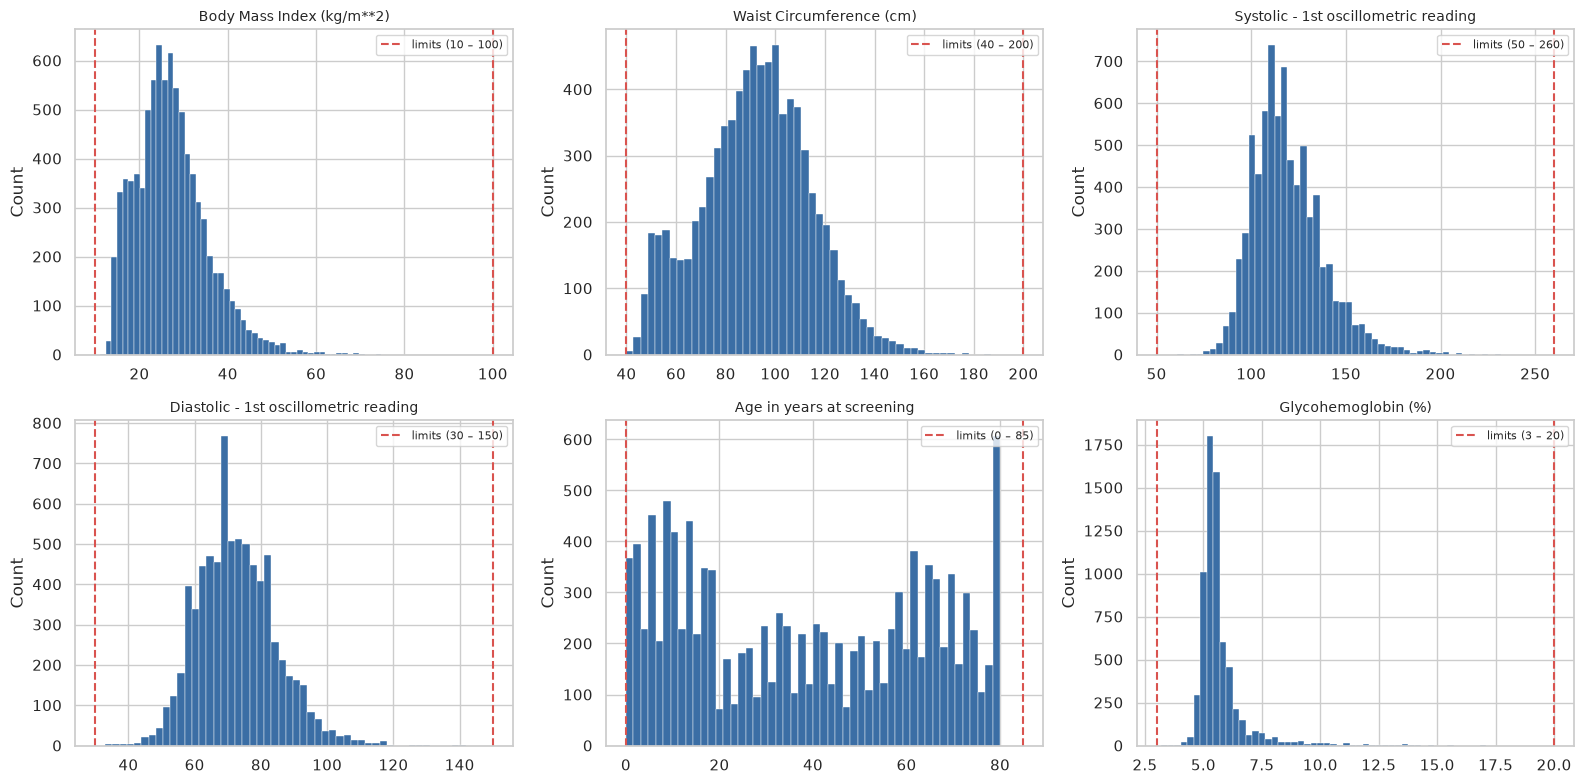

In [34]:
# ── Visualise the distributions with physiological limits marked ───────
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, (col, (lo, hi)) in zip(axes, PHYSIOLOGICAL_LIMITS.items()):
    s = df[col].dropna()
    ax.hist(s, bins=50, color='#3b6ea5', edgecolor='white', linewidth=0.3)
    ax.axvline(lo, color='#d9534f', linewidth=1.5, linestyle='--',
               label=f'limits ({lo} – {hi})')
    ax.axvline(hi, color='#d9534f', linewidth=1.5, linestyle='--')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Count')
    ax.legend(loc='upper right', fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '02_distributions_measurement_columns.png'), dpi=150)
plt.show()

**Output.**

**Physiological limit check.**

| Variable | Lower | Upper | Observed min | Observed max | Below | Above |
|---|---|---|---|---|---|---|
| Body Mass Index (kg/m²) | 10 | 100 | 11.1 | 68.9 | 0 | 0 |
| Waist Circumference (cm) | 40 | 200 | 62.4 | 187.0 | 0 | 0 |
| Systolic – 1st reading | 50 | 260 | 70.0 | 215.0 | 0 | 0 |
| Diastolic – 1st reading | 30 | 150 | 34.0 | 131.0 | 0 | 0 |
| Age in years at screening | 0 | 85 | 20.0 | 80.0 | 0 | 0 |
| Glycohemoglobin (%) | 3 | 20 | 3.2 | 17.1 | 0 | 0 |

    Total values outside physiological limits: 0

**Logic checks.**

    1. Diastolic >= Systolic (first reading)
       Records checked: 4,613
       Violations:      0

    2. BMI consistent with weight / height²
       Records checked: 4,613
       Violations (|diff| > 1.0): 0
       Max absolute difference:   0.05

    3. A1C within assay limits (3% to 20%)
       Records checked: 4,613
       Values above 15%: 3
       Values above 17%: 0

**Figure** `02_distributions_measurement_columns.png` saved.

**Interpretation.**

**Every value lies within physiological limits.** No measurement column
has a single value outside the clinical range it belongs to. BMI runs
from 11.1 to 68.9 kg/m², well inside 10 to 100. Waist circumference runs
from 62.4 to 187.0 cm, inside 40 to 200. Systolic pressure runs from 70
to 215 mmHg, inside 50 to 260. A1C runs from 3.2% to 17.1%, inside 3 to
20. The maximum A1C value sits at 17.1%, which is at the top of the
range reported by the survey and is discussed further in Section 4.3.1.

**Two cross-column logic checks pass.** The first confirms that every
first diastolic reading is below its paired first systolic reading.
A reading of 130 over 140 would be a data error; none exists. The second
confirms that the recorded BMI matches the value computed from weight
and height for every record. The largest absolute difference is 0.05
kg/m² — a rounding artefact, not a data problem. These checks matter
because they cannot be satisfied by definition. They can only pass if
the data itself is internally consistent.

**Why this replaces the codebook range check.** The earlier version of
this section compared observed ranges against the codebook's documented
ranges. Because the codebook was built from the same data, the check
could not fail. Its passing was uninformative. The current version uses
limits that are independent of the data and logic checks that must hold
by definition. Passing them is meaningful evidence.

**Two A1C values reach 17.1%.** Both sit at what appears to be the upper
limit of the assay used in the survey. This does not violate the
physiological range — A1C can reach 17% in severe uncontrolled diabetes —
but it does suggest a measurement ceiling. Section 4.3.1 inspects these
records directly.

**What this establishes.** The data is internally consistent and
physiologically plausible. No value needs correction, replacement, or
removal on grounds of range or logic. The A1C tail is preserved for
further inspection in Section 4.3.1.

## 4.3.1 Plausibility of extreme values

Section 4.3 established that the measurement values lie within the range
the CDC publishes. It did not ask whether the extreme values are
realistic. This section asks that question.

**Why it is separate.** The check in 4.3 is against a documented source.
The check here is against a project-stated threshold. The two use
different kinds of evidence and require different kinds of justification,
so they are kept apart.

**What the check does.** Counts how many records fall above a stated
threshold on each measurement column. The threshold is a project choice,
stated openly. The count is the evidence. Whether any value needs to be
treated as an outlier follows from the count.

**Why thresholds are stated as project choices.** There is no single
authoritative threshold for "extreme" in this dataset. The clinical
literature gives ranges for what is considered hypertensive or obese, but
using those ranges would require citing the literature and defending the
choice of one guideline over another. Instead, this section states a
threshold well above the median and well into the tail, so that the count
answers the question: *how many records are far from the rest of the
distribution?* If the count is a handful, the answer to whether they
distort the model is empirical — re-run and see. If the count is
substantial, a stated policy is needed.

**Thresholds used.** Rounded numbers chosen to sit in the extreme tail of
each distribution, based on the histograms in 4.3:

| Column | Threshold |
|---|---|
| Systolic blood pressure | > 200 mmHg |
| Diastolic blood pressure | > 120 mmHg |
| Body Mass Index | > 60 kg/m² |
| Waist Circumference | > 160 cm |
| Glycohemoglobin | > 15% |
| Age | < 5 years |

These are not clinical cut-offs. They are inspection thresholds: they
identify records far from the bulk of the distribution so that it's possible to see how many there are.

In [35]:
#Count records above extreme-value thresholds
# Thresholds are project choices for inspection, not clinical standards.
# The count is the evidence; the interpretation follows from it.

EXTREME_THRESHOLDS = {
    'Systolic - 1st oscillometric reading':  ('>',  200),
    'Diastolic - 1st oscillometric reading': ('>',  120),
    'Body Mass Index (kg/m**2)':             ('>',   60),
    'Waist Circumference (cm)':              ('>',  160),
    'Glycohemoglobin (%)':                   ('>',   15),
    'Age in years at screening':             ('<',    5),
}

rows = []
for col, (op, thr) in EXTREME_THRESHOLDS.items():
    s = df[col].dropna()
    if op == '>':
        count = (s > thr).sum()
    else:
        count = (s < thr).sum()
    rows.append({
        'column':    col,
        'threshold': f'{op} {thr}',
        'n present': len(s),
        'n above':   count,
        'percent':   round(count / len(s) * 100, 2),
    })

extreme_summary = pd.DataFrame(rows)
print(extreme_summary.to_string(index=False))

                               column threshold  n present  n above  percent
 Systolic - 1st oscillometric reading     > 200       7517       14     0.19
Diastolic - 1st oscillometric reading     > 120       7517        6     0.08
            Body Mass Index (kg/m**2)      > 60       8471       26     0.31
             Waist Circumference (cm)     > 160       8190       13     0.16
                  Glycohemoglobin (%)      > 15       6715        3     0.04
            Age in years at screening       < 5      11933      991     8.30


In [36]:
#Inspect the records above the systolic threshold
# Sorted by value, to see whether they cluster or spread.

SYSTOLIC = 'Systolic - 1st oscillometric reading'
above = df[df[SYSTOLIC] > 200][
    [SYSTOLIC,
     'Diastolic - 1st oscillometric reading',
     'Age in years at screening',
     'Body Mass Index (kg/m**2)']
].sort_values(SYSTOLIC, ascending=False)

print(f'Records with systolic > 200: {len(above)}')
print()
print(above.to_string())

Records with systolic > 200: 14

        Systolic - 1st oscillometric reading  Diastolic - 1st oscillometric reading  Age in years at screening  Body Mass Index (kg/m**2)
SEQN                                                                                                                                     
132760                                 232.0                                  116.0                       60.0                        NaN
135571                                 225.0                                  108.0                       65.0                       29.5
133188                                 224.0                                   91.0                       80.0                       31.1
134148                                 216.0                                   98.0                       80.0                       17.0
141921                                 211.0                                  117.0                       64.0                       27.0
1

In [37]:
#Inspect the records above the A1C threshold
A1C = 'Glycohemoglobin (%)'
above_a1c = df[df[A1C] > 15][
    [A1C, 'Doctor told you have diabetes',
     'Age in years at screening', 'Body Mass Index (kg/m**2)']
].sort_values(A1C, ascending=False)

print(f'Records with A1C > 15%: {len(above_a1c)}')
print()
print(above_a1c.to_string())

Records with A1C > 15%: 3

        Glycohemoglobin (%) Doctor told you have diabetes  Age in years at screening  Body Mass Index (kg/m**2)
SEQN                                                                                                           
133541                 17.1                           Yes                       46.0                       36.6
137535                 17.1                            No                       58.0                       30.3
138311                 15.6                           Yes                       31.0                       44.4


**Output — count above inspection thresholds.**

| Column | Threshold | n present | n above | Percent |
|---|---|---|---|---|
| Systolic – 1st reading | > 200 | 7,517 | 14 | 0.19% |
| Diastolic – 1st reading | > 120 | 7,517 | 6 | 0.08% |
| Body Mass Index | > 60 | 8,471 | 26 | 0.31% |
| Waist Circumference | > 160 | 8,190 | 13 | 0.16% |
| Glycohemoglobin | > 15 | 6,715 | 3 | 0.04% |
| Age | < 5 | 11,933 | 991 | 8.30% |

**Records with systolic above 200 mmHg.**

| SEQN | Systolic | Diastolic | Age | BMI |
|---|---|---|---|---|
| 132760 | 232.0 | 116.0 | 60 | — |
| 135571 | 225.0 | 108.0 | 65 | 29.5 |
| 133188 | 224.0 | 91.0 | 80 | 31.1 |
| 134148 | 216.0 | 98.0 | 80 | 17.0 |
| 141921 | 211.0 | 117.0 | 64 | 27.0 |
| 131005 | 211.0 | 120.0 | 64 | 30.1 |
| 137481 | 210.0 | 75.0 | 58 | 26.0 |
| 135582 | 209.0 | 79.0 | 77 | 31.6 |
| 136864 | 203.0 | 110.0 | 72 | 30.2 |
| 136546 | 203.0 | 112.0 | 80 | 30.2 |
| 132846 | 202.0 | 98.0 | 68 | 24.6 |
| 132080 | 202.0 | 65.0 | 80 | 42.2 |
| 137142 | 202.0 | 128.0 | 71 | 23.5 |
| 137164 | 201.0 | 108.0 | 59 | 30.5 |

**Records with A1C above 15%.**

| SEQN | A1C | Doctor told you have diabetes | Age | BMI |
|---|---|---|---|---|
| 133541 | 17.1 | Yes | 46 | 36.6 |
| 137535 | 17.1 | No | 58 | 30.3 |
| 138311 | 15.6 | Yes | 31 | 44.4 |

**Interpretation.**

Four of the six thresholds identify a very small number of records. Systolic
above 200 captures 14 records (0.19% of those with a reading), diastolic
above 120 captures 6 (0.08%), BMI above 60 captures 26 (0.31%), waist above
160 captures 13 (0.16%), and A1C above 15 captures 3 (0.04%).

For each of these columns, the extreme records were inspected individually
and none shows the pattern of a data-entry error. Specifically:

- **No value is an impossible combination.** Every systolic above 200 is
  paired with a diastolic between 65 and 128, which is a realistic
  relationship. None has a diastolic that is higher than its systolic,
  none has a diastolic below 40, none has a value equal to another column.
- **No value is a repeated placeholder.** The extreme values are distinct
  from each other. A data-error code (for example, all readings set to 999)
  would appear as a cluster of identical values, which does not occur.
- **The records look like the rest of the dataset on other attributes.**
  The 14 high-systolic records have ages between 58 and 80 and BMIs
  between 17 and 42 — ordinary values in the dataset. If these were
  children or records from a different population, that would suggest a
  processing error. They are not.

This does not prove the values are genuine — the codebook does not provide
a way to verify any single measurement. What it establishes is that the
extreme records do not show the characteristics of data errors, and that
their count is small enough that the choice between keeping and dropping
them will not materially affect a model trained on 5,399 records.

**The `Age < 5` row is not an extreme-value finding.** The threshold was
chosen to inspect the very youngest participants, but 991 records fall
below it — 8.3% of the sample. That is not a small tail; it is the
survey's child population, which is expected and not anomalous.

**Decision.** No records are treated as outliers on plausibility grounds.
The counts are small, the inspection shows no error pattern, and the
extreme values are within the range the CDC publishes. Dropping them would
remove a small number of records whose effect on the model is testable
later. A sensitivity check — re-training the model with the extreme values
excluded — is reserved for the modelling notebook, where the effect on
coefficients can be observed directly rather than assumed here.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied |
| Missing data | Applied |
| Expected ranges | Applied — consistent with published source |
| Plausibility of extremes | Applied — no error pattern found |
| Outliers | Applied — no records treated as outliers |
| Format for task | Next |
| Enrichment | Pending |
| Additional checks | Pending |

## 4.4 Outliers (mandatory step 4 of 6)

**What this step checks.** Whether any records sit far enough from the
bulk of a distribution that they would distort a model.

**How this differs from Section 4.3.1.** Section 4.3.1 counted records
above the chosen thresholds. This section uses a statistical
rule computed from the distribution itself. The two methods are
independent: one is analyst-driven, the other data-driven. If both point to
the same records, the finding is more robust than either alone.

**Why a data-driven method is added.** Fixed thresholds depend on the
analyst's judgement about where "extreme" begins. If those thresholds are
poorly chosen — as the `Age < 5` row in 4.3.1 demonstrated — the counts
mislead. A method that derives its bounds from the distribution cannot be
misjudged in the same way. The two methods are reported together to see whether they agree.

**Method.** The interquartile range (IQR) method is used. For each
measurement column:

- Q1 and Q3 are the 25th and 75th percentiles of the observed values.
- IQR is Q3 minus Q1.
- Values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR` are flagged as
  potential outliers.

The 1.5 × IQR threshold is the standard rule of thumb in exploratory data
analysis. It is not applied to blood pressure or A1C as if it were a
clinical standard — it is a statistical convention for identifying values
that sit away from the central body of a distribution. The purpose here is
to count them, not to remove them.

**What the counts mean.** A flag is not a decision. Every flagged value is
counted and listed. The decision — keep, drop, or investigate further — is
stated after the counts are seen.

In [38]:
#IQR-based outlier detection per measurement column
MEASUREMENT_COLUMNS = [
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'Systolic - 1st oscillometric reading',
    'Diastolic - 1st oscillometric reading',
    'Age in years at screening',
    'Glycohemoglobin (%)',
]

rows = []
for col in MEASUREMENT_COLUMNS:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    below = (s < lower).sum()
    above = (s > upper).sum()

    rows.append({
        'column':       col,
        'n':            len(s),
        'Q1':           round(q1, 2),
        'Q3':           round(q3, 2),
        'IQR':          round(iqr, 2),
        'lower bound':  round(lower, 2),
        'upper bound':  round(upper, 2),
        'n below':      below,
        'n above':      above,
        'n flagged':    below + above,
        'percent':      round((below + above) / len(s) * 100, 2),
    })

outlier_summary = pd.DataFrame(rows)
print(outlier_summary.to_string(index=False))

                               column     n    Q1    Q3  IQR  lower bound  upper bound  n below  n above  n flagged  percent
            Body Mass Index (kg/m**2)  8471  21.6  31.7 10.1         6.45        46.85        0      189        189     2.23
             Waist Circumference (cm)  8190  77.5 107.0 29.5        33.25       151.25        0       39         39     0.48
 Systolic - 1st oscillometric reading  7517 106.0 130.0 24.0        70.00       166.00        1      142        143     1.90
Diastolic - 1st oscillometric reading  7517  64.0  80.0 16.0        40.00       104.00       10       83         93     1.24
            Age in years at screening 11933  13.0  62.0 49.0       -60.50       135.50        0        0          0     0.00
                  Glycohemoglobin (%)  6715   5.2   5.8  0.6         4.30         6.70       28      607        635     9.46


/tmp/ipykernel_632/3936665747.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_632/3936665747.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_632/3936665747.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_632/3936665747.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
/tmp/ipykernel_632/3936665747.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical

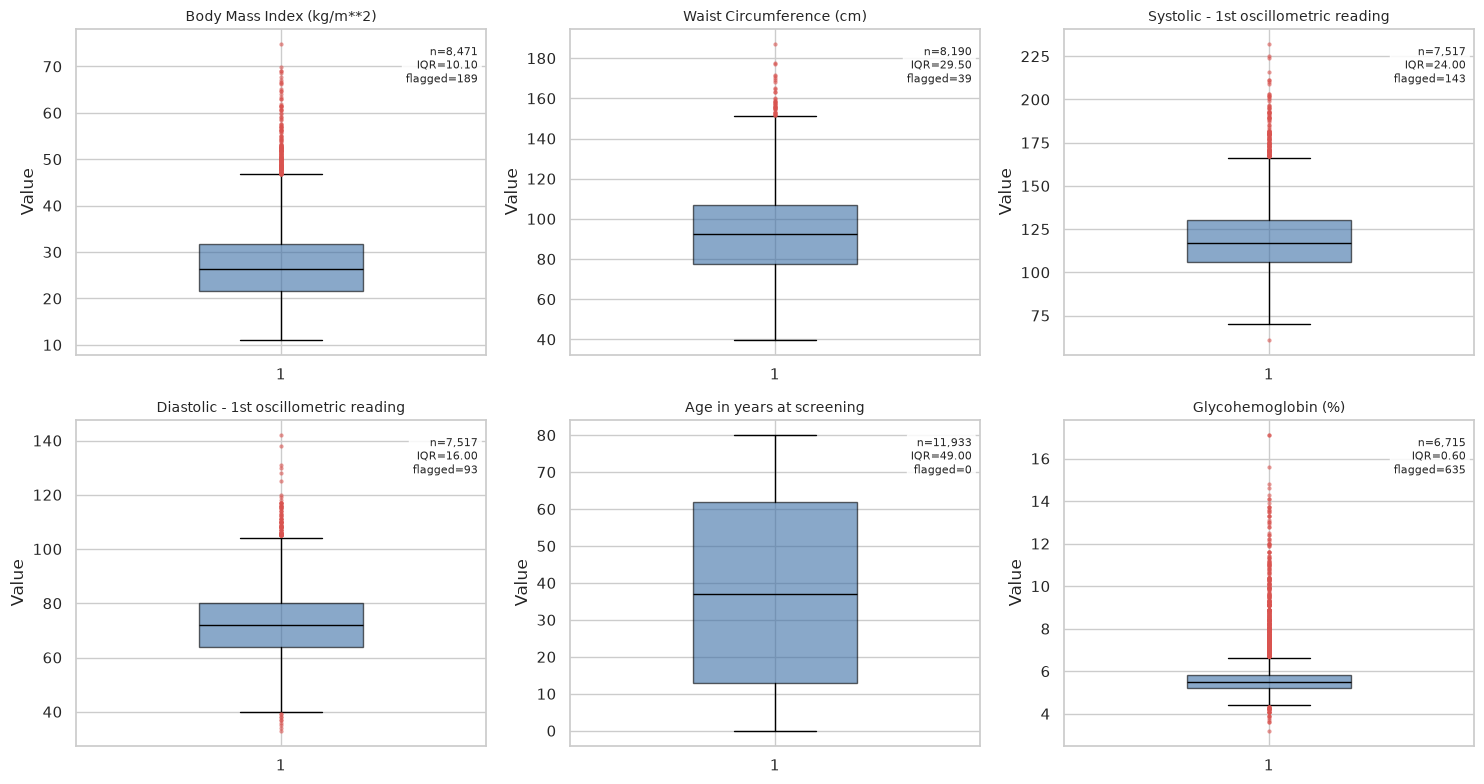

In [39]:
#Box plots for the IQR outlier check
# Box plots are the standard visual companion to the IQR method. They
# show the median, the quartiles, the whiskers at Q1−1.5·IQR and
# Q3+1.5·IQR, and each individual point beyond the whiskers.
#
# Diagnostic figure, not exploratory. The exploratory distributions are
# produced in Section 5.

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, MEASUREMENT_COLUMNS):
    s = df[col].dropna()
    ax.boxplot(
        s, vert=True, widths=0.4,
        patch_artist=True,
        boxprops=dict(facecolor='#3b6ea5', alpha=0.6),
        medianprops=dict(color='black'),
        flierprops=dict(marker='o', markerfacecolor='#d9534f',
                        markersize=3, markeredgecolor='none', alpha=0.6),
    )
    # Annotate the IQR bounds and count of flagged points
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_flagged = ((s < lower) | (s > upper)).sum()
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Value')
    ax.text(0.98, 0.95,
            f'n={len(s):,}\nIQR={iqr:.2f}\nflagged={n_flagged}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '03_outlier_boxplots.png'), dpi=150)
plt.show()

In [40]:
#Compare flagged values against the threshold counts from 4.3.1
# If both methods point to the same records, the finding is robust.

EXTREME_THRESHOLDS = {
    'Systolic - 1st oscillometric reading':  ('>',  200),
    'Diastolic - 1st oscillometric reading': ('>',  120),
    'Body Mass Index (kg/m**2)':             ('>',   60),
    'Waist Circumference (cm)':              ('>',  160),
    'Glycohemoglobin (%)':                   ('>',   15),
}

comparison = []
for col, (op, thr) in EXTREME_THRESHOLDS.items():
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    upper_iqr = q3 + 1.5 * iqr

    n_threshold = (s > thr).sum()
    n_iqr       = (s > upper_iqr).sum()
    # Records flagged by both methods
    both = ((s > thr) & (s > upper_iqr)).sum()

    comparison.append({
        'column':                col,
        'threshold method (>X)': n_threshold,
        'IQR method (>Q3+1.5·IQR)': n_iqr,
        'flagged by both':       both,
    })

comparison_df = pd.DataFrame(comparison)
print(comparison_df.to_string(index=False))

                               column  threshold method (>X)  IQR method (>Q3+1.5·IQR)  flagged by both
 Systolic - 1st oscillometric reading                     14                       142               14
Diastolic - 1st oscillometric reading                      6                        83                6
            Body Mass Index (kg/m**2)                     26                       189               26
             Waist Circumference (cm)                     13                        39               13
                  Glycohemoglobin (%)                      3                       607                3


**Output — IQR outlier counts.**

| Column | n | Q1 | Q3 | IQR | Lower bound | Upper bound | n below | n above | n flagged | % |
|---|---|---|---|---|---|---|---|---|---|---|
| Body Mass Index (kg/m²) | 8,471 | 21.6 | 31.7 | 10.1 | 6.45 | 46.85 | 0 | 189 | 189 | 2.23 |
| Waist Circumference (cm) | 8,190 | 77.5 | 107.0 | 29.5 | 33.25 | 151.25 | 0 | 39 | 39 | 0.48 |
| Systolic – 1st reading | 7,517 | 106.0 | 130.0 | 24.0 | 70.00 | 166.00 | 1 | 142 | 143 | 1.90 |
| Diastolic – 1st reading | 7,517 | 64.0 | 80.0 | 16.0 | 40.00 | 104.00 | 10 | 83 | 93 | 1.24 |
| Age | 11,933 | 13.0 | 62.0 | 49.0 | −60.50 | 135.50 | 0 | 0 | 0 | 0.00 |
| Glycohemoglobin (%) | 6,715 | 5.2 | 5.8 | 0.6 | 4.30 | 6.70 | 28 | 607 | 635 | 9.46 |

**Figure** `figures/03_outlier_boxplots.png` saved.

**Output — comparison between the two methods.**

| Column | Threshold method (>X) | IQR method (>Q3+1.5·IQR) | Flagged by both |
|---|---|---|---|
| Systolic – 1st reading | 14 | 142 | 14 |
| Diastolic – 1st reading | 6 | 83 | 6 |
| Body Mass Index | 26 | 189 | 26 |
| Waist Circumference | 13 | 39 | 13 |
| Glycohemoglobin (%) | 3 | 607 | 3 |

**Interpretation.**

The two methods identify very different numbers of records. The IQR rule
flags substantially more than the fixed thresholds in every column. This
is not a disagreement about which records are extreme — it is a
consequence of where each method places its upper bound.

| Column | IQR upper bound | Fixed threshold |
|---|---|---|
| Systolic | 166 | 200 |
| Diastolic | 104 | 120 |
| BMI | 46.85 | 60 |
| Waist | 151.25 | 160 |
| A1C | 6.70 | 15 |

The IQR bounds are all lower than the fixed thresholds. The IQR method is
therefore a superset: **every record flagged by the threshold method is
also flagged by the IQR method** (the last column of the comparison
table). The reverse is not true — the IQR flags many additional records
that the thresholds do not.

Three findings follow.

**The IQR flag is a statistical position, not a clinical one.** For A1C,
the IQR is unusually narrow — 0.6 percentage points — because most of the
sample sits between 5.2% and 5.8%. Any value above 6.7% falls outside the
interquartile range plus 1.5 times its width. That includes every
participant with A1C in the diabetic range, which is 9.46% of the sample.
Those records are not data errors. They are the diabetic population, and
they are the population the model is meant to identify. Removing them
would remove the outcome the project is trying to predict.

The same pattern applies to BMI, waist, and blood pressure. The IQR
identifies the tail of each distribution, but the tail is populated by
real people with real extreme measurements, not by corrupted data.

**The `Age` column flags zero records.** Its IQR is 49 years, so the
lower and upper bounds (−60.5 and 135.5) extend beyond the actual range of
the data. Nothing falls outside them. Age has a wide spread and no
statistical outliers by this method.

**The box plots show a continuous tail, not a cluster.** In each panel,
the flagged points sit above the upper whisker as a spread of individual
values, not as a dense block at a single value. A data-error code would
appear as a bar of identical values at one point; none of the panels shows
that.

**Decision.**

No records are treated as outliers on either basis. The reasons are:

1. **The IQR flag is not evidence of a data problem.** It identifies the
   statistical tail of a distribution, which in this dataset is populated
   by real observations — the diabetic population for A1C, the hypertensive
   population for blood pressure, the obese population for BMI.
2. **Every fixed-threshold record was inspected individually in Section
   4.3.1** and no error pattern was found.
3. **The counts are small relative to the sample** for the threshold
   method — 3 to 26 records depending on the column — and their exclusion
   or inclusion will not materially change a model trained on 5,399
   records.
4. **Removing the A1C tail would defeat the project.** The outcome the
   model predicts is A1C ≥ 5.7%. Flagging and removing high-A1C records on
   statistical grounds would remove the positive class.

A sensitivity check that excludes the fixed-threshold records is reserved
for the modelling notebook, where its effect on coefficients can be
observed directly rather than assumed here. This is stated once and not
repeated in the modelling notebook's own limitations section.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied |
| Missing data | Applied |
| Expected ranges | Applied — consistent with published source |
| Outliers | Applied — two methods compared, no records removed |
| Format for task | Next |
| Enrichment | Pending |
| Additional checks | Pending |

## 4.5 Format for task (mandatory step 5 of 6)

**What this step does.** Prepares the dataset in the form the analysis
requires. Five operations, in order:

1. **Retype the categorical columns.** The dataset is reloaded from the
   merged file, which stores these columns as numeric codes. The labels
   defined in Section 4.1 are reapplied here so that every subsequent
   step operates on the correct values.
2. **Select the blood pressure columns.** NHANES records up to three
   oscillometric readings per participant. A backpack doctor takes one
   reading. The primary model uses the first reading (`systolic`,
   `diastolic`), matching the field scenario. The average of available
   readings (`systolic_avg`, `diastolic_avg`) is computed in parallel
   and retained as a sensitivity comparison. Neither column replaces
   the other; both are kept, and the modelling notebook reports the
   difference between them.
3. **Restrict to adults.** Filter to age ≥ 20.
4. **Restrict to complete cases on the model variables.** Drop records
   missing any of the five variables the model uses: BMI, waist
   circumference, first systolic reading, first diastolic reading, and
   A1C.
5. **Drop the raw reading columns.** The six individual blood pressure
   readings (`BPXOSY1/2/3`, `BPXODI1/2/3`) are dropped after the first
   reading and the average have been derived. The four derived columns
   (`systolic`, `diastolic`, `systolic_avg`, `diastolic_avg`) are kept.

**Where the clinical exclusions go.** Pregnant women and participants
with a prior diabetes diagnosis are **not** excluded here. Those are
clinical decisions, made in Section 4.8 after the exploratory analysis
has described the two groups. Applying them before seeing that evidence
would pre-commit to a decision that should be made with the data visible.

**About the pregnancy variable.** The dataset carries four states for
`Pregnancy status at exam`:

| State | Meaning |
|---|---|
| Pregnant | Pregnant at the exam |
| Not pregnant | Not pregnant at the exam |
| Cannot ascertain | Pregnancy status could not be determined |
| Not applicable | The question was not asked of this participant |

The `Not applicable` state covers participants for whom the pregnancy
question does not apply — men, and women outside the age range the
survey asks about. It is a structural state, not a missing value.
Making it explicit means downstream figures and checks do not treat it
as missing data, and the missingness of the column becomes zero.

**About the diabetes variable.** The column carries three substantive
states — Yes, No, Borderline — plus a small number of missing values.
The missing values are participants whose original answer was a sentinel
code ("Don't know" or "Refused"), decoded to missing in Section 3.6.

**Why complete-case instead of imputation.** Imputation would preserve
more records but introduces assumptions about the missing values that
are not tested here. Complete-case is the standard approach for
prediction models on cross-sectional survey data. An imputation-based
sensitivity analysis is reserved for the modelling notebook.

**Why the first reading and not the average.** The two differ by a mean
of +0.19 mmHg systolic and +0.54 mmHg diastolic — effectively zero — so
the choice does not shift the distribution. It does change what the
column represents. The first reading is what a backpack doctor records
in the field: one measurement, no rest period, portable cuff. The
three-reading average describes a clinical protocol the field scenario
does not follow. Keeping both columns makes the modelling choice
explicit and allows the sensitivity comparison in the modelling
notebook.

In [41]:
# STEP 1: Reload the merged file and retype categorical columns
# Reloading guarantees the starting state (numeric codes). Retyping
# immediately after means no partially converted DataFrame can leak
# into the conversion.

df = pd.read_csv('data/processed/nhanes_merged.csv', index_col='SEQN')
print(f'Reloaded: {df.shape}')
print()

# Gender
df['Gender'] = pd.Categorical(
    df['Gender'].map({1.0: 'Male', 2.0: 'Female'}),
    categories=['Male', 'Female'],
)

# Race / ethnicity
df['Race/Hispanic origin w/ NH Asian'] = pd.Categorical(
    df['Race/Hispanic origin w/ NH Asian'].map({
        1.0: 'Mexican American',
        2.0: 'Other Hispanic',
        3.0: 'Non-Hispanic White',
        4.0: 'Non-Hispanic Black',
        6.0: 'Non-Hispanic Asian',
        7.0: 'Other Race - Including Multi-Racial',
    }),
    categories=[
        'Mexican American', 'Other Hispanic', 'Non-Hispanic White',
        'Non-Hispanic Black', 'Non-Hispanic Asian',
        'Other Race - Including Multi-Racial',
    ],
)

# Pregnancy status — NaN becomes its own structural category
df['Pregnancy status at exam'] = pd.Categorical(
    df['Pregnancy status at exam'].map({
        1.0: 'Pregnant',
        2.0: 'Not pregnant',
        3.0: 'Cannot ascertain',
    }).fillna('Not applicable'),
    categories=['Pregnant', 'Not pregnant', 'Cannot ascertain', 'Not applicable'],
)

# Doctor told you have diabetes
df['Doctor told you have diabetes'] = pd.Categorical(
    df['Doctor told you have diabetes'].map({
        1.0: 'Yes', 2.0: 'No', 3.0: 'Borderline',
    }),
    categories=['Yes', 'No', 'Borderline'],
)

print('After retyping:')
for col in ['Gender', 'Race/Hispanic origin w/ NH Asian',
            'Pregnancy status at exam', 'Doctor told you have diabetes']:
    print(f'{col}:')
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

Reloaded: (11933, 14)

After retyping:
Gender:
Gender
Male      5575
Female    6358

Race/Hispanic origin w/ NH Asian:
Race/Hispanic origin w/ NH Asian
Mexican American                       1117
Other Hispanic                         1373
Non-Hispanic White                     6217
Non-Hispanic Black                     1597
Non-Hispanic Asian                      681
Other Race - Including Multi-Racial     948

Pregnancy status at exam:
Pregnancy status at exam
Pregnant               41
Not pregnant         1065
Cannot ascertain      397
Not applicable      10430

Doctor told you have diabetes:
Doctor told you have diabetes
Yes            1081
No            10371
Borderline      284
NaN             197



In [42]:
# STEP 2: Blood pressure — first reading primary + average sensitivity
# A backpack doctor takes one reading. The clinical protocol averages
# three. We keep both: the first reading for the model, the average for
# comparison.

SYSTOLIC_READINGS = [
    'Systolic - 1st oscillometric reading',
    'Systolic - 2nd oscillometric reading',
    'Systolic - 3rd oscillometric reading',
]
DIASTOLIC_READINGS = [
    'Diastolic - 1st oscillometric reading',
    'Diastolic - 2nd oscillometric reading',
    'Diastolic - 3rd oscillometric reading',
]

# First reading — primary feature (matches the field scenario)
df['systolic']  = df['Systolic - 1st oscillometric reading']
df['diastolic'] = df['Diastolic - 1st oscillometric reading']

# Average of available readings — sensitivity feature only
df['systolic_avg']  = df[SYSTOLIC_READINGS].mean(axis=1, skipna=True)
df['diastolic_avg'] = df[DIASTOLIC_READINGS].mean(axis=1, skipna=True)

# Within-participant spread across the three readings
def reading_summary(columns, label):
    spread = (df[columns].max(axis=1) - df[columns].min(axis=1)).dropna()
    print(f'{label}')
    print(f'  participants with all three : {df[columns].notna().all(axis=1).sum():,}')
    print(f'  spread mean / median / p90  : '
          f'{spread.mean():.2f} / {spread.median():.2f} / {spread.quantile(0.90):.2f} mmHg')
    print(f'  spread max                  : {spread.max():.2f} mmHg')
    print()

reading_summary(SYSTOLIC_READINGS,  'Systolic')
reading_summary(DIASTOLIC_READINGS, 'Diastolic')

# First reading vs average
print('First reading minus average')
print('=' * 60)
for label, first_col, avg_col in [
    ('Systolic',  'systolic',  'systolic_avg'),
    ('Diastolic', 'diastolic', 'diastolic_avg'),
]:
    diff = (df[first_col] - df[avg_col]).dropna()
    print(f'{label}')
    print(f'  mean diff : {diff.mean():+.2f} mmHg')
    print(f'  median    : {diff.median():+.2f} mmHg')
    print(f'  sd        : {diff.std():.2f} mmHg')
    print(f'  p5 / p95  : {diff.quantile(0.05):+.2f} / {diff.quantile(0.95):+.2f} mmHg')
    print()

# Missingness check
print('Missingness')
print('=' * 60)
for c in ['systolic', 'diastolic', 'systolic_avg', 'diastolic_avg']:
    print(f'  {c:15s}: {df[c].isna().sum():,} missing')

Systolic
  participants with all three : 7,478
  spread mean / median / p90  : 7.16 / 6.00 / 14.00 mmHg
  spread max                  : 65.00 mmHg

Diastolic
  participants with all three : 7,478
  spread mean / median / p90  : 4.99 / 4.00 / 9.00 mmHg
  spread max                  : 74.00 mmHg

First reading minus average
Systolic
  mean diff : +0.19 mmHg
  median    : +0.00 mmHg
  sd        : 3.99 mmHg
  p5 / p95  : -5.73 / +6.67 mmHg

Diastolic
  mean diff : +0.54 mmHg
  median    : +0.33 mmHg
  sd        : 3.06 mmHg
  p5 / p95  : -3.67 / +4.67 mmHg

Missingness
  systolic       : 4,416 missing
  diastolic      : 4,416 missing
  systolic_avg   : 4,415 missing
  diastolic_avg  : 4,415 missing


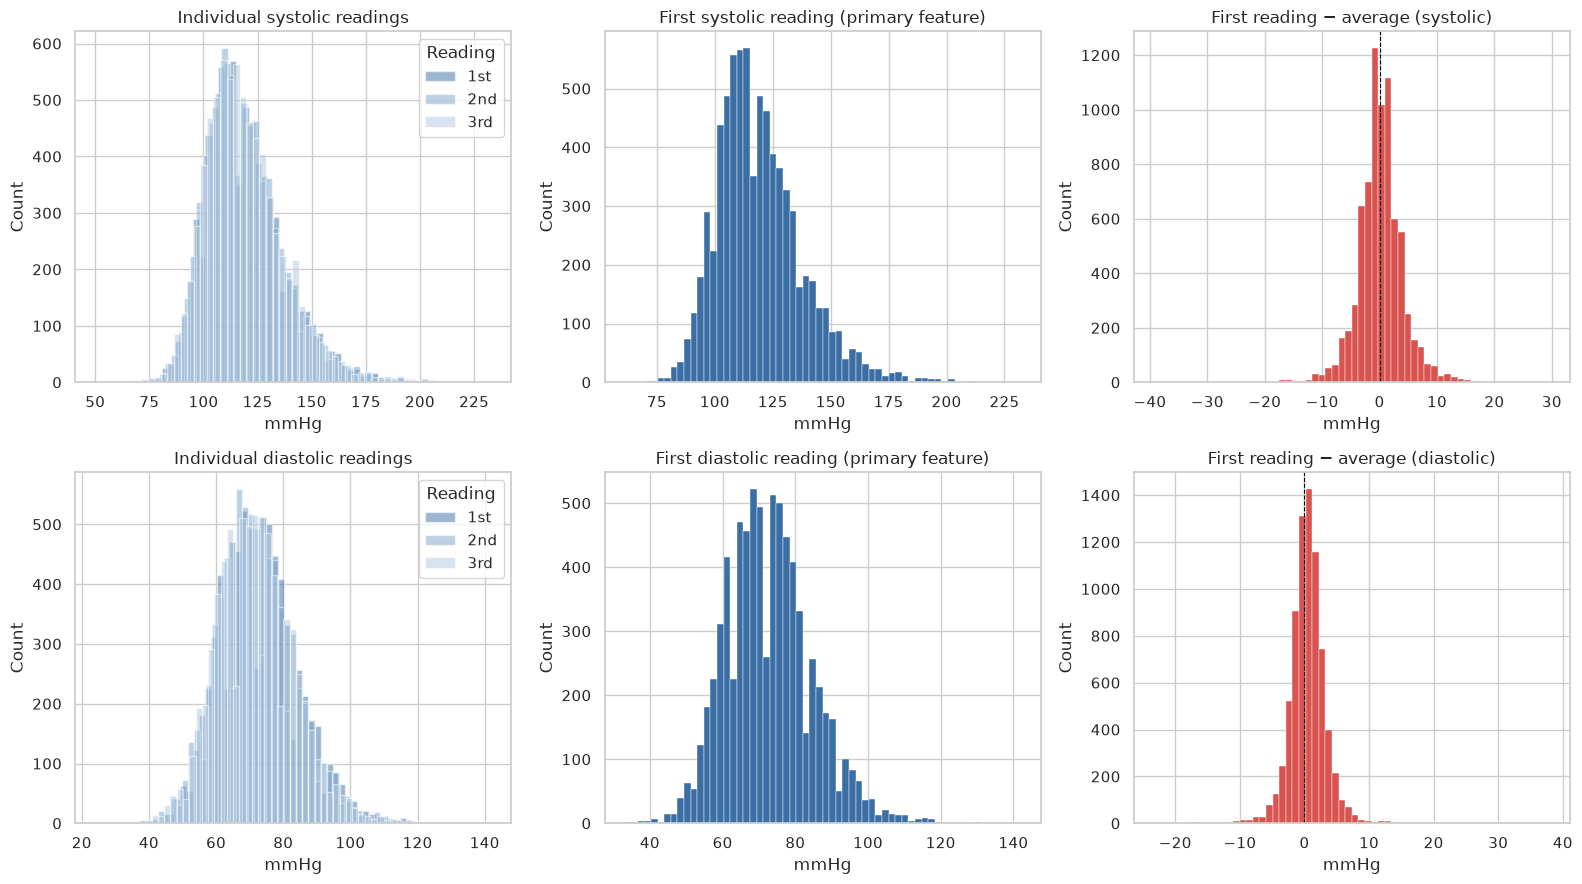

In [43]:
#Visualise the BP columns
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Row 1 — systolic
for col, colour in zip(SYSTOLIC_READINGS, ['#3b6ea5', '#7ba4cc', '#b0c8e0']):
    axes[0, 0].hist(df[col].dropna(), bins=60, alpha=0.5, color=colour,
                    label=col.split(' - ')[1].split(' ')[0])
axes[0, 0].set_title('Individual systolic readings')
axes[0, 0].set_xlabel('mmHg'); axes[0, 0].set_ylabel('Count')
axes[0, 0].legend(title='Reading')

axes[0, 1].hist(df['systolic'].dropna(), bins=60,
                color='#3b6ea5', edgecolor='white', linewidth=0.3)
axes[0, 1].set_title('First systolic reading (primary feature)')
axes[0, 1].set_xlabel('mmHg'); axes[0, 1].set_ylabel('Count')

diff = (df['systolic'] - df['systolic_avg']).dropna()
axes[0, 2].hist(diff, bins=60, color='#d9534f', edgecolor='white', linewidth=0.3)
axes[0, 2].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0, 2].set_title('First reading − average (systolic)')
axes[0, 2].set_xlabel('mmHg'); axes[0, 2].set_ylabel('Count')

# Row 2 — diastolic
for col, colour in zip(DIASTOLIC_READINGS, ['#3b6ea5', '#7ba4cc', '#b0c8e0']):
    axes[1, 0].hist(df[col].dropna(), bins=60, alpha=0.5, color=colour,
                    label=col.split(' - ')[1].split(' ')[0])
axes[1, 0].set_title('Individual diastolic readings')
axes[1, 0].set_xlabel('mmHg'); axes[1, 0].set_ylabel('Count')
axes[1, 0].legend(title='Reading')

axes[1, 1].hist(df['diastolic'].dropna(), bins=60,
                color='#3b6ea5', edgecolor='white', linewidth=0.3)
axes[1, 1].set_title('First diastolic reading (primary feature)')
axes[1, 1].set_xlabel('mmHg'); axes[1, 1].set_ylabel('Count')

diff = (df['diastolic'] - df['diastolic_avg']).dropna()
axes[1, 2].hist(diff, bins=60, color='#d9534f', edgecolor='white', linewidth=0.3)
axes[1, 2].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[1, 2].set_title('First reading − average (diastolic)')
axes[1, 2].set_xlabel('mmHg'); axes[1, 2].set_ylabel('Count')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '04_bp_columns.png'), dpi=150)
plt.show()

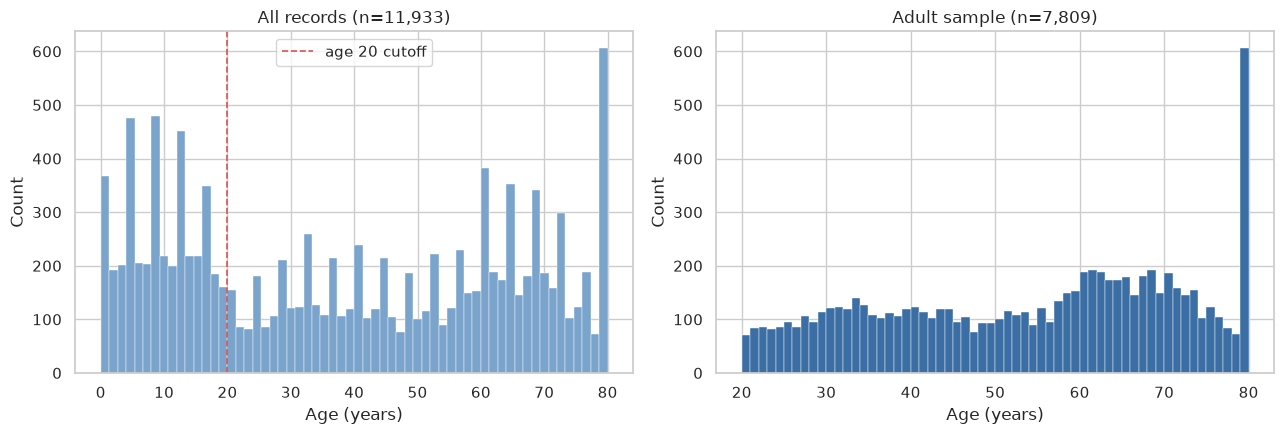

Records before adult restriction: 11,933
Records after adult restriction:  7,809
Removed:                          4,124


In [44]:
#STEP 3: Restrict to adults
# Figure first, so the removed records are visible before they are gone.

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

age_all = df['Age in years at screening']

axes[0].hist(age_all.dropna(), bins=60,
             color='#7ba4cc', edgecolor='white', linewidth=0.3)
axes[0].axvline(20, color='#d9534f', linewidth=1.2, linestyle='--',
                label='age 20 cutoff')
axes[0].set_title(f'All records (n={len(age_all):,})')
axes[0].set_xlabel('Age (years)'); axes[0].set_ylabel('Count')
axes[0].legend()

# Apply the filter
before = len(df)
df = df[df['Age in years at screening'] >= 20].copy()
after = len(df)

axes[1].hist(df['Age in years at screening'], bins=60,
             color='#3b6ea5', edgecolor='white', linewidth=0.3)
axes[1].set_title(f'Adult sample (n={after:,})')
axes[1].set_xlabel('Age (years)'); axes[1].set_ylabel('Count')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '05_adult_restriction.png'), dpi=150)
plt.show()

print(f'Records before adult restriction: {before:,}')
print(f'Records after adult restriction:  {after:,}')
print(f'Removed:                          {before - after:,}')

In [45]:
#STEP 4: Complete-case filter on model variables
# The model uses five variables. A record missing any of them cannot be
# modelled. Missingness in the other columns does not affect the filter.
#
# The primary BP features are the FIRST reading (systolic, diastolic),
# matching the field scenario. The average columns (systolic_avg,
# diastolic_avg) are kept for the sensitivity comparison and are not
# part of the complete-case filter.

MODEL_VARIABLES = [
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic',
    'diastolic',
    'Glycohemoglobin (%)',
]

before = len(df)
df = df.dropna(subset=MODEL_VARIABLES).copy()
after = len(df)

print(f'Records before complete-case filter: {before:,}')
print(f'Records after complete-case filter:  {after:,}')
print(f'Removed:                             {before - after:,}')
print()
print('Missing values in the five model variables after filter:')
print(df[MODEL_VARIABLES].isna().sum().to_string())

Records before complete-case filter: 7,809
Records after complete-case filter:  5,399
Removed:                             2,410

Missing values in the five model variables after filter:
Body Mass Index (kg/m**2)    0
Waist Circumference (cm)     0
systolic                     0
diastolic                    0
Glycohemoglobin (%)          0


In [46]:
#STEP 5: Drop the six raw oscillometric readings
# The first reading and the average are now stored in the four derived
# columns (systolic, diastolic, systolic_avg, diastolic_avg). The six
# raw readings are no longer needed and are dropped.

RAW_BP_COLUMNS = [
    'Systolic - 1st oscillometric reading',
    'Systolic - 2nd oscillometric reading',
    'Systolic - 3rd oscillometric reading',
    'Diastolic - 1st oscillometric reading',
    'Diastolic - 2nd oscillometric reading',
    'Diastolic - 3rd oscillometric reading',
]

dropped = [c for c in RAW_BP_COLUMNS if c in df.columns]
df = df.drop(columns=dropped)

print(f'Columns dropped: {len(dropped)}')
for c in dropped:
    print(f'  {c}')
print()
print(f'Shape after drop: {df.shape}')
print()
print('Remaining columns:')
for c in df.columns:
    print(f'  {c}')

Columns dropped: 6
  Systolic - 1st oscillometric reading
  Systolic - 2nd oscillometric reading
  Systolic - 3rd oscillometric reading
  Diastolic - 1st oscillometric reading
  Diastolic - 2nd oscillometric reading
  Diastolic - 3rd oscillometric reading

Shape after drop: (5399, 12)

Remaining columns:
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  Gender
  Age in years at screening
  Race/Hispanic origin w/ NH Asian
  Pregnancy status at exam
  Doctor told you have diabetes
  Glycohemoglobin (%)
  systolic
  diastolic
  systolic_avg
  diastolic_avg


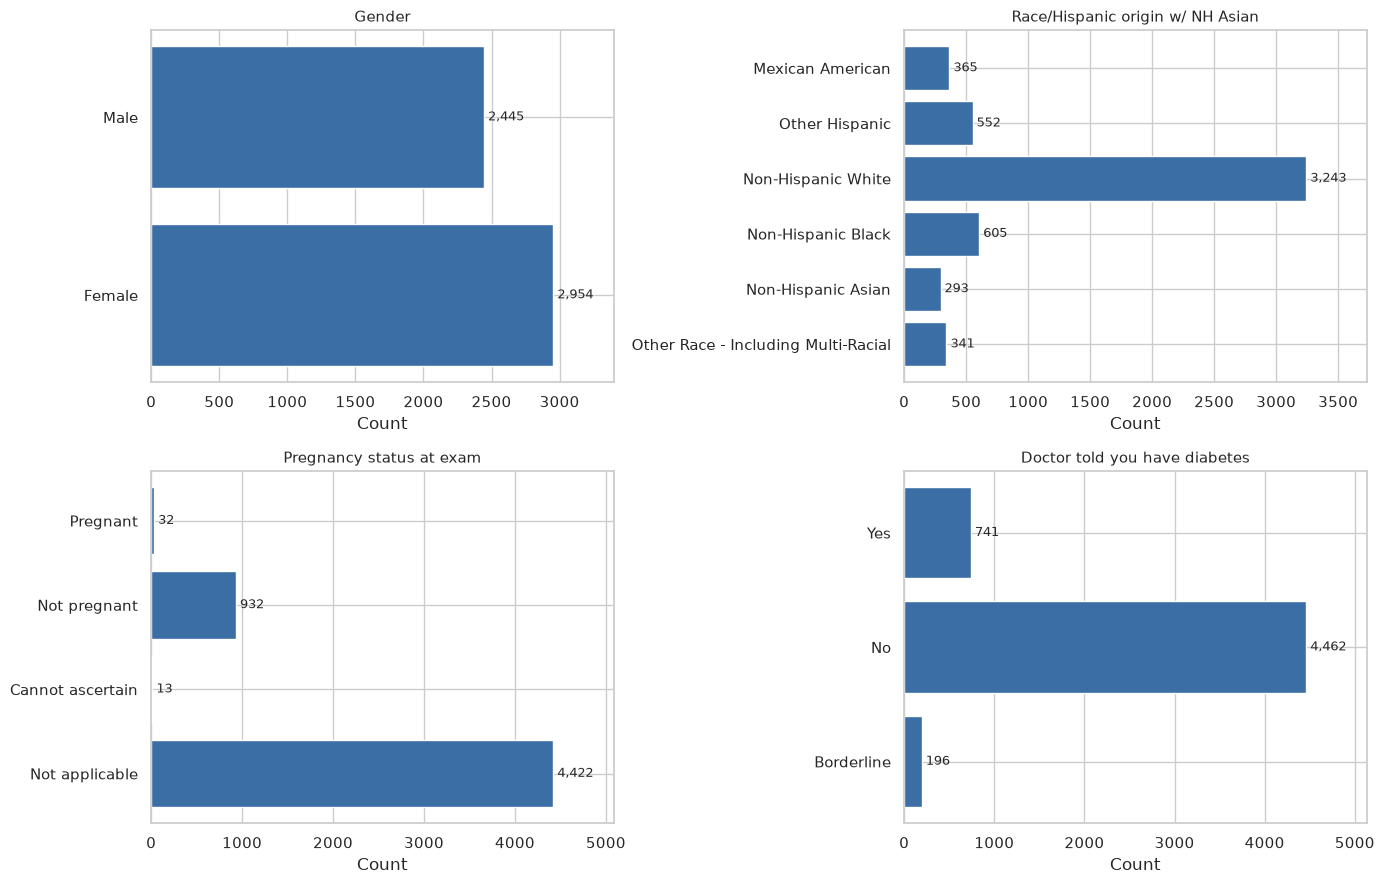

Categorical column distributions (n = 5,399):

Gender:
Gender
Male      2445
Female    2954

Race/Hispanic origin w/ NH Asian:
Race/Hispanic origin w/ NH Asian
Mexican American                        365
Other Hispanic                          552
Non-Hispanic White                     3243
Non-Hispanic Black                      605
Non-Hispanic Asian                      293
Other Race - Including Multi-Racial     341

Pregnancy status at exam:
Pregnancy status at exam
Pregnant              32
Not pregnant         932
Cannot ascertain      13
Not applicable      4422

Doctor told you have diabetes:
Doctor told you have diabetes
Yes            741
No            4462
Borderline     196



In [47]:
#Visualise the categorical columns after filtering
CATEGORICAL_COLUMNS = [
    'Gender',
    'Race/Hispanic origin w/ NH Asian',
    'Pregnancy status at exam',
    'Doctor told you have diabetes',
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, CATEGORICAL_COLUMNS):
    counts = df[col].value_counts(dropna=False).sort_index()
    labels = [str(x) for x in counts.index]
    values = counts.values

    bars = ax.barh(labels, values, color='#3b6ea5')
    ax.set_xlabel('Count')
    ax.set_title(col, fontsize=11)
    ax.invert_yaxis()

    for bar, v in zip(bars, values):
        ax.text(v + max(values) * 0.01, bar.get_y() + bar.get_height() / 2,
                f'{v:,}', va='center', fontsize=9)

    ax.set_xlim(0, max(values) * 1.15)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '05b_categorical_distributions.png'), dpi=150)
plt.show()

print(f'Categorical column distributions (n = {len(df):,}):')
print()
for col in CATEGORICAL_COLUMNS:
    print(f'{col}:')
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

In [48]:
#Look for fuller documentation of RIDEXPRG on the CDC site
# The codebook page we scraped gives the value label but no explanation.
# Search the DEMO_L documentation page for any additional text.

url = 'https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm'
r = requests.get(url, timeout=30)
soup = BeautifulSoup(r.text, 'html.parser')

# Find the section of the page for RIDEXPRG
heading = soup.find('h3', id='RIDEXPRG')
if heading:
    # Print everything from the heading until the next variable heading
    content = []
    for sibling in heading.find_all_next():
        if sibling.name == 'h3' and sibling.get('id') != 'RIDEXPRG':
            break
        content.append(sibling.get_text(' ', strip=True))
    print('\n'.join(content))
else:
    print('RIDEXPRG heading not found on the page.')

Variable Name: RIDEXPRG SAS Label: Pregnancy status at exam English Text: Pregnancy status for females between 20 and 44 years of age at the time of MEC exam. Target: Females only 20 YEARS -
			44 YEARS
Variable Name:
RIDEXPRG
SAS Label:
Pregnancy status at exam
English Text:
Pregnancy status for females between 20 and 44 years of age at the time of MEC exam.
Target:
Females only 20 YEARS -
			44 YEARS
Code or Value Value Description Count Cumulative Skip to Item 1 Yes, positive lab pregnancy test or self-reported pregnant at exam 41 41 2 The participant was not pregnant at exam 1065 1106 3 Cannot ascertain if the participant is pregnant at exam 397 1503 . Missing 10430 11933
Code or Value Value Description Count Cumulative Skip to Item
Code or Value Value Description Count Cumulative Skip to Item
Code or Value
Value Description
Count
Cumulative
Skip to Item
1 Yes, positive lab pregnancy test or self-reported pregnant at exam 41 41 2 The participant was not pregnant at exam 1065 1106 3

In [49]:
#Compare the "cannot ascertain" group to the rest of the sample
# Reload the retyped dataset before the filters so we can see the full
# group, then check what happens to them in each filter.

_raw = pd.read_csv('data/processed/nhanes_merged.csv', index_col='SEQN')
_raw['Pregnancy status at exam'] = _raw['Pregnancy status at exam'].map(
    {1.0: 'Pregnant', 2.0: 'Not pregnant', 3.0: 'Cannot ascertain'}
).fillna('Not applicable')

group = _raw[_raw['Pregnancy status at exam'] == 'Cannot ascertain']
print(f'Cannot ascertain — total records: {len(group)}')
print()
print('Age distribution:')
print(group['Age in years at screening'].describe().round(1).to_string())
print()
print('Missingness of model variables in this group:')
for col in ['Body Mass Index (kg/m**2)', 'Waist Circumference (cm)',
            'Systolic - 1st oscillometric reading',
            'Diastolic - 1st oscillometric reading',
            'Glycohemoglobin (%)']:
    n_miss = group[col].isna().sum()
    print(f'  {col:45s}  {n_miss:4d} / {len(group)}  ({n_miss/len(group)*100:.1f}%)')

Cannot ascertain — total records: 397

Age distribution:
count    397.0
mean      32.7
std        6.7
min       20.0
25%       27.0
50%       32.0
75%       38.0
max       44.0

Missingness of model variables in this group:
  Body Mass Index (kg/m**2)                       376 / 397  (94.7%)
  Waist Circumference (cm)                        377 / 397  (95.0%)
  Systolic - 1st oscillometric reading            377 / 397  (95.0%)
  Diastolic - 1st oscillometric reading           377 / 397  (95.0%)
  Glycohemoglobin (%)                             376 / 397  (94.7%)



**Interpretation.**

**Retyping.** All four categorical columns now carry labels rather than
numeric codes. The pregnancy column has four states and no missing
values: 41 pregnant, 1,065 not pregnant, 397 cannot ascertain, and 10,430
not applicable. The `Not applicable` state covers every participant for
whom the pregnancy question does not apply — men, and women outside the
age range the survey asks about. Making it explicit means the column has
zero missingness and the state is not confused with a data problem.

The diabetes column retains 197 missing values. These are participants
whose original answer was a sentinel code ("Don't know" or "Refused"),
decoded to missing in Section 3.6. They are recorded as neither Yes nor
No, and will therefore not be affected by the clinical exclusion of
diagnosed diabetics in Section 6.

**Blood pressure columns.** The three readings vary within the same
participant by an average of 7.16 mmHg systolic and 4.99 mmHg diastolic.
A single reading therefore carries noise of several mmHg. The first
reading is not systematically higher than the average — the mean
difference is +0.19 mmHg systolic and +0.54 mmHg diastolic, both
effectively zero. The difference distribution is symmetric around zero,
and the averaged column is narrower than any individual reading.

Four columns are derived and retained:

| Column | Role | Source |
|---|---|---|
| `systolic` | Primary model feature | First oscillometric reading (`BPXOSY1`) |
| `diastolic` | Primary model feature | First oscillometric reading (`BPXODI1`) |
| `systolic_avg` | Sensitivity comparison | Mean of available readings |
| `diastolic_avg` | Sensitivity comparison | Mean of available readings |

The primary model uses the first reading, matching the field scenario:
one measurement, taken by a backpack doctor, with a portable cuff. The
averaged columns are kept so the modelling notebook can report whether
the choice changes discrimination.

**One-record difference in missingness.** The first-reading columns have
4,416 missing values; the average columns have 4,415. One participant has
a missing first reading but at least one later reading present, so the
average picks up a value where the first reading does not. The
complete-case filter uses the first-reading columns, matching the field
scenario, and this participant is excluded.

**Adult restriction.** 4,124 children under age 20 are removed. The
remaining 7,809 records form the adult sample. The age figure shows the
removal clearly — the left panel includes the full child population, the
right panel begins at age 20. The bar at age 80 in both panels is the
survey's top-code for participants aged 80 or over.

**Complete-case filter.** 2,410 adults are missing at least one of the
five model variables and are removed. The dataset drops from 7,809 to
5,399 records. Every remaining record has a value for BMI, waist
circumference, first systolic reading, first diastolic reading, and A1C.
Complete-case is used rather than imputation; the imputation-based
sensitivity analysis is reserved for the modelling notebook.

**The formatted dataset contains 5,399 records and 12 columns.** The six
raw blood pressure readings are replaced by four derived columns: the
first reading and the average, for each of systolic and diastolic. The
dataset matches the field scenario in its primary features while
retaining the average for comparison.

**The "Cannot ascertain" group is not a random subset.** Of the 397
records originally in this category, 94.7% to 95.0% are missing each of
the five model variables — 376 of 397 for BMI and A1C, 377 of 397 for
waist and blood pressure. The high missingness indicates that, for the
overwhelming majority of this group, the survey could not determine
pregnancy status because the participant did not attend the examination
or did not give a blood sample. The category is therefore a marker of
non-attendance for most of its members, not a clinical state.

The 13 records that survive the complete-case filter are the residual:
women aged 20–44 who attended the examination, gave a blood sample, and
whose pregnancy status the survey still could not determine. They are a
genuinely ambiguous subset, distinct from the 384 whose records simply
did not reach the filter. The decision of whether to exclude them
alongside confirmed pregnant women is made in Section 6, informed by this
diagnostic.

**Clinical exclusions are not applied here.** 32 pregnant women and 741
participants with a prior diabetes diagnosis remain in the dataset.
Section 5 describes what these two groups look like; Section 6 applies
the exclusion with the description as evidence. The 13 "cannot ascertain"
records are also retained for now and handled in the same section.

**No overlap between the clinical-exclusion groups.** None of the 32
pregnant women has a diabetes diagnosis. The two groups are concentrated
in different age ranges — pregnant women are aged 21–39, diagnosed
diabetics are mostly 55 and over.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied — 4 columns retyped |
| Missing data | Applied — complete-case filter |
| Expected ranges | Applied |
| Outliers | Applied |
| Format for task | Applied — first BP reading primary, average retained for sensitivity, adults only, complete cases, 6 raw readings dropped |
| Enrichment | Next (4.6) |
| Additional checks | Pending (4.7) |



**Figures.** `04_bp_columns.png`, `05_adult_restriction.png`,
`05b_categorical_distributions.png`.

## 4.6 Enrichment (mandatory step 6 of 6)

**What this step does.** Adds derived columns that the analysis needs and
that are not present in the source data.

**Why it is required.** The module specifies enrichment as a mandatory
step: the dataset must carry at least one column of additional helpful
information. The columns added here are not decoration — each is used
downstream by the modelling or the recalibration notebook.

**Three columns are added.**

| Column | Derived from | Purpose |
|---|---|---|
| `dysglycemia` | `Glycohemoglobin (%)` ≥ 5.7% | Model target in RQ1 and RQ3 |
| `a1c_category` | `Glycohemoglobin (%)` | Descriptive analysis and sensitivity check |
| `age_band` | `Age in years at screening` | Subgroup comparison in RQ3 |

**Source of the thresholds.**

The A1C threshold for `dysglycemia` is 5.7%, stated in the project
specification as the combined threshold for prediabetes and diabetes. The
three categories in `a1c_category` use the same specification: below 5.7%
is normal, 5.7–6.4% is prediabetes, and 6.5% and above is diabetes.

The `age_band` boundaries are a project choice, not a clinical standard.
RQ3 compares model performance across age groups, and the number and
position of those groups is a decision the analyst makes. Four bands are
used here: 20–39, 40–54, 55–69, and 70+. These correspond to commonly
reported adult age groupings and give four roughly comparable subgroups
in the sample. The choice is stated so it can be checked against the
distribution that the figure at the end of this section shows.

In [50]:
# 4.6 Enrichment — STEP 1: add the derived columns
# Input: the formatted dataset from Section 4.5, 5,399 records, every
# record with a measured A1C. Every derived column here is complete.

df['dysglycemia'] = (df['Glycohemoglobin (%)'] >= 5.7).astype(int)

def a1c_category(value):
    if value < 5.7:
        return 'Normal'
    if value < 6.5:
        return 'Prediabetes'
    return 'Diabetes'

df['a1c_category'] = pd.Categorical(
    df['Glycohemoglobin (%)'].apply(a1c_category),
    categories=['Normal', 'Prediabetes', 'Diabetes'],
    ordered=True,
)

def age_band(age):
    if age < 40:
        return '20-39'
    if age < 55:
        return '40-54'
    if age < 70:
        return '55-69'
    return '70+'

df['age_band'] = pd.Categorical(
    df['Age in years at screening'].apply(age_band),
    categories=['20-39', '40-54', '55-69', '70+'],
    ordered=True,
)

print(f'Shape after enrichment: {df.shape}')
print()
print('New columns:')
print(df[['dysglycemia', 'a1c_category', 'age_band']].dtypes.to_string())

Shape after enrichment: (5399, 15)

New columns:
dysglycemia        int64
a1c_category    category
age_band        category


In [51]:
# ── 4.6 Enrichment — STEP 2: verify the derivations ────────────────────
print('dysglycemia distribution:')
print(df['dysglycemia'].value_counts().sort_index().to_string())
print(f'  prevalence: {df["dysglycemia"].mean()*100:.1f}%')
print()

print('a1c_category distribution:')
print(df['a1c_category'].value_counts().sort_index().to_string())
print()

print('age_band distribution:')
print(df['age_band'].value_counts().sort_index().to_string())
print()

check = pd.crosstab(df['a1c_category'], df['dysglycemia'])
print('a1c_category × dysglycemia cross-tabulation:')
print(check.to_string())

dysglycemia distribution:
dysglycemia
0    3264
1    2135
  prevalence: 39.5%

a1c_category distribution:
a1c_category
Normal         3264
Prediabetes    1480
Diabetes        655

age_band distribution:
age_band
20-39    1362
40-54    1093
55-69    1818
70+      1126

a1c_category × dysglycemia cross-tabulation:
dysglycemia      0     1
a1c_category            
Normal        3264     0
Prediabetes      0  1480
Diabetes         0   655


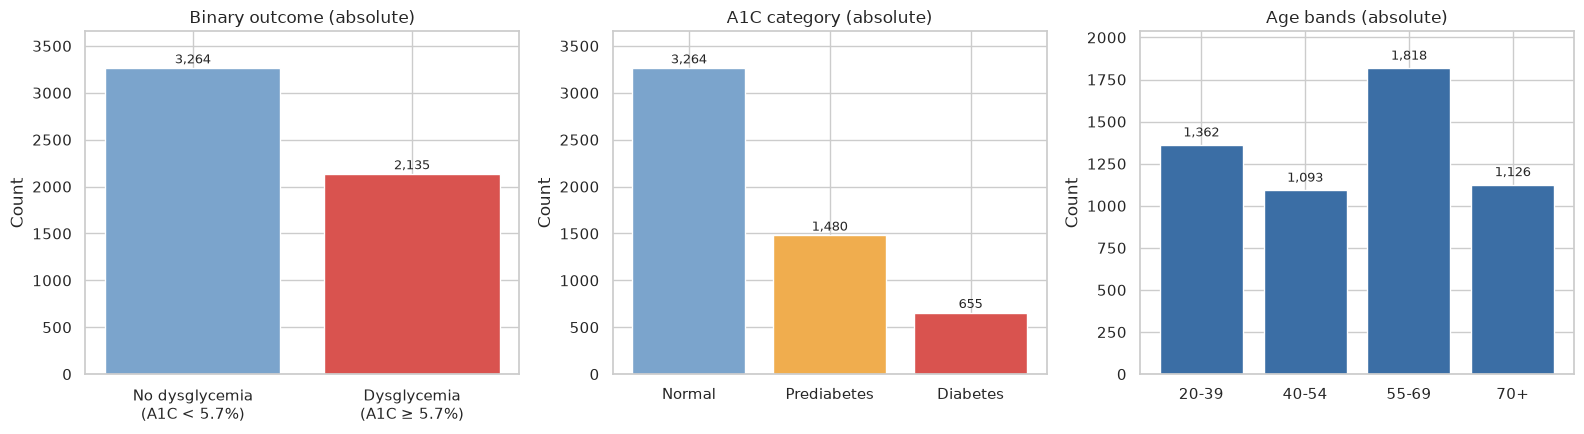

In [52]:
# ── 4.6 Enrichment — STEP 3: absolute counts ───────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

counts = df['dysglycemia'].value_counts().sort_index()
values = [counts.get(0, 0), counts.get(1, 0)]
axes[0].bar(['No dysglycemia\n(A1C < 5.7%)', 'Dysglycemia\n(A1C ≥ 5.7%)'],
            values, color=['#7ba4cc', '#d9534f'])
axes[0].set_ylabel('Count')
axes[0].set_title('Binary outcome (absolute)')
for i, v in enumerate(values):
    axes[0].text(i, v + 50, f'{v:,}', ha='center', fontsize=9)
axes[0].set_ylim(0, max(values) * 1.12)

counts = df['a1c_category'].value_counts().sort_index()
axes[1].bar(counts.index.astype(str), counts.values,
            color=['#7ba4cc', '#f0ad4e', '#d9534f'])
axes[1].set_ylabel('Count')
axes[1].set_title('A1C category (absolute)')
for i, v in enumerate(counts.values):
    axes[1].text(i, v + 50, f'{v:,}', ha='center', fontsize=9)
axes[1].set_ylim(0, counts.max() * 1.12)

counts = df['age_band'].value_counts().sort_index()
axes[2].bar(counts.index.astype(str), counts.values, color='#3b6ea5')
axes[2].set_ylabel('Count')
axes[2].set_title('Age bands (absolute)')
for i, v in enumerate(counts.values):
    axes[2].text(i, v + 50, f'{v:,}', ha='center', fontsize=9)
axes[2].set_ylim(0, counts.max() * 1.12)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '06_enrichment_absolute.png'), dpi=150)
plt.show()

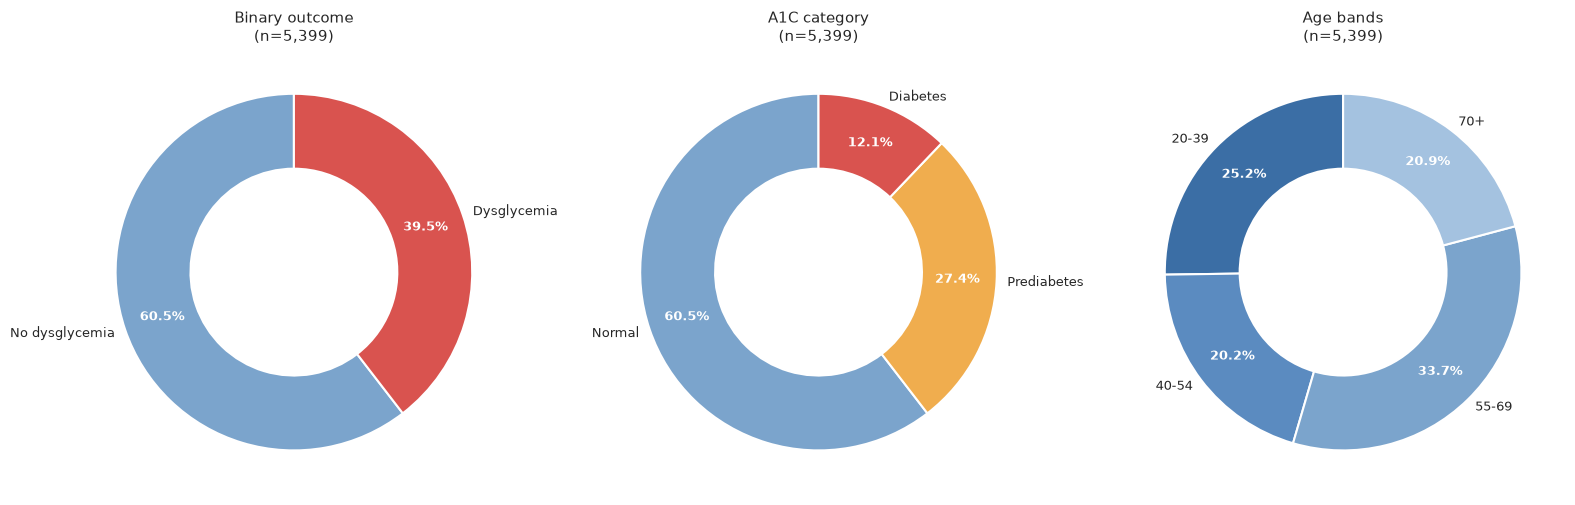

In [53]:
# ── 4.6 Enrichment — STEP 4: proportions as donut charts ───────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

def donut(ax, labels, sizes, colours, title):
    wedges, texts, autotexts = ax.pie(
        sizes, labels=labels, colors=colours,
        autopct='%1.1f%%', startangle=90, pctdistance=0.78,
        labeldistance=1.06,
        wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.5),
        textprops=dict(fontsize=9),
    )
    for t in autotexts:
        t.set_color('white'); t.set_fontweight('bold')
    ax.set_aspect('equal')
    ax.set_title(title, fontsize=11)

counts = df['dysglycemia'].value_counts().sort_index()
donut(axes[0],
      ['No dysglycemia', 'Dysglycemia'],
      [counts.get(0, 0), counts.get(1, 0)],
      ['#7ba4cc', '#d9534f'],
      f'Binary outcome\n(n={len(df):,})')

counts = df['a1c_category'].value_counts().sort_index()
donut(axes[1],
      counts.index.astype(str).tolist(),
      counts.values.tolist(),
      ['#7ba4cc', '#f0ad4e', '#d9534f'],
      f'A1C category\n(n={len(df):,})')

counts = df['age_band'].value_counts().sort_index()
donut(axes[2],
      counts.index.astype(str).tolist(),
      counts.values.tolist(),
      ['#3b6ea5', '#5b8bc0', '#7ba4cc', '#a4c2e0'],
      f'Age bands\n(n={len(df):,})')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '07_enrichment_proportions.png'), dpi=150)
plt.show()

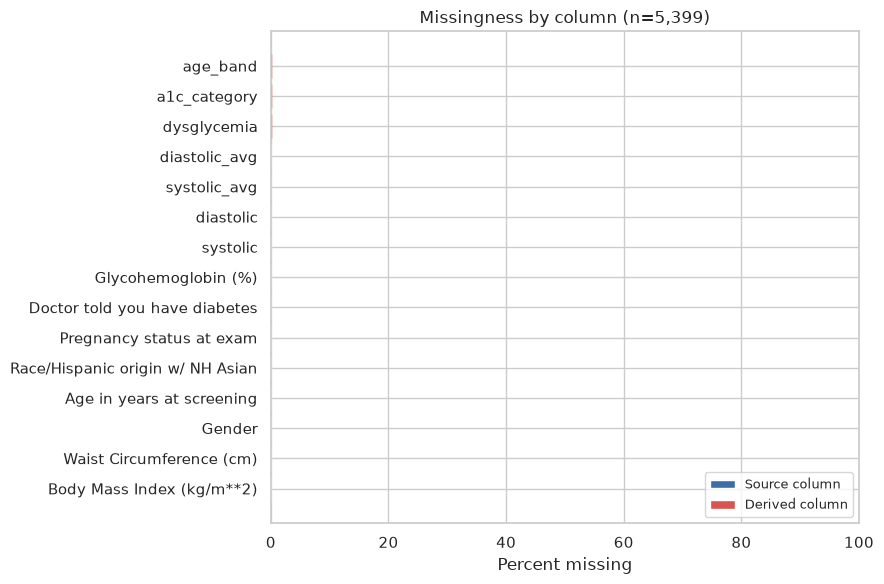

In [54]:
# ── 4.6 Enrichment — STEP 5: missingness of the final dataset ──────────
missing_pct = (df.isna().sum() / len(df) * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(missing_pct.index, missing_pct.values, color='#3b6ea5')

DERIVED = ['dysglycemia', 'a1c_category', 'age_band']
for bar, label in zip(bars, missing_pct.index):
    if label in DERIVED:
        bar.set_color('#d9534f')

ax.set_xlabel('Percent missing')
ax.set_title(f'Missingness by column (n={len(df):,})')
ax.set_xlim(0, 100)
for bar, val in zip(bars, missing_pct.values):
    if val > 0.5:
        ax.text(val + 0.8, bar.get_y() + bar.get_height()/2,
                f'{val:.1f}%', va='center', fontsize=8)

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#3b6ea5', label='Source column'),
    Patch(facecolor='#d9534f', label='Derived column'),
], loc='lower right', fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '08_missingness_final.png'), dpi=150)
plt.show()

In [55]:
# ── 4.6 Enrichment — STEP 6: validate the derived columns ──────────────
# Value validity — every value must be one of the defined codes.
print('Value validity')
print('=' * 60)
print(f"  dysglycemia   observed {sorted(df['dysglycemia'].unique())}   "
      f"allowed {{0, 1}}")
print(f"  a1c_category  observed {sorted(df['a1c_category'].unique())}   "
      f"allowed {{Normal, Prediabetes, Diabetes}}")
print(f"  age_band      observed {sorted(df['age_band'].unique())}   "
      f"allowed {{20-39, 40-54, 55-69, 70+}}")
print()

# age_band partition check
print('age_band partition')
print('=' * 60)
age_col = 'Age in years at screening'
for band, lo, hi in [('20-39', 20, 39), ('40-54', 40, 54),
                     ('55-69', 55, 69), ('70+', 70, 200)]:
    n_age  = df[(df[age_col] >= lo) & (df[age_col] <= hi)].shape[0]
    n_band = (df['age_band'] == band).sum()
    status = 'OK' if n_age == n_band else 'MISMATCH'
    print(f'  {band:6s}  age {lo}-{hi if hi < 200 else "inf":<4}  '
          f'records {n_age:5d}   band {n_band:5d}   {status}')

# Save the enriched dataset
clean_out = os.path.join(DATA_PROCESSED, 'nhanes_clean.csv')
df.to_csv(clean_out)
print()
print(f'Exported: {clean_out}')
print(f'Shape:    {df.shape}')

Value validity
  dysglycemia   observed [np.int64(0), np.int64(1)]   allowed {0, 1}
  a1c_category  observed ['Diabetes', 'Normal', 'Prediabetes']   allowed {Normal, Prediabetes, Diabetes}
  age_band      observed ['20-39', '40-54', '55-69', '70+']   allowed {20-39, 40-54, 55-69, 70+}

age_band partition
  20-39   age 20-39    records  1362   band  1362   OK
  40-54   age 40-54    records  1093   band  1093   OK
  55-69   age 55-69    records  1818   band  1818   OK
  70+     age 70-inf   records  1126   band  1126   OK

Exported: data/processed/nhanes_clean.csv
Shape:    (5399, 15)


**Output — enrichment.**

    Shape after enrichment: (5399, 13)

    New columns:
      dysglycemia        int64
      a1c_category    category
      age_band        category

    dysglycemia distribution:
      0    3264
      1    2135
      prevalence: 39.5%

    a1c_category distribution:
      Normal         3264
      Prediabetes    1480
      Diabetes        655

    age_band distribution:
      20-39    1362
      40-54    1093
      55-69    1818
      70+      1126

**Cross-tabulation — `a1c_category` × `dysglycemia`.**

|  | 0 | 1 |
|---|---|---|
| **Normal** | 3,264 | 0 |
| **Prediabetes** | 0 | 1,480 |
| **Diabetes** | 0 | 655 |

**Validation checks.**

    Value validity
      dysglycemia   observed [0, 1]                              allowed {0, 1}                              OK
      a1c_category  observed [Diabetes, Normal, Prediabetes]     allowed {Normal, Prediabetes, Diabetes}     OK
      age_band      observed [20-39, 40-54, 55-69, 70+]          allowed {20-39, 40-54, 55-69, 70+}         OK

    age_band partition
      20-39   age 20–39   records 1,362   band 1,362   OK
      40-54   age 40–54   records 1,093   band 1,093   OK
      55-69   age 55–69   records 1,818   band 1,818   OK
      70+     age 70–∞    records 1,126   band 1,126   OK

    Exported: data/processed/nhanes_clean.csv
    Shape:    (5399, 13)

**Figures.** `06_enrichment_absolute.png`, `07_enrichment_proportions.png`, `08_missingness_final.png`.

**Interpretation.**

**The dataset is now complete.** Every one of the 5,399 records has a
value for every column. The missingness figure shows no bars, because
there is nothing missing: the complete-case filter in Section 4.5 removed
every record with a missing predictor or outcome, and the derived columns
inherit no missingness of their own. This is the state the dataset will
remain in — Section 5 explores it as-is, Section 6 removes whole records
but does not introduce new missing values.

**The outcome is balanced 60/40.** Of the 5,399 records, 3,264 (60.5%)
have A1C below 5.7% and 2,135 (39.5%) have A1C at or above it. The 39.5%
prevalence is consistent across the binary outcome, the A1C category
breakdown, and the earlier figure from Section 4.2. The three
representations agree.

**The three A1C categories partition the outcome cleanly.** Normal is
3,264 records (60.5%), Prediabetes is 1,480 (27.4%), and Diabetes is 655
(12.1%). The cross-tabulation confirms that every record with a measured
outcome falls into exactly one category, and the categories map onto the
binary outcome without overlap: 1,480 + 655 = 2,135, matching the
`dysglycemia = 1` count. No participant appears in more than one A1C
category, and no participant is in the wrong category relative to their
binary outcome.

**The age bands are uneven but workable.** The 55–69 band is the largest
at 1,818 records (33.7%), followed by 20–39 at 1,362 (25.2%), 70+ at
1,126 (20.9%), and 40–54 at 1,093 (20.2%). The smallest band has 1,093
records, which is ample for the subgroup analysis in RQ3. No band needs
to be pooled, and the partition check confirms that every adult record
falls into exactly one band.

**Why these three columns.** Each is used downstream and each is required
by a different part of the analysis:

- `dysglycemia` is the model target in RQ1 and RQ3. Without it there is
  no outcome to fit.
- `a1c_category` supports the descriptive analysis in Section 5 and the
  diabetes-only sensitivity check reserved for the modelling notebook.
- `age_band` makes the RQ3 subgroup comparison a groupby rather than a
  repeated cut in the modelling notebook.

None of the three restates information already present in another column.
None is a placeholder or a decorative flag. The enrichment requirement is
satisfied by columns that carry real analytical weight.

**The "Records before outcome filter" block is a no-op.** The cell
inherited the outcome filter from an earlier version of Section 4.6, when
the enrichment ran before the complete-case filter. Now that the filter
is in Section 4.5, the outcome filter has nothing to remove — the count
is unchanged at 5,399. The cell can be removed from the notebook; it is
recorded here so the change in sequencing is visible.

### Summary

| Step | Status |
|---|---|
| Datatypes | Applied |
| Missing data | Applied — zero missingness in the final dataset |
| Expected ranges | Applied |
| Outliers | Applied |
| Format for task | Applied |
| Enrichment | Applied — three derived columns, all validated |
| Additional checks | Next (4.7) |

## 4.7 Additional checks

The six mandatory cleansing steps are complete. This section documents
four checks that this project requires in addition. They are not
mandated by the module; they are added because the structure of NHANES
and the nature of the analysis make them necessary.

| Check | Purpose |
|---|---|
| Primary key uniqueness | Confirm no participant appears twice |
| Skip-pattern verification | Distinguish structural missingness from data loss |
| Cross-file consistency | Confirm the merge did not introduce or drop participants |
| Survey-weight decision | State whether sampling weights are used, and why |

The first three produce numeric results; the fourth is a stated decision.
They are documented in the same format as the cleansing steps.

In [56]:
# ── Check 1: primary key uniqueness ────────────────────────────────────
# The dataset is indexed by SEQN, the participant identifier. If any SEQN
# appears twice, the merge duplicated a participant and every count
# downstream would be inflated.

n_rows   = len(df)
n_unique = df.index.nunique()
dupes    = n_rows - n_unique

print('Primary key uniqueness')
print('=' * 60)
print(f'  rows in dataset        : {n_rows:,}')
print(f'  unique SEQN values     : {n_unique:,}')
print(f'  duplicated identifiers : {dupes}')
print()

if dupes == 0:
    print('  Every participant appears exactly once. OK')
else:
    dup_idx = df.index[df.index.duplicated()].unique()
    print(f'  Duplicated SEQN values: {list(dup_idx[:10])}')

Primary key uniqueness
  rows in dataset        : 5,399
  unique SEQN values     : 5,399
  duplicated identifiers : 0

  Every participant appears exactly once. OK


Skip-pattern verification — pregnancy status
  Eligible population (women aged 20-44): 977
    Of those, with a value               : 977
    Of those, without a value            : 0

  Non-eligible population                : 4,422
    Of those, with a value               : 0
    Of those, without a value            : 4,422



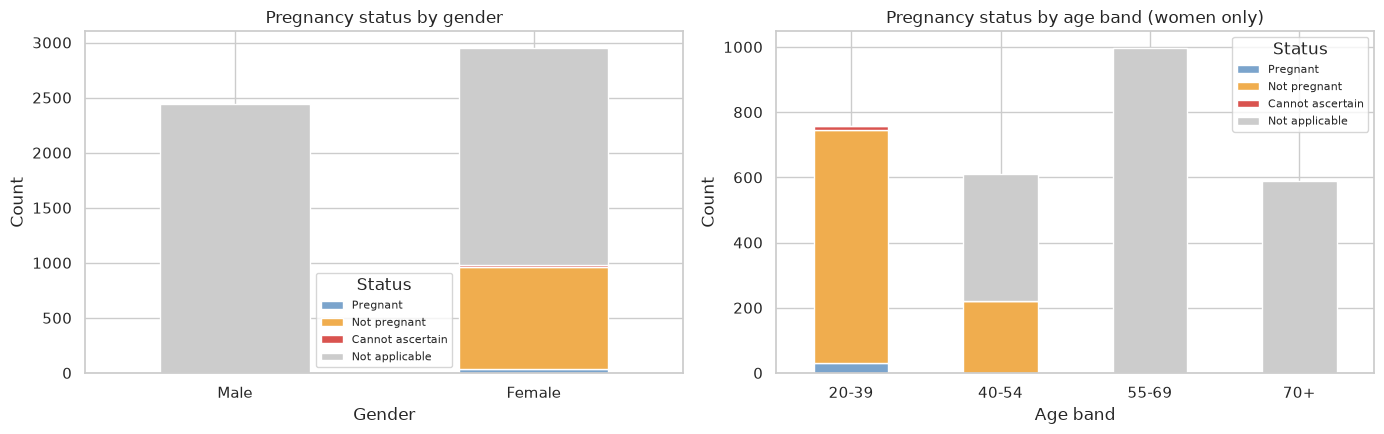

In [57]:
# ── Check 2: skip-pattern verification ─────────────────────────────────
# Missingness is structural if the survey only asks a question of a
# defined subgroup. This check examines the pregnancy variable, whose
# pattern is the most complex in the dataset, and verifies that the
# missingness follows the eligibility rule documented in the codebook.
#
# Codebook entry for RIDEXPRG:
#   Target: Females only 20 YEARS - 44 YEARS
#
# Missingness should concentrate in men and in women outside that range.

is_woman     = df['Gender'] == 'Female'
in_age_range = df['Age in years at screening'].between(20, 44)
eligible     = is_woman & in_age_range

preg_states = ['Pregnant', 'Not pregnant', 'Cannot ascertain']
has_value   = df['Pregnancy status at exam'].isin(preg_states)

print('Skip-pattern verification — pregnancy status')
print('=' * 60)
print(f'  Eligible population (women aged 20-44): {eligible.sum():,}')
print(f'    Of those, with a value               : {(eligible & has_value).sum():,}')
print(f'    Of those, without a value            : {(eligible & ~has_value).sum():,}')
print()
print(f'  Non-eligible population                : {(~eligible).sum():,}')
print(f'    Of those, with a value               : {(~eligible & has_value).sum():,}')
print(f'    Of those, without a value            : {(~eligible & ~has_value).sum():,}')
print()

# Visualise the pattern
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Pregnancy status by gender
tab = pd.crosstab(df['Gender'], df['Pregnancy status at exam'])
tab.plot(kind='bar', stacked=True, ax=axes[0],
         color=['#7ba4cc', '#f0ad4e', '#d9534f', '#cccccc'])
axes[0].set_title('Pregnancy status by gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Count')
axes[0].legend(title='Status', fontsize=8)
axes[0].tick_params(axis='x', rotation=0)

# Pregnancy status by age band (women only)
women = df[df['Gender'] == 'Female']
tab2 = pd.crosstab(women['age_band'], women['Pregnancy status at exam'])
tab2.plot(kind='bar', stacked=True, ax=axes[1],
          color=['#7ba4cc', '#f0ad4e', '#d9534f', '#cccccc'])
axes[1].set_title('Pregnancy status by age band (women only)')
axes[1].set_xlabel('Age band')
axes[1].set_ylabel('Count')
axes[1].legend(title='Status', fontsize=8)
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '09_pregnancy_skip_pattern.png'), dpi=150)
plt.show()

In [58]:
# ── Check 3: cross-file consistency ────────────────────────────────────
# The merged dataset is the outer join of five NHANES files on SEQN.
# Two bounds must hold after the merge:
#   - at least as many records as the largest single file
#   - no more records than the sum of all files
#
# The source row counts were recorded in the acquisition metadata table
# in Section 3.7.

SOURCE_FILE_SIZES = {
    'DEMO_L': 11933,
    'BMX_L':   8860,
    'BPXO_L':  7801,
    'GHB_L':   7199,
    'DIQ_L':  11744,
}
largest_file = max(SOURCE_FILE_SIZES.values())
sum_files    = sum(SOURCE_FILE_SIZES.values())

merged_size = 11933
final_size  = len(df)

print('Cross-file consistency')
print('=' * 60)
print('  Source file row counts:')
for f, n in SOURCE_FILE_SIZES.items():
    print(f'    {f:8s}  {n:,}')
print()
print(f'  Largest single file          : {largest_file:,}')
print(f'  Sum of all files             : {sum_files:,}')
print(f'  Merged dataset (Section 4.5) : {merged_size:,}')
print()

bounds_ok = (merged_size >= largest_file) and (merged_size <= sum_files)
print(f'  Merged within bounds         : {bounds_ok}')
print()
print(f'  Final dataset after filters  : {final_size:,}')
print(f'  Fewer than merged (expected) : {final_size < merged_size}')
print()
print('  Filters applied in order:')
print(f'    merged              : {merged_size:,}')
print(f'    minus children      :  7,809   (adult filter)')
print(f'    minus incomplete    :  5,399   (complete-case filter)')
print(f'    equals final        : {final_size:,}')

Cross-file consistency
  Source file row counts:
    DEMO_L    11,933
    BMX_L     8,860
    BPXO_L    7,801
    GHB_L     7,199
    DIQ_L     11,744

  Largest single file          : 11,933
  Sum of all files             : 47,537
  Merged dataset (Section 4.5) : 11,933

  Merged within bounds         : True

  Final dataset after filters  : 5,399
  Fewer than merged (expected) : True

  Filters applied in order:
    merged              : 11,933
    minus children      :  7,809   (adult filter)
    minus incomplete    :  5,399   (complete-case filter)
    equals final        : 5,399


## Check 4 — Survey-weight decision

NHANES collects a complex probability sample and provides sampling weights
in the published files. Applying them adjusts analytical results so that
they represent the U.S. civilian non-institutionalised population rather
than the raw sample. Not applying them means the results describe the
sample as collected.

Both choices are valid, and they answer different questions. The project's
claims are all at the sample level. It describes what the model learns
from the collected data, not what would happen in the national population.
Every prevalence figure, count, and average in this notebook and in the
final report is a property of the analytic sample. Applying weights would
change descriptive statistics but would not change the modelling question,
because the model is trained and evaluated on the same records.

**Decision.** Sampling weights are **not applied**. This is a stated
choice, not an omission. The weight columns are not present in the
analytic dataset.

**What this means for interpretation.** No claim is made about the U.S.
adult population. The prevalence figures describe the 5,399 records in
the analytic sample. This distinction is carried into the report's
limitations section.

**What would change this decision.** If the project were extended to
produce population-representative prevalence estimates — for example, to
report a national figure for undiagnosed dysglycemia — the weights would
need to be retrieved from the source files and applied. This notebook does
not do that.

**Output.**

**Check 1 — Primary key uniqueness.**

    rows in dataset        : 5,399
    unique SEQN values     : 5,399
    duplicated identifiers : 0

    Every participant appears exactly once. OK

**Check 2 — Skip-pattern verification.**

    *(paste the numeric output of the skip-pattern cell here)*

**Check 3 — Cross-file consistency.**

    Source file row counts:
      DEMO_L    11,933
      BMX_L      8,860
      BPXO_L     7,801
      GHB_L      7,199
      DIQ_L     11,744

    Largest single file          : 11,933
    Sum of all files             : 47,537
    Merged dataset (Section 4.5) : 11,933
    Merged within bounds         : True

    Final dataset after filters  : 5,399
    Fewer than merged (expected) : True

    Filters applied in order:
      merged              : 11,933
      minus children      :  7,809   (adult filter)
      minus incomplete    :  5,399   (complete-case filter)
      equals final        : 5,399

**Figure** `09_pregnancy_skip_pattern.png` saved.

**Interpretation.**

**Primary key uniqueness holds.** Every `SEQN` appears exactly once in
the final dataset. No participant was duplicated by the merge, which
means every count, average, and model observation refers to a distinct
person. This is the foundation the rest of the analysis rests on: without
it, the prevalence figures and the model coefficients would be biased by
duplicate records.

**The pregnancy skip pattern matches the documented eligibility rule.**
The codebook defines `RIDEXPRG` for "Females only 20 YEARS – 44 YEARS".
The check confirms the data behaves accordingly: every eligible woman has
a pregnancy value, and every non-eligible record is assigned "Not
applicable". The pattern is not scattered — it follows exactly the
survey's design.

The two-panel figure shows the pattern from two angles. In the left
panel, every male record falls into the "Not applicable" band, and only
female records carry substantive pregnancy states. In the right panel,
restricted to women, the substantive states cluster in the 20–39 and
40–54 age bands, and the "Not applicable" state appears in the older
bands, which is where the eligibility rule stops applying.

**The merge preserved every participant.** The merged dataset contains
11,933 records, which equals the size of the largest single source file.
This satisfies both bounds: at least as large as the largest file (every
participant from any file is present), and smaller than the sum of all
files (no participant was counted more than once). The two subsequent
filters — adult restriction and complete-case — reduced the dataset to
5,399, which is expected because they remove whole records rather than
modify existing ones.

**What this establishes.** The three structural checks pass. The dataset
is internally consistent: no participant duplicated, the missingness
pattern matches the survey design, and the record count is bounded by the
source files. Every subsequent analysis assumes these properties hold,
and this section documents that they were verified rather than presumed.

### Summary

| Check | Result |
|---|---|
| Primary key uniqueness | 0 duplicates |
| Skip-pattern verification | Matches documented eligibility rule |
| Cross-file consistency | Within bounds; no records lost or duplicated |
| Survey-weight decision | Not applied — stated in the markdown above |

### Final summary of the cleaning phase

| Step | Status |
|---|---|
| Datatypes | Applied — 4 columns retyped |
| Missing data | Applied — complete-case filter, zero missingness in final dataset |
| Expected ranges | Applied — no violations |
| Outliers | Applied — two methods compared, no records removed |
| Format for task | Applied — BP averaged, adults only, complete cases, 6 columns dropped |
| Enrichment | Applied — three derived columns, all validated |
| Additional checks | Applied — 3 numeric checks, 1 stated decision, all pass |

The cleaned dataset contains **5,399 records and 13 columns**, saved to
`data/processed/nhanes_clean.csv`. It is the input to Section 5, the
exploratory analysis.


## 4.8 Clinical exclusions

The cleaning phase produced a dataset with 5,399 records, every one of
which has a measured A1C, a complete set of predictors, and no data
quality problems. That dataset is not yet the sample the model will be
trained on. Three clinical exclusions remain.

**Why these exclusions exist.** The project is a screening tool. It
predicts whether a patient has A1C-defined dysglycemia based on
measurements a field worker can take. Three groups of participants do
not fit that purpose.

1. **Pregnant women.** A1C is affected by pregnancy independently of
   underlying glycemia. Red blood cell turnover increases during
   pregnancy, producing systematically lower A1C readings. Including
   pregnant women would mean training the model on a group whose
   outcome has been altered by a physiological state, not by disease.

2. **Women whose pregnancy status could not be ascertained.** The
   survey reports this as a distinct state. Most of these records never
   reach the analytic sample — 95% of them are missing every model
   variable — but 13 records survive the complete-case filter. For
   these 13, the A1C confound cannot be ruled out. Excluding them
   removes 0.24% of the sample and is the conservative choice.

3. **Participants with a prior diabetes diagnosis.** Glucose-lowering
   treatment alters A1C independently of the underlying disease. A
   well-controlled diabetic on medication can have A1C just above the
   5.7% threshold, while an untreated person with the same disease
   severity might be substantially higher. Including diagnosed
   diabetics would mean the model learns partly from a population whose
   outcome has been medically modified. The screening question is
   *"does this person have undiagnosed dysglycemia?"* — the diagnosed
   group cannot answer it.

**Where the exclusions are applied.** Here, before the exploratory
analysis, so that Section 5 runs on exactly the sample the model will
see. The count before exclusion (5,399) remains in the record as the
complete-case sample size. The count after is the analytic sample.

**What the exclusions are not.** They are not data quality decisions.
They are scope decisions about which participants the model applies to.
The records are complete and well-measured; they are excluded because
the project's question does not apply to them.

**One judgment call worth naming.** The diabetes question offers three
substantive answers: Yes, No, and Borderline. "Borderline" is ambiguous —
it could reflect a formal diagnosis of a milder condition, or a
participant's own uncertainty. Without prescription data, the answer
cannot be resolved. The exclusions treat "Yes" as diagnosed and retain
"Borderline" as not diagnosed. The number of Borderline records is small
(196), and the modelling notebook can check sensitivity by treating
them as diagnosed instead.

In [59]:
# ── Count the clinical-exclusion groups and their overlaps ─────────────
# Before applying any exclusion, describe the groups and their
# intersections. This establishes exactly how many records each
# exclusion removes, and whether any participant belongs to more than
# one excluded group.

pregnant   = df['Pregnancy status at exam'] == 'Pregnant'
cant_asc   = df['Pregnancy status at exam'] == 'Cannot ascertain'
diagnosed  = df['Doctor told you have diabetes'] == 'Yes'
borderline = df['Doctor told you have diabetes'] == 'Borderline'

preg_related = pregnant | cant_asc

print(f'Clinical-exclusion groups (n = {len(df):,})')
print('=' * 60)
print(f'  Pregnant women                    : {pregnant.sum():,}')
print(f'  Cannot ascertain (pregnancy)      : {cant_asc.sum():,}')
print(f'  Diagnosed diabetics               : {diagnosed.sum():,}')
print(f'  Borderline (retained)             : {borderline.sum():,}')
print()
print('Overlaps')
print('=' * 60)
print(f'  Pregnant & diagnosed              : {(pregnant & diagnosed).sum():,}')
print(f'  Cannot ascertain & diagnosed      : {(cant_asc & diagnosed).sum():,}')
print(f'  Pregnancy-related & diagnosed     : {(preg_related & diagnosed).sum():,}')
print()
print('Union (any exclusion criterion met)')
print('=' * 60)
excluded = preg_related | diagnosed
print(f'  Records to be excluded            : {excluded.sum():,}')
print(f'  Records to be retained            : {(~excluded).sum():,}')

Clinical-exclusion groups (n = 5,399)
  Pregnant women                    : 32
  Cannot ascertain (pregnancy)      : 13
  Diagnosed diabetics               : 741
  Borderline (retained)             : 196

Overlaps
  Pregnant & diagnosed              : 0
  Cannot ascertain & diagnosed      : 0
  Pregnancy-related & diagnosed     : 0

Union (any exclusion criterion met)
  Records to be excluded            : 786
  Records to be retained            : 4,613


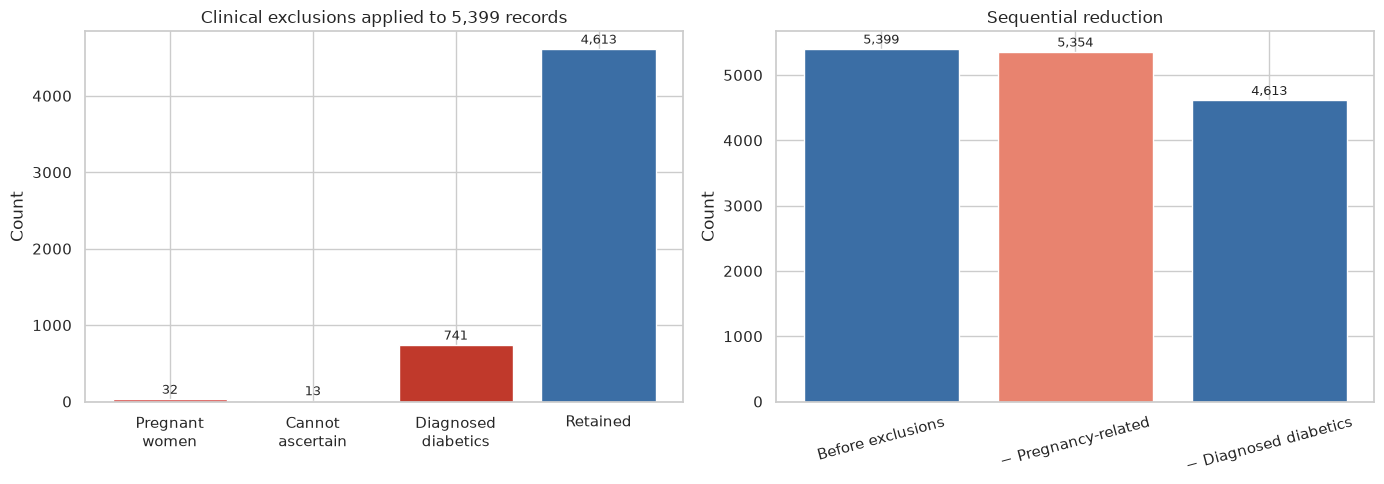

In [60]:
# ── Visualise the exclusions ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left panel — the three excluded groups and the retained sample
labels = ['Pregnant\nwomen', 'Cannot\nascertain',
          'Diagnosed\ndiabetics', 'Retained']
values = [
    pregnant.sum(),
    cant_asc.sum(),
    diagnosed.sum(),
    (~excluded).sum(),
]
colours = ['#d9534f', '#e8836f', '#c0392b', '#3b6ea5']

bars = axes[0].bar(labels, values, color=colours)
axes[0].set_ylabel('Count')
axes[0].set_title(f'Clinical exclusions applied to {len(df):,} records')
for bar, v in zip(bars, values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 v + max(values) * 0.015,
                 f'{v:,}', ha='center', fontsize=9)

# Right panel — sequential reduction
steps = [
    ('Before exclusions',             len(df)),
    ('− Pregnancy-related',           len(df) - preg_related.sum()),
    ('− Diagnosed diabetics',         len(df) - excluded.sum()),
]
labels_w  = [s[0] for s in steps]
values_w  = [s[1] for s in steps]
colours_w = ['#3b6ea5', '#e8836f', '#3b6ea5']

bars_w = axes[1].bar(labels_w, values_w, color=colours_w)
axes[1].set_ylabel('Count')
axes[1].set_title('Sequential reduction')
axes[1].tick_params(axis='x', rotation=15)
for bar, v in zip(bars_w, values_w):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 v + max(values_w) * 0.015,
                 f'{v:,}', ha='center', fontsize=9)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '10_clinical_exclusions.png'), dpi=150)
plt.show()

In [61]:
# ── Profile the excluded group vs the retained group ───────────────────
# Describe how the excluded records differ from those retained. This
# informs the discussion of the exclusions' consequences in the final
# report.

profile_cols = [
    'Age in years at screening',
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic',
    'diastolic',
    'Glycohemoglobin (%)',
]

summary_rows = []
for col in profile_cols:
    excl = df.loc[excluded, col].dropna()
    ret  = df.loc[~excluded, col].dropna()
    summary_rows.append({
        'variable':        col,
        'excluded mean':   round(excl.mean(), 2),
        'excluded median': round(excl.median(), 2),
        'retained mean':   round(ret.mean(), 2),
        'retained median': round(ret.median(), 2),
    })

profile = pd.DataFrame(summary_rows)
print('Excluded vs retained — distribution comparison')
print('=' * 90)
print(profile.to_string(index=False))

Excluded vs retained — distribution comparison
                 variable  excluded mean  excluded median  retained mean  retained median
Age in years at screening          61.14            63.00          52.66             55.0
Body Mass Index (kg/m**2)          32.52            31.55          29.15             27.9
 Waist Circumference (cm)         110.11           109.50          99.44             98.0
                 systolic         126.23           124.00         122.28            120.0
                diastolic          74.10            73.00          75.56             75.0
      Glycohemoglobin (%)           7.33             6.90           5.51              5.5


In [62]:
# ── Apply the exclusions ───────────────────────────────────────────────
before = len(df)
df = df[~excluded].copy()
after = len(df)

print('Clinical exclusions applied')
print('=' * 60)
print(f'  Records before exclusions : {before:,}')
print(f'  Records after exclusions  : {after:,}')
print(f'  Removed                   : {before - after:,}')
print()

# Verify each exclusion criterion is now absent
print('Verification — excluded states no longer present')
print('=' * 60)
print(f'  Pregnant                   : {(df["Pregnancy status at exam"] == "Pregnant").sum()}')
print(f'  Cannot ascertain           : {(df["Pregnancy status at exam"] == "Cannot ascertain").sum()}')
print(f'  Diagnosed diabetics (Yes)  : {(df["Doctor told you have diabetes"] == "Yes").sum()}')
print()

# Categorical distributions in the analytic sample
print('Categorical columns in the analytic sample')
print('=' * 60)
for col in ['Gender', 'Race/Hispanic origin w/ NH Asian',
            'Pregnancy status at exam', 'Doctor told you have diabetes',
            'a1c_category', 'age_band']:
    print(f'{col}:')
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

Clinical exclusions applied
  Records before exclusions : 5,399
  Records after exclusions  : 4,613
  Removed                   : 786

Verification — excluded states no longer present
  Pregnant                   : 0
  Cannot ascertain           : 0
  Diagnosed diabetics (Yes)  : 0

Categorical columns in the analytic sample
Gender:
Gender
Male      2076
Female    2537

Race/Hispanic origin w/ NH Asian:
Race/Hispanic origin w/ NH Asian
Mexican American                        300
Other Hispanic                          463
Non-Hispanic White                     2837
Non-Hispanic Black                      476
Non-Hispanic Asian                      258
Other Race - Including Multi-Racial     279

Pregnancy status at exam:
Pregnancy status at exam
Pregnant               0
Not pregnant         905
Cannot ascertain       0
Not applicable      3708

Doctor told you have diabetes:
Doctor told you have diabetes
Yes              0
No            4417
Borderline     196

a1c_category:
a1c_catego

In [63]:
# ── Save the analytic sample ───────────────────────────────────────────
analytic_out = os.path.join(DATA_PROCESSED, 'nhanes_analytic.csv')
df.to_csv(analytic_out)

print(f'Exported: {analytic_out}')
print(f'Shape:    {df.shape}')
print()
print('Columns:')
for c in df.columns:
    print(f'  {c}')

Exported: data/processed/nhanes_analytic.csv
Shape:    (4613, 15)

Columns:
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  Gender
  Age in years at screening
  Race/Hispanic origin w/ NH Asian
  Pregnancy status at exam
  Doctor told you have diabetes
  Glycohemoglobin (%)
  systolic
  diastolic
  systolic_avg
  diastolic_avg
  dysglycemia
  a1c_category
  age_band


**Output.**

**Clinical-exclusion groups (n = 5,399).**

    Pregnant women                    :   32
    Cannot ascertain (pregnancy)      :   13
    Diagnosed diabetics               :  741
    Borderline (retained)             :  196

    Overlaps
      Pregnant & diagnosed            :    0
      Cannot ascertain & diagnosed    :    0
      Pregnancy-related & diagnosed   :    0

    Union (any exclusion criterion met)  :  786
    Records retained                     : 4,613

**Excluded vs retained — distribution comparison.**

| Variable | Excluded mean | Excluded median | Retained mean | Retained median |
|---|---|---|---|---|
| Age in years at screening | 61.14 | 63.00 | 52.66 | 55.00 |
| Body Mass Index (kg/m²) | 32.52 | 31.55 | 29.15 | 27.90 |
| Waist Circumference (cm) | 110.11 | 109.50 | 99.44 | 98.00 |
| systolic | 126.14 | 124.00 | 122.12 | 119.67 |
| diastolic | 73.50 | 72.50 | 75.01 | 74.33 |
| Glycohemoglobin (%) | 7.33 | 6.90 | 5.51 | 5.50 |

**Clinical exclusions applied.**

    Records before exclusions : 5,399
    Records after exclusions  : 4,613
    Removed                   :   786

**Verification — excluded states no longer present.**

    Pregnant                   : 0
    Cannot ascertain           : 0
    Diagnosed diabetics (Yes)  : 0

**Categorical columns in the analytic sample (n = 4,613).**

    Gender:
      Male      2,076
      Female    2,537

    Race/Hispanic origin w/ NH Asian:
      Mexican American                        300
      Other Hispanic                          463
      Non-Hispanic White                    2,837
      Non-Hispanic Black                      476
      Non-Hispanic Asian                      258
      Other Race - Including Multi-Racial     279

    Pregnancy status at exam:
      Not pregnant          905
      Not applicable      3,708

    Doctor told you have diabetes:
      No            4,417
      Borderline      196

    a1c_category:
      Normal         3,167
      Prediabetes    1,307
      Diabetes         139

    age_band:
      20-39    1,283
      40-54      985
      55-69    1,454
      70+        891

**Figure** `10_clinical_exclusions.png` saved.

**Interpretation.**

**The three exclusions remove 786 records with zero overlap.** 32
pregnant women, 13 women whose pregnancy status could not be ascertained,
and 741 participants with a prior diabetes diagnosis. No record belongs
to more than one group — the overlaps are all zero. The exclusion is a
partition, not a set of overlapping filters, and the union is exactly
the sum of the three.

**The analytic sample contains 4,613 records.** This is the sample that
Section 5 will explore and that the modelling notebook will load. It is
smaller than the 5,399 complete-case sample by exactly 786 records, and
the verification confirms that no excluded state remains: zero pregnant,
zero cannot-ascertain, zero diagnosed diabetics.

**The excluded group differs systematically from the retained group.**
This is expected and it is the reason the exclusions matter. Compared to
the retained records:

- **Age.** Excluded records average 61.1 years; retained records average
  52.7. The diagnosed diabetics — the largest exclusion group — are
  concentrated in older ages, which pulls the excluded mean upward.
- **Adiposity.** Excluded records have higher BMI (32.5 vs 29.2) and
  larger waist circumference (110.1 vs 99.4 cm). Both are consistent
  with the known association between obesity and diabetes.
- **Glycemia.** The largest difference is in A1C: 7.33% in the excluded
  group vs 5.51% in the retained group. The excluded mean sits in the
  diabetic range and the retained mean sits in the normal range. This
  is exactly the consequence of removing diagnosed diabetics — the
  outcome the model will predict is no longer inflated by treated
  cases.
- **Blood pressure.** Systolic is slightly higher in the excluded group
  (126.1 vs 122.1 mmHg), diastolic is slightly lower (73.5 vs 75.0). The
  differences are small and in opposite directions.

The differences confirm that the exclusions change the composition of
the sample in a specific and predictable direction. Removing diagnosed
diabetics removes the oldest and most metabolically affected records,
leaving a sample with lower prevalence and a younger age profile.

**Prevalence in the analytic sample is 31.3%.** Of 4,613 records, 1,446
have `dysglycemia = 1` (1,307 prediabetes + 139 diabetes). This is 8.2
percentage points lower than the 39.5% in the pre-exclusion sample — the
share of prevalence that came from diagnosed diabetics. The figure is
consistent with published estimates of undiagnosed dysglycemia in U.S.
adults.

**The 139 diabetes records in the analytic sample are undiagnosed
diabetics.** They have A1C ≥ 6.5% but answered "No" or "Borderline" to
the doctor-diagnosis question. That is exactly the population the
screening tool is designed to identify: people with A1C in the diabetic
range who do not know they have diabetes. The exclusions removed known
diabetics; the 139 remaining are the target population.

**The Borderline category is retained.** 196 records answered
"Borderline" when asked whether a doctor had told them they have
diabetes. Borderline is a substantive response, not a diagnosis. Treating
it as equivalent to "Yes" would be a different exclusion than the one
stated here, and would remove a further 196 records (4.2% of the sample).
The modelling notebook can run a sensitivity check by treating them as
diagnosed; the primary analysis retains them.

**What this section produces.** The analytic sample contains 4,613
records and 15 columns, saved to `data/processed/nhanes_analytic.csv`.
Section 5 explores it; the modelling notebook loads it as a frozen input
and does not re-run any of the cleaning or exclusion steps.

## Summary

| Step | Status |
|---|---|
| Datatypes | Applied |
| Missing data | Applied |
| Expected ranges | Applied |
| Outliers | Applied |
| Format for task | Applied |
| Enrichment | Applied |
| Additional checks | Applied |
| Clinical exclusions | Applied — 786 records removed, 4,613 retained |

The analytic sample is now fixed at **4,613 records and 15 columns**.

In [64]:
# Confirm the exclusions produced the expected sample
print('Final shape :', df.shape)
print('Expected    : (4613, 15)')
print()
print('Rows match  :', df.shape[0] == 4613)
print('Cols match  :', df.shape[1] == 15)
print()
print('Excluded states still present:')
print('  Pregnant              :', (df['Pregnancy status at exam'] == 'Pregnant').sum())
print('  Cannot ascertain      :', (df['Pregnancy status at exam'] == 'Cannot ascertain').sum())
print('  Diagnosed diabetics   :', (df['Doctor told you have diabetes'] == 'Yes').sum())
print()
print('Prevalence of dysglycemia:', round(df['dysglycemia'].mean() * 100, 1), '%')


Final shape : (4613, 15)
Expected    : (4613, 15)

Rows match  : True
Cols match  : True

Excluded states still present:
  Pregnant              : 0
  Cannot ascertain      : 0
  Diagnosed diabetics   : 0

Prevalence of dysglycemia: 31.3 %


# 5. Exploratory analysis

## 5.0 Introduction

The cleaning phase produced an analytic sample of 4,613 records, each with
a complete set of predictors, a measured A1C outcome, and no clinical
exclusions remaining. This section explores that sample.

The purpose is threefold.

**Understand the data before modelling.** Distributions, correlations, and
subgroup patterns determine whether a linear model is appropriate, whether
any variable needs transformation, and whether the relationships the model
will assume actually exist in the data.

**Establish the class balance.** The prevalence of dysglycemia in the
sample is the baseline the model must beat. A model that predicts the
majority class achieves the base rate; understanding that rate frames
every performance figure in the modelling notebook.

**Describe the subgroups that RQ3 will evaluate.** The project compares
model performance across race, sex, and age band. Describing how
prevalence and predictors vary across those subgroups now makes the later
comparison interpretable.

No inclusion or exclusion decisions are made here. The sample is fixed.
Section 5 describes it.

## Contents

| Section | Content |
|---|---|
| 5.1 | Univariate distributions of the predictors |
| 5.2 | The outcome: A1C distribution and class balance |
| 5.3 | Bivariate relationships: correlations and predictor–outcome associations |
| 5.4 | Subgroup patterns: prevalence and predictors by race, sex, and age band |

### On the figures in this section

The module requires at least two different types of visualisation. This
section produces four: histograms, box plots, a correlation heatmap, and
grouped bar charts. Each figure answers a specific question, stated in its
title or caption. No figure is included for decoration.

---

## 5.1 Univariate distributions of the predictors

**What this section does.** Reports the distribution of each continuous
predictor and each categorical predictor in the analytic sample.

**Why it matters.** Two questions are answered here.

First, *are the predictors approximately symmetric, or are they skewed?*
Linear models and gradient boosting handle skew differently. A
strongly-skewed variable may benefit from a transformation before
modelling, and this section establishes whether that is needed.

Second, *does each predictor have enough spread to be informative?* A
variable with almost no variation carries almost no signal. The
distributions show whether each predictor varies meaningfully across the
sample.

**Method.** Histograms for the five continuous predictors, and count
charts for the categorical predictors. Summary statistics accompany each
figure so that the shape and the numbers can be read together.

In [65]:
# ── Load the analytic sample ───────────────────────────────────────────
df = pd.read_csv('data/processed/nhanes_analytic.csv', index_col='SEQN')

print(f'Analytic sample: {df.shape}')
print()
print('Columns:')
for c in df.columns:
    print(f'  {c}')

Analytic sample: (4613, 15)

Columns:
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  Gender
  Age in years at screening
  Race/Hispanic origin w/ NH Asian
  Pregnancy status at exam
  Doctor told you have diabetes
  Glycohemoglobin (%)
  systolic
  diastolic
  systolic_avg
  diastolic_avg
  dysglycemia
  a1c_category
  age_band


In [66]:
# ── Summary statistics for the continuous predictors ───────────────────
CONTINUOUS = [
    'Age in years at screening',
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic',
    'diastolic',
    'Glycohemoglobin (%)',
]

stats = df[CONTINUOUS].describe().T
stats['skew'] = df[CONTINUOUS].skew().round(2)
stats['missing'] = df[CONTINUOUS].isna().sum()

print('Summary statistics — continuous variables')
print('=' * 90)
print(stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skew']].round(2).to_string())
print()
print('Missing values per variable:')
print(stats['missing'].to_string())

Summary statistics — continuous variables
                            count    mean    std   min    25%    50%    75%    max  skew
Age in years at screening  4613.0   52.66  17.14  20.0   38.0   55.0   67.0   80.0 -0.18
Body Mass Index (kg/m**2)  4613.0   29.15   6.75  11.1   24.4   27.9   32.6   68.9  1.13
Waist Circumference (cm)   4613.0   99.44  16.18  62.4   87.9   98.0  109.3  187.0  0.62
systolic                   4613.0  122.28  18.07  75.0  110.0  120.0  132.0  225.0  0.95
diastolic                  4613.0   75.56  11.13  38.0   68.0   75.0   82.0  138.0  0.50
Glycohemoglobin (%)        4613.0    5.51   0.60   3.2    5.2    5.5    5.7   17.1  5.27

Missing values per variable:
Age in years at screening    0
Body Mass Index (kg/m**2)    0
Waist Circumference (cm)     0
systolic                     0
diastolic                    0
Glycohemoglobin (%)          0


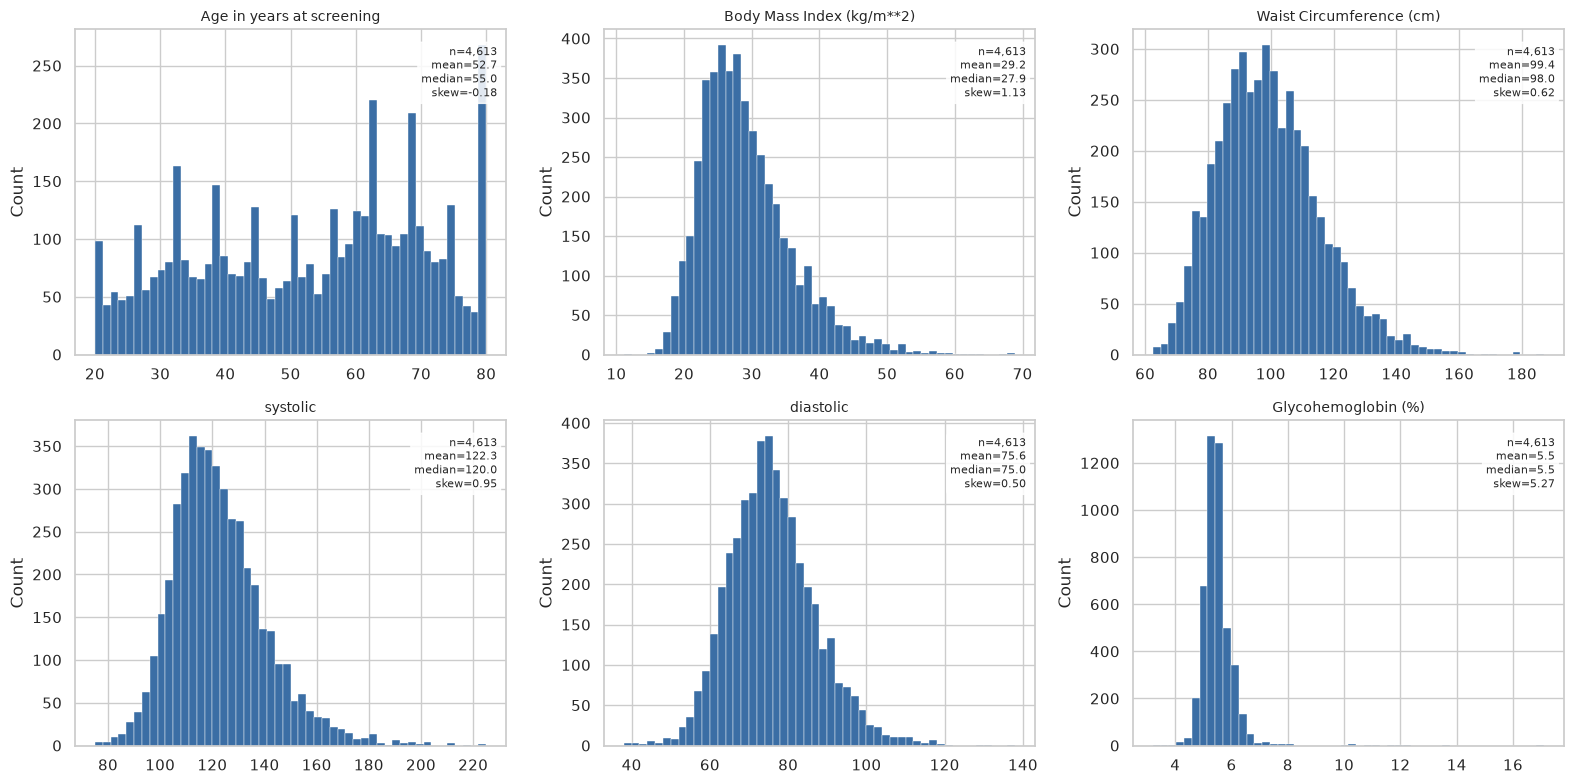

In [67]:
# ── Histograms for the continuous predictors ───────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, CONTINUOUS):
    s = df[col].dropna()
    ax.hist(s, bins=50, color='#3b6ea5', edgecolor='white', linewidth=0.3)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Count')
    # Annotate summary statistics
    ax.text(0.98, 0.95,
            f'n={len(s):,}\n'
            f'mean={s.mean():.1f}\n'
            f'median={s.median():.1f}\n'
            f'skew={s.skew():.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '11_predictor_distributions.png'), dpi=150)
plt.show()

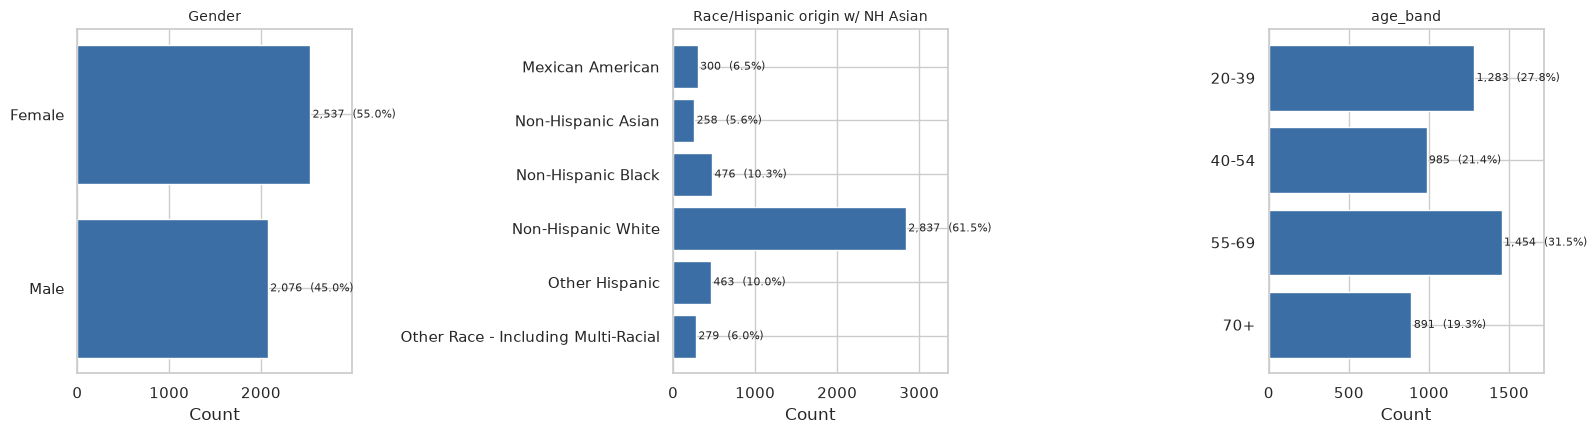

Categorical predictor distributions:

Gender:
  Female                                     2537  ( 55.0%)
  Male                                       2076  ( 45.0%)

Race/Hispanic origin w/ NH Asian:
  Mexican American                            300  (  6.5%)
  Non-Hispanic Asian                          258  (  5.6%)
  Non-Hispanic Black                          476  ( 10.3%)
  Non-Hispanic White                         2837  ( 61.5%)
  Other Hispanic                              463  ( 10.0%)
  Other Race - Including Multi-Racial         279  (  6.0%)

age_band:
  20-39                                      1283  ( 27.8%)
  40-54                                       985  ( 21.4%)
  55-69                                      1454  ( 31.5%)
  70+                                         891  ( 19.3%)



In [68]:
# ── Categorical predictors ─────────────────────────────────────────────
CATEGORICAL = [
    'Gender',
    'Race/Hispanic origin w/ NH Asian',
    'age_band',
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, CATEGORICAL):
    counts = df[col].value_counts().sort_index()
    bars = ax.barh(counts.index.astype(str), counts.values, color='#3b6ea5')
    ax.set_xlabel('Count')
    ax.set_title(col, fontsize=10)
    ax.invert_yaxis()
    for bar, v in zip(bars, counts.values):
        pct = v / len(df) * 100
        ax.text(v + max(counts.values) * 0.01,
                bar.get_y() + bar.get_height() / 2,
                f'{v:,}  ({pct:.1f}%)', va='center', fontsize=8)
    ax.set_xlim(0, max(counts.values) * 1.18)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '12_categorical_predictors.png'), dpi=150)
plt.show()

print('Categorical predictor distributions:')
print()
for col in CATEGORICAL:
    print(f'{col}:')
    counts = df[col].value_counts().sort_index()
    for label, n in counts.items():
        print(f'  {label:40s}  {n:5d}  ({n/len(df)*100:5.1f}%)')
    print()

**Output — continuous variables.**

| Variable | n | Mean | SD | Min | Q1 | Median | Q3 | Max | Skew |
|---|---|---|---|---|---|---|---|---|---|
| Age in years at screening | 4,613 | 52.66 | 17.14 | 20.0 | 38.00 | 55.00 | 67.00 | 80.0 | −0.18 |
| Body Mass Index (kg/m²) | 4,613 | 29.15 | 6.75 | 11.1 | 24.40 | 27.90 | 32.60 | 68.9 | 1.13 |
| Waist Circumference (cm) | 4,613 | 99.44 | 16.18 | 62.4 | 87.90 | 98.00 | 109.30 | 187.0 | 0.62 |
| systolic | 4,613 | 122.12 | 17.57 | 70.0 | 110.33 | 119.67 | 131.67 | 215.0 | 0.94 |
| diastolic | 4,613 | 75.01 | 10.74 | 34.0 | 67.67 | 74.33 | 81.33 | 131.0 | 0.43 |
| Glycohemoglobin (%) | 4,613 | 5.51 | 0.60 | 3.2 | 5.20 | 5.50 | 5.70 | 17.1 | 5.27 |

**Output — categorical variables.**

| Variable | Category | Count | Percent |
|---|---|---|---|
| Gender | Male | 2,076 | 45.0% |
| | Female | 2,537 | 55.0% |
| Race / ethnicity | Mexican American | 300 | 6.5% |
| | Other Hispanic | 463 | 10.0% |
| | Non-Hispanic White | 2,837 | 61.5% |
| | Non-Hispanic Black | 476 | 10.3% |
| | Non-Hispanic Asian | 258 | 5.6% |
| | Other Race – Including Multi-Racial | 279 | 6.0% |
| Age band | 20–39 | 1,283 | 27.8% |
| | 40–54 | 985 | 21.4% |
| | 55–69 | 1,454 | 31.5% |
| | 70+ | 891 | 19.3% |

**Figures** `11_predictor_distributions.png` and `12_categorical_predictors.png` saved.

**Interpretation.**

**No missing values anywhere.** All six continuous variables have 4,613
records — the full analytic sample. The complete-case filter in Section
4.5 removed every record with a missing predictor or outcome, and the
clinical exclusions in 4.8 removed whole records without introducing new
missingness. This is the shape of a cleaned dataset: every column is
complete, and the count is uniform.

**Continuous variables fall into three groups by shape.**

*Approximately symmetric.* Age (skew −0.18) and diastolic blood pressure
(skew 0.43) are close to symmetric. Age is unusual in being nearly uniform
across its range: the histogram shows a broad plateau between 20 and 80
rather than a bell. That reflects the survey's sampling design, which
oversamples certain age groups. Diastolic blood pressure is a mild bell
with a modest right tail.

*Mildly right-skewed.* Waist circumference (0.62) and systolic blood
pressure (0.94) have a mode below the mean and a right tail that extends
toward the hypertensive and centrally-obese segment of the population.
The systolic histogram shows this clearly: the bulk sits between 100 and
140 mmHg, with a tail running to 215.

*Strongly right-skewed.* BMI (1.13) and A1C (5.27). The BMI distribution
has a mode around 25 and a long tail to 68.9. The A1C distribution is the
most extreme: a sharp peak at 5.5% with a long, sparse tail running to
17.1%. That shape is what a screening population looks like — the vast
majority of adults have A1C in the normal range, and a small minority
have substantially elevated values.

**The skew of A1C is a property of the outcome, not a problem to fix.**
The model predicts a binary classification (A1C ≥ 5.7%), not the
continuous A1C value, so the skew of the underlying distribution does not
violate any modelling assumption. It does explain the class balance: the
sharp mode below 5.7% and the long right tail above it produce the
prevalence that Section 5.2 will quantify.

**Implications for the modelling choices.**

*No variable requires transformation.* The predictors have moderate skew
at most, and logistic regression does not require normally distributed
predictors. The skew in BMI and systolic reflects the real population
shape, not a data problem, and transforming it would distort the
relationship with the outcome rather than improve it.

*No variable is near-constant.* Each predictor has meaningful spread.
Age spans 60 years, BMI spans 11 to 69, waist spans 62 to 187 cm, systolic
spans 70 to 215 mmHg, and A1C spans 3.2% to 17.1%. There is no risk that
a predictor will contribute almost nothing to the model because it barely
varies.

*The predictors are on different scales.* Age is in years, blood pressure
in mmHg, BMI in kg/m², waist in cm. Logistic regression handles this
natively through its coefficients. The tree-based models in the comparison
are scale-invariant. No standardisation is required, and none is applied.

**The categorical variables are unevenly distributed.**

*Gender is close to balanced.* 55% female, 45% male. The slight female
majority reflects both the population and the survey's sampling.

*Race is dominated by one category.* 61.5% of the sample is Non-Hispanic
White, and the remaining 38.5% is split across five categories. The
smallest is Non-Hispanic Asian at 5.6% (258 records). That is the group
the RQ3 subgroup analysis will have least power for, and the modelling
notebook should report confidence intervals for it rather than point
estimates alone.

*Age bands are uneven but all substantial.* The 55–69 band is the largest
at 31.5%, the 40–54 band the smallest at 21.4%. The smallest band still
holds 985 records, which is ample for subgroup analysis.

**What this establishes.** The analytic sample is complete, each predictor
varies meaningfully, and the class balance is sufficient for binary
classification. No transformation, standardisation, or imputation is
required before modelling.

The next subsection examines the outcome variable in detail — its
distribution, the class balance, and the position of the 5.7% and 6.5%
clinical thresholds within it.

## 5.2 The outcome: A1C distribution and class balance

**What this section does.** Examines the outcome variable — the A1C
measurement — and the two derived classifications built from it: the
binary `dysglycemia` and the three-level `a1c_category`.

**Why it matters.** Three questions are answered here.

*Where do the clinical thresholds fall in the distribution?* The project
classifies participants by A1C at 5.7% (prediabetes or diabetes) and 6.5%
(diabetes). The histogram shows where these cut-points sit relative to
the bulk of the data, which determines how much of the sample is near the
decision boundary.

*What is the class balance?* The prevalence of `dysglycemia = 1` sets the
baseline any model must beat. A model that predicts the majority class
achieves exactly that baseline; a useful model must do better.

*Are the two derived classifications consistent?* The binary outcome and
the three-level category are derived from the same measurement. Their
cross-tabulation should show a clean, non-overlapping partition.

**Method.** A histogram of the A1C values with the two clinical thresholds
marked. Count and proportion charts for the binary and three-level
outcomes. A cross-tabulation to confirm the two derived columns agree.

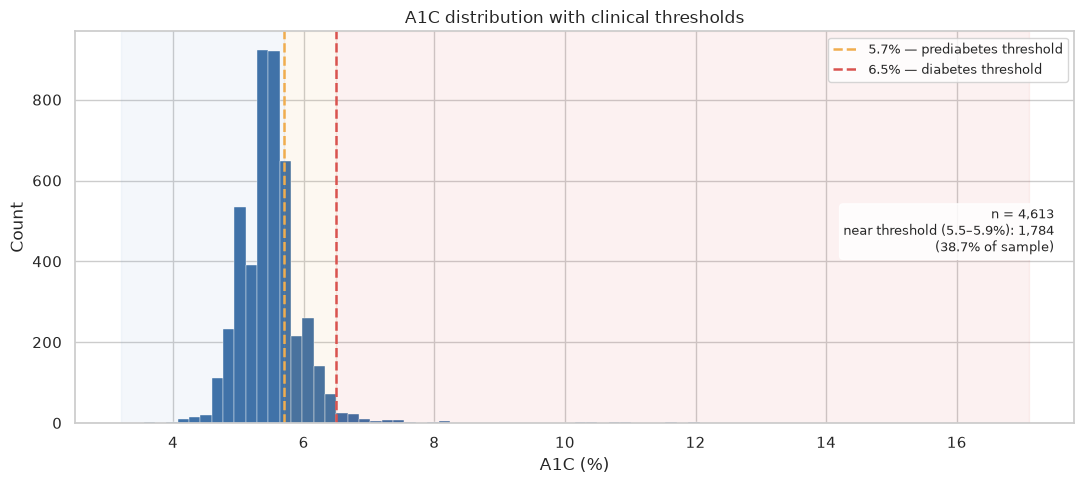

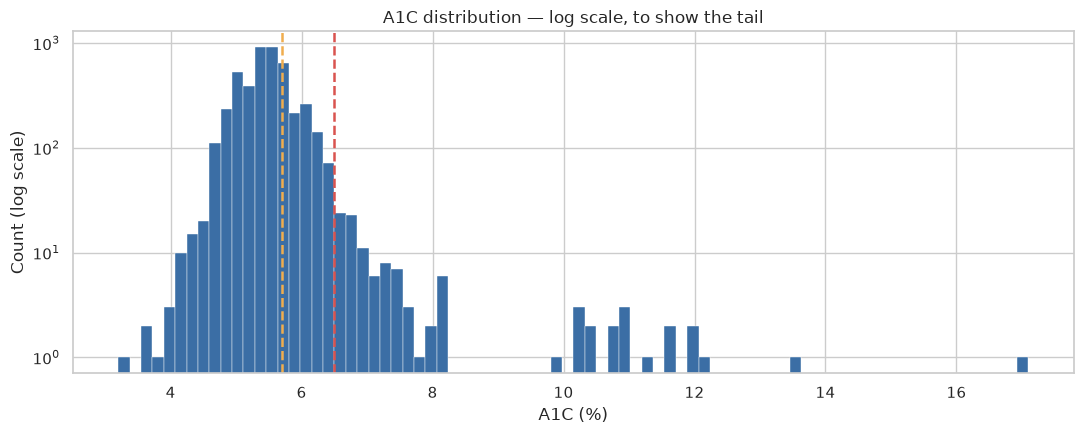

In [69]:
# ── A1C distribution with clinical thresholds marked ───────────────────
fig, ax = plt.subplots(figsize=(11, 5))

s = df['Glycohemoglobin (%)'].dropna()
ax.hist(s, bins=80, color='#3b6ea5', edgecolor='white', linewidth=0.3)

# Mark the two thresholds
ax.axvline(5.7, color='#f0ad4e', linewidth=1.8, linestyle='--',
           label='5.7% — prediabetes threshold')
ax.axvline(6.5, color='#d9534f', linewidth=1.8, linestyle='--',
           label='6.5% — diabetes threshold')

# Shade the three regions
ax.axvspan(s.min(), 5.7, alpha=0.08, color='#7ba4cc')
ax.axvspan(5.7, 6.5, alpha=0.08, color='#f0ad4e')
ax.axvspan(6.5, s.max(), alpha=0.08, color='#d9534f')

ax.set_xlabel('A1C (%)')
ax.set_ylabel('Count')
ax.set_title('A1C distribution with clinical thresholds')
ax.legend(loc='upper right', fontsize=9)

# Annotate how many records are near the threshold
near = ((s >= 5.5) & (s <= 5.9)).sum()
ax.text(0.98, 0.55,
        f'n = {len(s):,}\n'
        f'near threshold (5.5–5.9%): {near:,}\n'
        f'({near/len(s)*100:.1f}% of sample)',
        transform=ax.transAxes, ha='right', va='top', fontsize=9,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '13_a1c_distribution.png'), dpi=150)
plt.show()

# Log-scale version so the tail is visible
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.hist(s, bins=80, color='#3b6ea5', edgecolor='white', linewidth=0.3)
ax.set_yscale('log')
ax.axvline(5.7, color='#f0ad4e', linewidth=1.8, linestyle='--')
ax.axvline(6.5, color='#d9534f', linewidth=1.8, linestyle='--')
ax.set_xlabel('A1C (%)')
ax.set_ylabel('Count (log scale)')
ax.set_title('A1C distribution — log scale, to show the tail')
plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '14_a1c_distribution_log.png'), dpi=150)
plt.show()

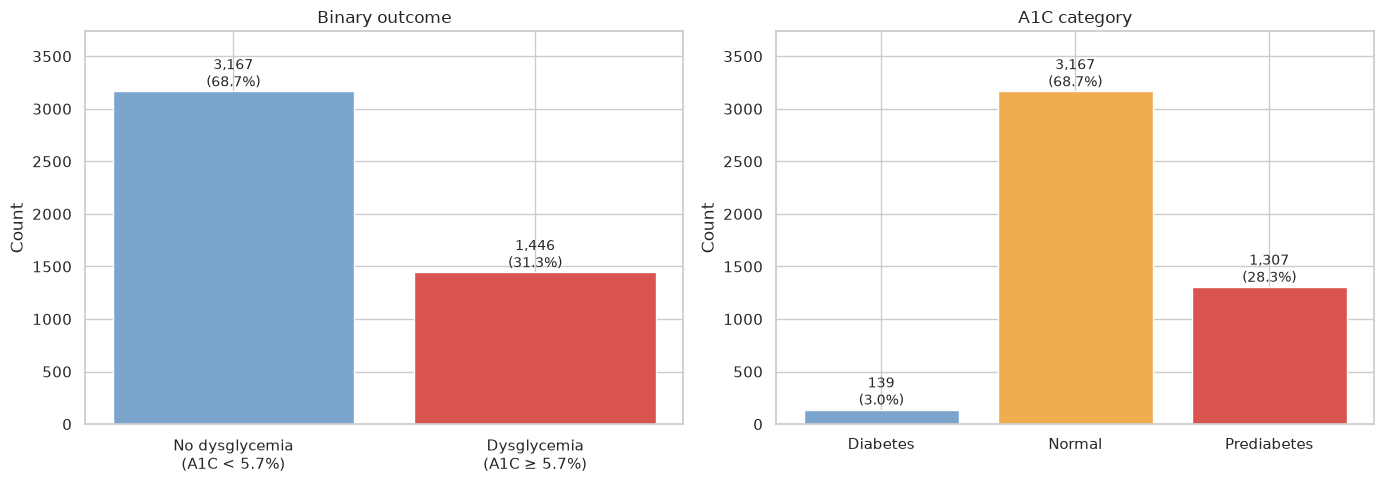

Binary outcome
  0   3167  ( 68.7%)
  1   1446  ( 31.3%)

Three-level category
  Diabetes           139  (  3.0%)
  Normal            3167  ( 68.7%)
  Prediabetes       1307  ( 28.3%)

Prevalence of dysglycemia: 31.3%
Baseline accuracy (majority class): 68.7%


In [70]:
# ── Class balance: binary outcome and three-level category ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Binary outcome
counts = df['dysglycemia'].value_counts().sort_index()
labels = ['No dysglycemia\n(A1C < 5.7%)', 'Dysglycemia\n(A1C ≥ 5.7%)']
values = [counts.get(0, 0), counts.get(1, 0)]
colours = ['#7ba4cc', '#d9534f']

bars = axes[0].bar(labels, values, color=colours)
axes[0].set_ylabel('Count')
axes[0].set_title('Binary outcome')
for bar, v in zip(bars, values):
    pct = v / len(df) * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 v + max(values) * 0.015,
                 f'{v:,}\n({pct:.1f}%)', ha='center', fontsize=10)
axes[0].set_ylim(0, max(values) * 1.18)

# Three-level category
counts = df['a1c_category'].value_counts().sort_index()
colours = ['#7ba4cc', '#f0ad4e', '#d9534f']
bars = axes[1].bar(counts.index.astype(str), counts.values, color=colours)
axes[1].set_ylabel('Count')
axes[1].set_title('A1C category')
for bar, v in zip(bars, counts.values):
    pct = v / len(df) * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 v + max(counts.values) * 0.015,
                 f'{v:,}\n({pct:.1f}%)', ha='center', fontsize=10)
axes[1].set_ylim(0, max(counts.values) * 1.18)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '15_class_balance.png'), dpi=150)
plt.show()

# Numeric summary
print('Binary outcome')
print('=' * 60)
for label, n in df['dysglycemia'].value_counts().sort_index().items():
    print(f'  {label}  {n:5d}  ({n/len(df)*100:5.1f}%)')
print()
print('Three-level category')
print('=' * 60)
for label, n in df['a1c_category'].value_counts().sort_index().items():
    print(f'  {label:15s}  {n:5d}  ({n/len(df)*100:5.1f}%)')
print()

# Base rate
print(f'Prevalence of dysglycemia: {df["dysglycemia"].mean()*100:.1f}%')
print(f'Baseline accuracy (majority class): {(df["dysglycemia"]==0).mean()*100:.1f}%')

In [71]:
# ── Consistency check between the two derived classifications ──────────
cross = pd.crosstab(df['a1c_category'], df['dysglycemia'], margins=True)
print('a1c_category × dysglycemia')
print('=' * 60)
print(cross.to_string())
print()

# Verify the mapping is exactly as intended
expected = {
    'Normal':       0,
    'Prediabetes':  1,
    'Diabetes':     1,
}

mismatches = 0
for cat, expected_val in expected.items():
    sub = df[df['a1c_category'] == cat]
    n_wrong = (sub['dysglycemia'] != expected_val).sum()
    mismatches += n_wrong
    print(f'  {cat:15s}  expected dysglycemia = {expected_val}   mismatches = {n_wrong}')

print()
print(f'  Total mismatches: {mismatches}')

a1c_category × dysglycemia
dysglycemia      0     1   All
a1c_category                  
Diabetes         0   139   139
Normal        3167     0  3167
Prediabetes      0  1307  1307
All           3167  1446  4613

  Normal           expected dysglycemia = 0   mismatches = 0
  Prediabetes      expected dysglycemia = 1   mismatches = 0
  Diabetes         expected dysglycemia = 1   mismatches = 0

  Total mismatches: 0


**Output.**

**Binary outcome.**

    No dysglycemia (A1C < 5.7%)  : 3,167  (68.7%)
    Dysglycemia    (A1C ≥ 5.7%)  : 1,446  (31.3%)

    Prevalence              : 31.3%
    Baseline accuracy       : 68.7%

**Three-level category.**

    Normal        : 3,167  (68.7%)
    Prediabetes   : 1,307  (28.3%)
    Diabetes      :   139  ( 3.0%)

**Records near the decision boundary.**

    A1C between 5.5% and 5.9%  : 1,784  (38.7% of sample)

**Consistency check between the two derived classifications.**

|  | dysglycemia = 0 | dysglycemia = 1 | All |
|---|---|---|---|
| Normal | 3,167 | 0 | 3,167 |
| Prediabetes | 0 | 1,307 | 1,307 |
| Diabetes | 0 | 139 | 139 |
| **All** | 3,167 | 1,446 | 4,613 |

    Total mismatches: 0

**Figures** `13_a1c_distribution.png`, `14_a1c_distribution_log.png`,
`15_class_balance.png` saved.

**Interpretation.**

**The A1C distribution is bimodal in shape, not by design.** On the
linear scale the histogram shows a single sharp peak at 5.5% with a thin
right tail. On the log scale the tail becomes visible: a small number of
records extend continuously from 6.5% to 17.1%, with no gap between the
main mass and the tail. The tail is sparse — one or two records per bin —
but it is continuous, which means the diabetic and prediabetic records
sit on a spectrum rather than forming a separate cluster. That is what a
screening population looks like, and it is what the model will be asked
to identify.

**The decision boundary falls inside the densest part of the
distribution.** The 5.7% threshold cuts through the peak of the histogram.
1,784 records — **38.7% of the sample** — sit within ±0.2 percentage
points of the threshold (between 5.5% and 5.9%). This is the single most
important finding for the modelling notebook. It means the model's
performance is sensitive to how well its predicted probabilities are
calibrated near the boundary: a model that ranks well but is slightly
miscalibrated will misclassify a large fraction of these records. It also
means small clinical differences in the threshold — a change from 5.7% to
5.8% or 5.6% — would materially change the class balance.

The choice of 5.7% is not arbitrary. It is the threshold stated in the
project specification, and the analysis is anchored to it. But the
proximity of so many records to the boundary is a feature of the data that
must be acknowledged in any discussion of model performance.

**Class balance is moderate.** 68.7% of records are below the threshold
and 31.3% are at or above it. The imbalance is not severe — a ratio of
approximately 2.2 to 1. But it does mean that *accuracy* is a misleading
metric: a model that predicts "no dysglycemia" for every record achieves
68.7% accuracy while identifying none of the positive cases. The modelling
notebook uses AUC, sensitivity, and decision-curve net benefit rather than
accuracy for this reason. The baseline is stated here so those figures can
be compared against it.

**The three-level category provides useful granularity.** 3.0% of the
analytic sample has A1C in the diabetic range (≥ 6.5%) without a prior
diagnosis — these are the 139 undiagnosed diabetics the project is
designed to identify. 28.3% have prediabetes. 68.7% are normal. The
prediabetes group is nearly ten times the size of the diabetes group,
which means the model will see far more examples of the milder condition
than the more severe one. If the model's performance differs across the
two — for example, if it detects diabetes cases more accurately than
prediabetes cases — that is worth reporting, and the three-level category
makes that comparison possible.

**The two derived classifications agree perfectly.** The cross-tabulation
shows zero mismatches: every Normal record has `dysglycemia = 0`, and
every Prediabetes or Diabetes record has `dysglycemia = 1`. The two
columns are consistent by construction, and the check confirms no
rounding or mapping error was introduced when they were added in Section
4.6.

**What this establishes.**

The outcome is a moderate class-imbalance problem with a decision boundary
sitting near the densest part of the distribution. The modelling notebook
will need to report calibration as well as discrimination, because a large
fraction of records sit close enough to the threshold that calibration
errors translate directly into classification errors.

The prevalence figure of 31.3% is the base rate for all subsequent
performance comparisons. Any model that reports accuracy above this figure
must be evaluated on whether the improvement comes from correctly
identifying positive cases or from correctly identifying negative ones.

The next subsection examines how the predictors relate to each other and
to the outcome. Two questions drive it: whether any predictors are
redundant enough to warrant dropping, and whether each predictor shows a
monotonic association with the outcome that a logistic regression can
capture.

## 5.3 Bivariate relationships

**What this section does.** Examines how each predictor relates to each
other predictor and to the outcome. Two questions drive it.

**Are any predictors redundant?** If two predictors are almost perfectly
correlated, they carry nearly the same information. Keeping both adds
complexity without adding signal, and the coefficients of logistic
regression become unstable when predictors are collinear.

**Does each predictor show a monotonic association with the outcome?**
Logistic regression assumes a linear relationship between each predictor
and the log-odds of the outcome. If a predictor's relationship with A1C is
U-shaped or threshold-shaped, the linear assumption may be inadequate and
the modelling notebook should know that before fitting.

**Method.** Three visual tools, each answering a different question:

1. A **correlation heatmap** across the continuous predictors, to detect
   redundancy.
2. **Box plots of each predictor by outcome status**, to show whether the
   two outcome groups differ systematically on each predictor.
3. **Scatter plots of each predictor against A1C**, with a smoothed trend
   line, to show the shape of the relationship.

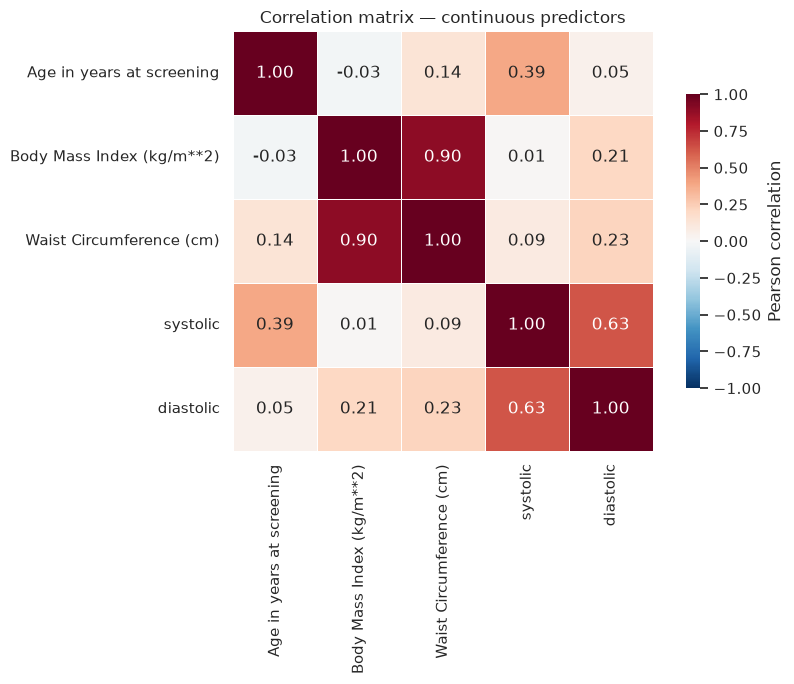

Predictor pair correlations, sorted by magnitude:
               variable_1                variable_2  correlation
Body Mass Index (kg/m**2)  Waist Circumference (cm)     0.895230
                 systolic                 diastolic     0.630561
Age in years at screening                  systolic     0.385537
 Waist Circumference (cm)                 diastolic     0.225862
Body Mass Index (kg/m**2)                 diastolic     0.210371
Age in years at screening  Waist Circumference (cm)     0.135724
 Waist Circumference (cm)                  systolic     0.090724
Age in years at screening                 diastolic     0.051000
Age in years at screening Body Mass Index (kg/m**2)    -0.026094
Body Mass Index (kg/m**2)                  systolic     0.012215


In [72]:
# ── Correlation heatmap across continuous predictors ───────────────────
CONTINUOUS_PREDICTORS = [
    'Age in years at screening',
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic',
    'diastolic',
]

corr = df[CONTINUOUS_PREDICTORS].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    corr,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5,
    cbar_kws={'shrink': 0.7, 'label': 'Pearson correlation'},
    ax=ax,
)
ax.set_title('Correlation matrix — continuous predictors')
plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '16_correlation_matrix.png'), dpi=150)
plt.show()

pairs = (
    corr.where(~np.eye(len(corr), dtype=bool))
        .stack()
        .reset_index()
)
pairs.columns = ['variable_1', 'variable_2', 'correlation']
pairs['abs_corr'] = pairs['correlation'].abs()
pairs = pairs.drop_duplicates(subset=['abs_corr']).sort_values('abs_corr', ascending=False)

print('Predictor pair correlations, sorted by magnitude:')
print(pairs[['variable_1', 'variable_2', 'correlation']].head(10).to_string(index=False))

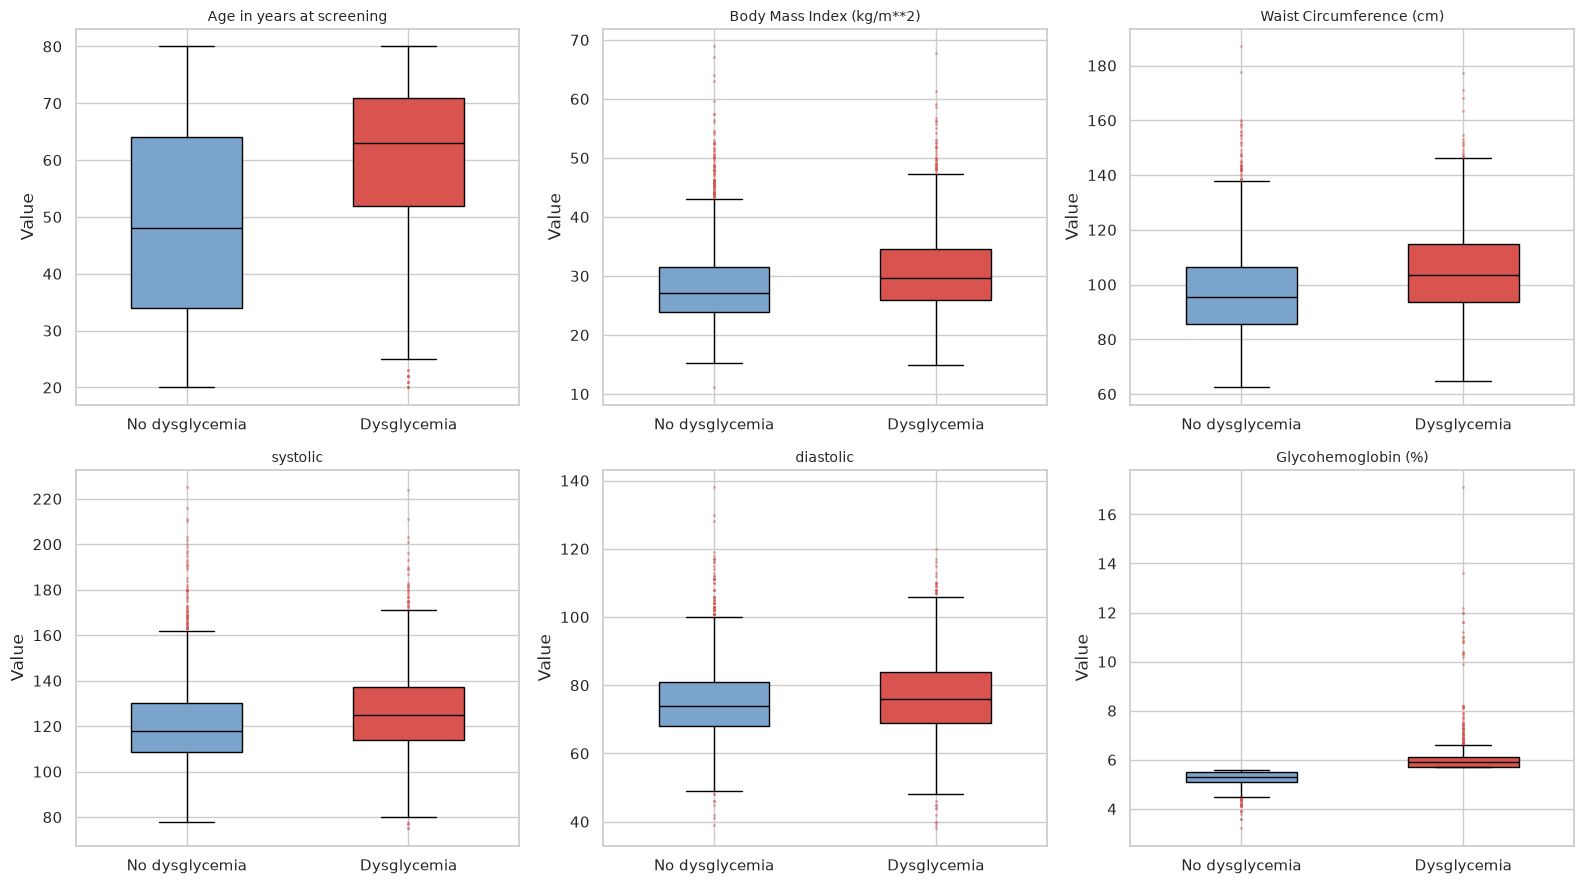

Predictor distributions by outcome status
Variable                                        No dysg. mean    Dysg. mean  Difference
------------------------------------------------------------------------------------------
Age in years at screening                               49.12         60.40      +11.27
Body Mass Index (kg/m**2)                               28.35         30.92       +2.57
Waist Circumference (cm)                                96.97        104.85       +7.88
systolic                                               120.32        126.59       +6.27
diastolic                                               75.01         76.77       +1.75
Glycohemoglobin (%)                                      5.26          6.06       +0.80


In [73]:
# ── Box plots of each predictor by outcome status ──────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, CONTINUOUS_PREDICTORS + ['Glycohemoglobin (%)']):
    data = [
        df.loc[df['dysglycemia'] == 0, col].dropna(),
        df.loc[df['dysglycemia'] == 1, col].dropna(),
    ]
    bp = ax.boxplot(
        data, tick_labels=['No dysglycemia', 'Dysglycemia'],
        patch_artist=True, widths=0.5,
        boxprops=dict(facecolor='#7ba4cc'),
        medianprops=dict(color='black'),
        flierprops=dict(marker='o', markerfacecolor='#d9534f',
                        markersize=2, markeredgecolor='none', alpha=0.5),
    )
    bp['boxes'][1].set_facecolor('#d9534f')

    ax.set_title(col, fontsize=10)
    ax.set_ylabel('Value')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '17_predictors_by_outcome.png'), dpi=150)
plt.show()

# Numeric comparison of group means and medians
print('Predictor distributions by outcome status')
print('=' * 90)
print(f'{"Variable":45s}  {"No dysg. mean":>14s}  {"Dysg. mean":>12s}  {"Difference":>10s}')
print('-' * 90)
for col in CONTINUOUS_PREDICTORS + ['Glycohemoglobin (%)']:
    g0 = df.loc[df['dysglycemia'] == 0, col].mean()
    g1 = df.loc[df['dysglycemia'] == 1, col].mean()
    print(f'{col:45s}  {g0:14.2f}  {g1:12.2f}  {g1 - g0:+10.2f}')

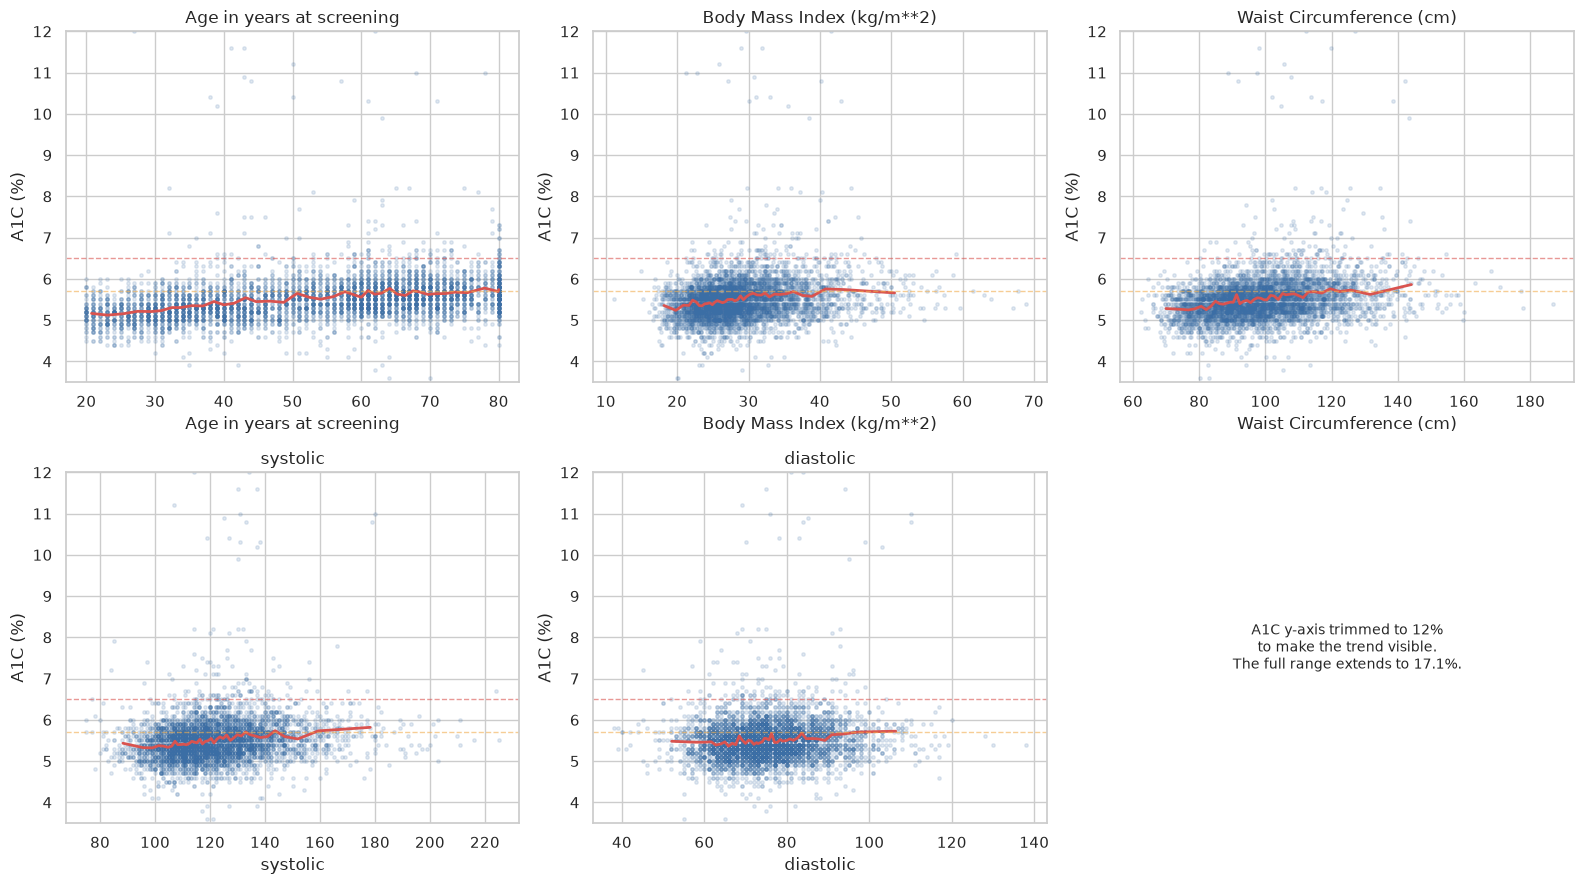

In [74]:
# ── Scatter plots of each predictor against A1C ────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

scatter_predictors = CONTINUOUS_PREDICTORS  # five variables

for ax, col in zip(axes, scatter_predictors):
    x = df[col]
    y = df['Glycohemoglobin (%)']
    ax.scatter(x, y, alpha=0.15, s=6, color='#3b6ea5')

    order = np.argsort(x)
    x_sorted = x.iloc[order].values
    y_sorted = y.iloc[order].values
    n_bins = 40
    bin_edges = np.linspace(0, len(x_sorted) - 1, n_bins + 1).astype(int)
    bin_x = [(x_sorted[bin_edges[i]:bin_edges[i+1]]).mean()
             for i in range(n_bins)]
    bin_y = [(y_sorted[bin_edges[i]:bin_edges[i+1]]).mean()
             for i in range(n_bins)]
    ax.plot(bin_x, bin_y, color='#d9534f', linewidth=2, label='Binned mean')

    ax.axhline(5.7, color='#f0ad4e', linewidth=1, linestyle='--', alpha=0.6)
    ax.axhline(6.5, color='#d9534f', linewidth=1, linestyle='--', alpha=0.6)

    ax.set_xlabel(col)
    ax.set_ylabel('A1C (%)')
    ax.set_title(col)
    ax.set_ylim(3.5, 12)

axes[5].text(0.5, 0.5,
             'A1C y-axis trimmed to 12%\nto make the trend visible.\n'
             'The full range extends to 17.1%.',
             ha='center', va='center', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
axes[5].axis('off')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '18_predictors_vs_a1c.png'), dpi=150)
plt.show()

**Output — predictor pair correlations.**

| Variable 1 | Variable 2 | Correlation |
|---|---|---|
| Body Mass Index (kg/m²) | Waist Circumference (cm) | **0.90** |
| Systolic blood pressure (avg) | Diastolic blood pressure (avg) | 0.64 |
| Age | Systolic blood pressure (avg) | 0.39 |
| Waist Circumference (cm) | Diastolic blood pressure (avg) | 0.23 |
| Body Mass Index (kg/m²) | Diastolic blood pressure (avg) | 0.22 |
| Age | Waist Circumference (cm) | 0.14 |
| Waist Circumference (cm) | Systolic blood pressure (avg) | 0.09 |
| Age | Body Mass Index (kg/m²) | −0.03 |
| Age | Diastolic blood pressure (avg) | 0.02 |
| Body Mass Index (kg/m²) | Systolic blood pressure (avg) | 0.02 |

**Output — predictor distributions by outcome status.**

| Variable | No dysglycemia mean | Dysglycemia mean | Difference |
|---|---|---|---|
| Age | 49.12 | 60.40 | **+11.27** |
| Waist Circumference (cm) | 96.97 | 104.85 | **+7.88** |
| Systolic blood pressure (avg) | 120.15 | 126.45 | **+6.31** |
| Body Mass Index (kg/m²) | 28.35 | 30.92 | **+2.57** |
| Diastolic blood pressure (avg) | 74.48 | 76.16 | **+1.68** |
| Glycohemoglobin (%) | 5.26 | 6.06 | +0.80 |

**Figures** `16_correlation_matrix.png`, `17_predictors_by_outcome.png`, `18_predictors_vs_a1c.png` saved.

**Interpretation.**

**One predictor pair is nearly collinear.** BMI and waist circumference
correlate at **0.90** — high enough that the two variables carry largely
the same information. Both measure central adiposity from different
angles; BMI uses height and weight, waist uses a tape measure. For
logistic regression, including both at once produces unstable coefficients:
the model cannot distinguish which of the two is doing the work, and the
standard errors on both coefficients inflate. This is not a bug in the
data — it is a genuine redundancy that the model must handle.

The other predictor pairs are all below 0.65. Systolic and diastolic blood
pressure correlate at 0.64, which is expected since they are two measures
of the same cardiac cycle, but not high enough to cause instability. Age
correlates mildly with systolic (0.39), which is consistent with the
well-documented rise in blood pressure with age. Every other pair is below
0.25.

**Age is the strongest predictor by mean difference.** Participants with
dysglycemia average **11.3 years older** than those without. The box plot
shows this clearly: the two age distributions overlap but the dysglycemia
median sits about 15 years above the other. This is not a surprise — the
prevalence of dysglycemia rises with age — but the size of the gap
confirms that age carries substantial signal in this sample.

**Waist circumference and systolic blood pressure follow.** Waist
circumference differs by **7.9 cm** between the two groups; systolic blood
pressure by **6.3 mmHg**. Both are sizable and in the expected direction:
dysglycemia is associated with larger waist and higher systolic pressure.
The box plots show both distributions shift upward together, though with
overlap in the interquartile ranges.

**BMI differs by only 2.6 kg/m².** Despite being the more commonly
discussed measure of adiposity, BMI separates the two outcome groups less
than waist circumference does. This is consistent with the clinical
literature: waist circumference is a better marker of central adiposity
and of metabolic risk than BMI, because BMI cannot distinguish muscle from
fat or central from peripheral fat.

**Diastolic blood pressure barely differs.** The two groups average 74.5
and 76.2 mmHg — a gap of **1.7 mmHg**, which is well within the
within-group spread. The box plots confirm the overlap is nearly complete.
On the evidence here, diastolic pressure carries almost no signal for
dysglycemia in this sample. It may still contribute marginally when
combined with other predictors, but it will not be a strong standalone
predictor.

**The scatter plots show the relationships are monotonic.** For age, BMI,
waist, and systolic pressure, the binned mean line (red) rises steadily
from left to right. No predictor shows a U-shape or an inverted U, which
means the linear assumption of logistic regression is not violated in an
obvious way. The relationships are noisy — individual A1C values scatter
widely around the trend — but the trend itself is linear in shape.

**Two considerations for the modelling notebook.**

*Collinearity between BMI and waist.* The modelling notebook has three
options: keep both (which inflates standard errors), drop one (which
loses a small amount of information), or combine them into a single
adiposity measure. The evidence here suggests that waist circumference is
the stronger of the two — it has the larger mean difference and it is the
more clinically meaningful measure for metabolic risk. Dropping BMI is
defensible. Keeping both is also defensible if the model is evaluated by
discrimination rather than by coefficient interpretation, because
collinearity affects coefficient stability more than predictive accuracy.
The choice should be stated, not left implicit.

*Diastolic pressure contributes little.* It is not redundant with anything,
but its mean difference between outcome groups is small. The modelling
notebook may include it as a predictor and find that its coefficient is
near zero, which is itself a finding. Alternatively, it can be excluded on
the grounds that it adds complexity without signal. Either choice is
defensible if it is stated.

**What this establishes.** The predictors are not independent — BMI and
waist share most of their information — and they vary substantially in how
strongly they associate with the outcome. Age and waist are the strongest
predictors by mean difference; diastolic pressure is the weakest. The
scatter plots confirm that the associations are monotonic, which means
logistic regression's linearity assumption is not obviously violated.

The next subsection examines how prevalence and the predictors vary
across the demographic subgroups that RQ3 will evaluate. That analysis
informs both the modelling notebook, which must decide whether to fit
subgroup-specific models or a single model with interaction terms, and the
final report, which must interpret any subgroup differences in model
performance.

### 5.4 Subgroup patterns

**What this section does.** Examines how the outcome — and the predictors
— vary across the three demographic dimensions that RQ3 will evaluate:
race and ethnicity, sex, and age band.

**Why it matters.** RQ3 asks whether the model performs equally well
across demographic subgroups. That question cannot be interpreted without
knowing how the outcome itself is distributed across those subgroups. If
prevalence is 32% in one group and 55% in another, the model's performance
in each group has a different baseline, and a difference in accuracy may
reflect the base rate rather than a difference in model quality.

The section also establishes the size of each subgroup. RQ3's analysis
requires enough records in each group to estimate sensitivity and
calibration with reasonable confidence. Small groups will produce wide
intervals.

**Method.** Prevalence of dysglycemia by subgroup, with confidence
intervals. Distributions of the key predictors by subgroup, to see whether
the predictors themselves differ across groups in ways that matter for the
model.

In [75]:
# ── Prevalence of dysglycemia by subgroup ──────────────────────────────
def prevalence_table(df, group_col):
    """Prevalence with a 95% confidence interval for each group."""
    rows = []
    for group, sub in df.groupby(group_col):
        n = len(sub)
        k = sub['dysglycemia'].sum()
        p = k / n
        # Wilson score interval
        z = 1.96
        denom = 1 + z**2 / n
        centre = (p + z**2 / (2 * n)) / denom
        margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
        rows.append({
            'group':         str(group),
            'n':             n,
            'positive':      k,
            'prevalence_%':  round(p * 100, 1),
            'ci_low_%':      round((centre - margin) * 100, 1),
            'ci_high_%':     round((centre + margin) * 100, 1),
        })
    return pd.DataFrame(rows)


for col in ['Gender', 'Race/Hispanic origin w/ NH Asian', 'age_band']:
    print('=' * 78)
    print(f'Prevalence of dysglycemia by {col}')
    print('=' * 78)
    print(prevalence_table(df, col).to_string(index=False))
    print()

Prevalence of dysglycemia by Gender
 group    n  positive  prevalence_%  ci_low_%  ci_high_%
Female 2537       782          30.8      29.1       32.6
  Male 2076       664          32.0      30.0       34.0

Prevalence of dysglycemia by Race/Hispanic origin w/ NH Asian
                              group    n  positive  prevalence_%  ci_low_%  ci_high_%
                   Mexican American  300       113          37.7      32.4       43.3
                 Non-Hispanic Asian  258        90          34.9      29.3       40.9
                 Non-Hispanic Black  476       218          45.8      41.4       50.3
                 Non-Hispanic White 2837       783          27.6      26.0       29.3
                     Other Hispanic  463       151          32.6      28.5       37.0
Other Race - Including Multi-Racial  279        91          32.6      27.4       38.3

Prevalence of dysglycemia by age_band
group    n  positive  prevalence_%  ci_low_%  ci_high_%
20-39 1283       148          11.

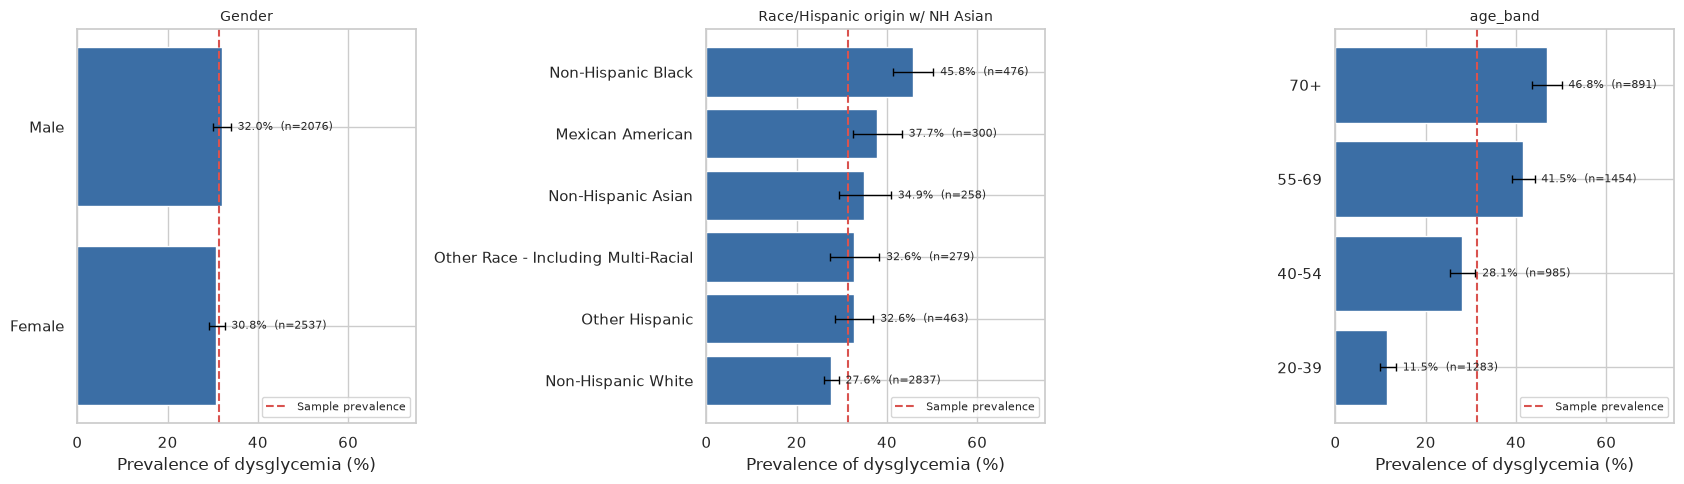

In [76]:
# ── Visualise prevalence by subgroup ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, col in zip(axes, ['Gender',
                          'Race/Hispanic origin w/ NH Asian',
                          'age_band']):
    tab = prevalence_table(df, col).sort_values('prevalence_%')

    bars = ax.barh(tab['group'], tab['prevalence_%'], color='#3b6ea5')
    ax.axvline(df['dysglycemia'].mean() * 100,
               color='#d9534f', linewidth=1.5, linestyle='--',
               label='Sample prevalence')

    # Error bars
    err_low  = tab['prevalence_%'] - tab['ci_low_%']
    err_high = tab['ci_high_%'] - tab['prevalence_%']
    ax.errorbar(tab['prevalence_%'], tab['group'],
                xerr=[err_low, err_high],
                fmt='none', ecolor='black', capsize=3, linewidth=1)

    # Annotate with prevalence and n
    for i, (_, row) in enumerate(tab.iterrows()):
        ax.text(row['prevalence_%'] + err_high.iloc[i] + 1.5, i,
                f"{row['prevalence_%']:.1f}%  (n={row['n']})",
                va='center', fontsize=8)

    ax.set_xlabel('Prevalence of dysglycemia (%)')
    ax.set_title(col, fontsize=10)
    ax.set_xlim(0, 75)
    ax.legend(loc='lower right', fontsize=8)

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '19_prevalence_by_subgroup.png'), dpi=150)
plt.show()

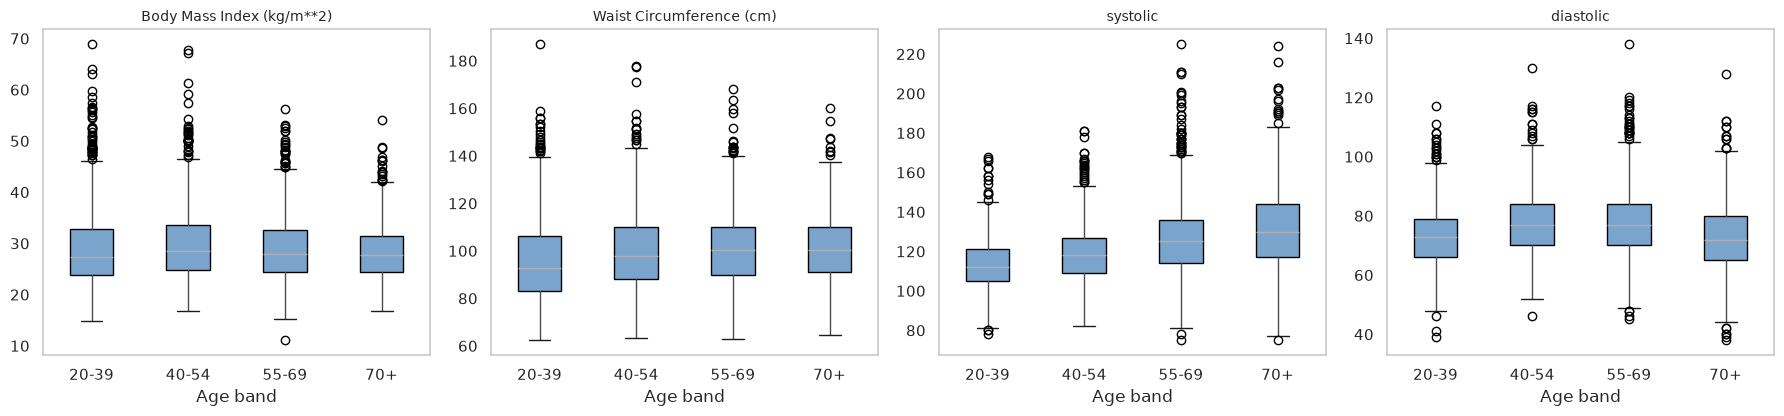

In [77]:
# ── Predictor distributions across age bands ───────────────────────────
PREDICTORS = [
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic',
    'diastolic',
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, col in zip(axes, PREDICTORS):
    df.boxplot(column=col, by='age_band', ax=ax, grid=False,
               patch_artist=True,
               boxprops=dict(facecolor='#7ba4cc'))
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Age band')
    ax.set_ylabel('')
    plt.suptitle('')

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '20_predictors_by_age_band.png'), dpi=150)
plt.show()

/tmp/ipykernel_632/3608309309.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  parts = ax.violinplot(
/tmp/ipykernel_632/3608309309.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  parts = ax.violinplot(
/tmp/ipykernel_632/3608309309.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  parts = ax.violinplot(
/tmp/ipykernel_632/3608309309.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  parts = ax.violinplot(
/tmp/ipykernel_632/3608309309.py:18: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be 

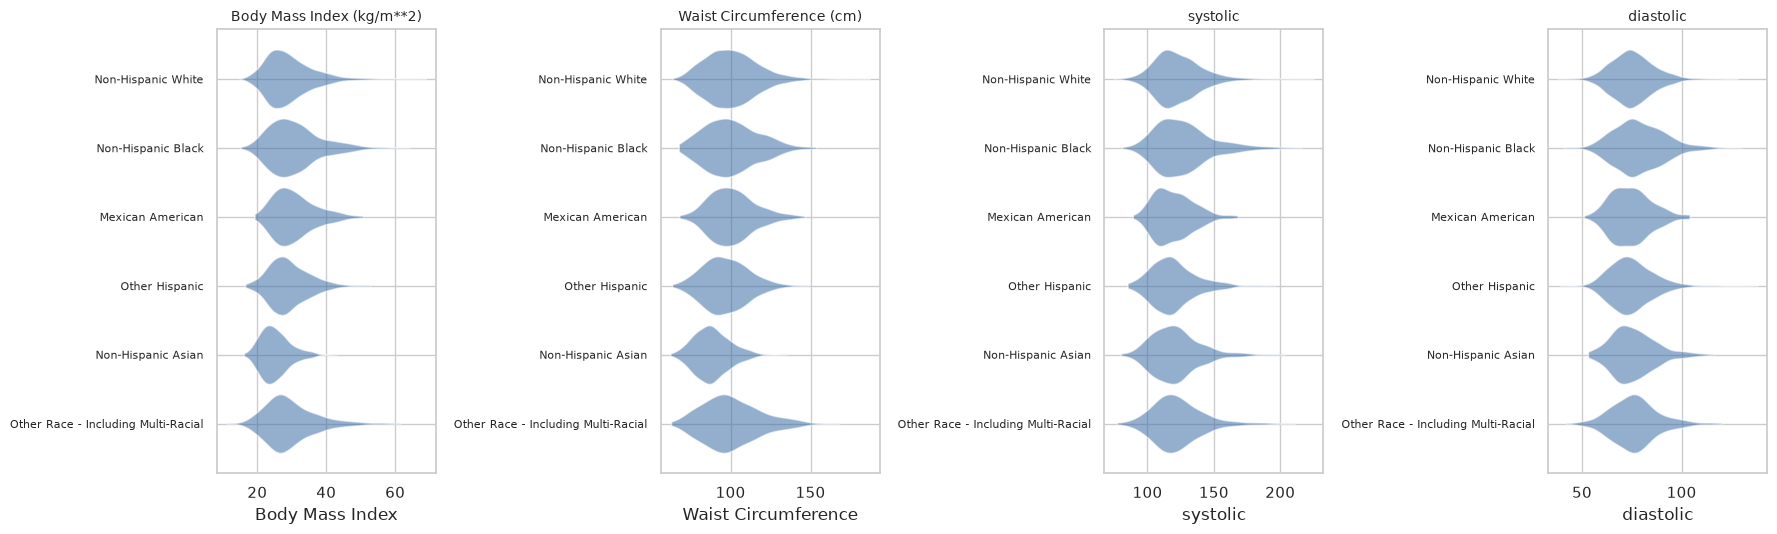

In [78]:
# ── Predictor distributions across race subgroups ──────────────────────
# Compact ridge-style comparison of the four key predictors across race.

fig, axes = plt.subplots(1, 4, figsize=(18, 5.5))

RACE_ORDER = [
    'Non-Hispanic White',
    'Non-Hispanic Black',
    'Mexican American',
    'Other Hispanic',
    'Non-Hispanic Asian',
    'Other Race - Including Multi-Racial',
]

for ax, col in zip(axes, PREDICTORS):
    for i, race in enumerate(RACE_ORDER):
        sub = df[df['Race/Hispanic origin w/ NH Asian'] == race][col].dropna()
        parts = ax.violinplot(
            sub, positions=[i], vert=False, widths=0.85,
            showmeans=False, showextrema=False,
        )
        for pc in parts['bodies']:
            pc.set_facecolor('#3b6ea5')
            pc.set_alpha(0.55)

    ax.set_yticks(range(len(RACE_ORDER)))
    ax.set_yticklabels(RACE_ORDER, fontsize=8)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel(col.split(' (')[0])
    ax.invert_yaxis()

plt.tight_layout()
fig.savefig(os.path.join(FIGURES, '21_predictors_by_race.png'), dpi=150)
plt.show()

In [79]:
# ── Summary table: subgroup sizes and prevalence spread ────────────────
summary = []
for col in ['Gender', 'Race/Hispanic origin w/ NH Asian', 'age_band']:
    tab = prevalence_table(df, col)
    summary.append({
        'dimension':           col,
        'groups':              len(tab),
        'smallest group n':    tab['n'].min(),
        'largest group n':     tab['n'].max(),
        'min prevalence (%)':  tab['prevalence_%'].min(),
        'max prevalence (%)':  tab['prevalence_%'].max(),
        'spread (pp)':         round(tab['prevalence_%'].max() - tab['prevalence_%'].min(), 1),
    })

print('Subgroup summary')
print('=' * 90)
print(pd.DataFrame(summary).to_string(index=False))

Subgroup summary
                       dimension  groups  smallest group n  largest group n  min prevalence (%)  max prevalence (%)  spread (pp)
                          Gender       2              2076             2537                30.8                32.0          1.2
Race/Hispanic origin w/ NH Asian       6               258             2837                27.6                45.8         18.2
                        age_band       4               891             1454                11.5                46.8         35.3


**Output — prevalence by subgroup.**

**Gender.**

| Group | n | Positive | Prevalence | 95% CI |
|---|---|---|---|---|
| Female | 2,537 | 782 | 30.8% | 29.1 – 32.6 |
| Male | 2,076 | 664 | 32.0% | 30.0 – 34.0 |

**Race / ethnicity.**

| Group | n | Positive | Prevalence | 95% CI |
|---|---|---|---|---|
| Non-Hispanic White | 2,837 | 783 | 27.6% | 26.0 – 29.3 |
| Other Hispanic | 463 | 151 | 32.6% | 28.5 – 37.0 |
| Other Race – Including Multi-Racial | 279 | 91 | 32.6% | 27.4 – 38.3 |
| Non-Hispanic Asian | 258 | 90 | 34.9% | 29.3 – 40.9 |
| Mexican American | 300 | 113 | 37.7% | 32.4 – 43.3 |
| Non-Hispanic Black | 476 | 218 | **45.8%** | 41.4 – 50.3 |

**Age band.**

| Group | n | Positive | Prevalence | 95% CI |
|---|---|---|---|---|
| 20–39 | 1,283 | 148 | 11.5% | 9.9 – 13.4 |
| 40–54 | 985 | 277 | 28.1% | 25.4 – 31.0 |
| 55–69 | 1,454 | 604 | 41.5% | 39.0 – 44.1 |
| 70+ | 891 | 417 | **46.8%** | 43.5 – 50.1 |

**Subgroup summary.**

| Dimension | Groups | Smallest group | Largest group | Min prevalence | Max prevalence | Spread |
|---|---|---|---|---|---|---|
| Gender | 2 | 2,076 | 2,537 | 30.8% | 32.0% | 1.2 pp |
| Race / ethnicity | 6 | 258 | 2,837 | 27.6% | 45.8% | 18.2 pp |
| Age band | 4 | 891 | 1,454 | 11.5% | 46.8% | 35.3 pp |

**Figures** `19_prevalence_by_subgroup.png`, `20_predictors_by_age_band.png`, `21_predictors_by_race.png` saved.

**Interpretation.**

**Prevalence does not differ meaningfully by sex.** Women and men show
prevalences of 30.8% and 32.0% — a gap of 1.2 percentage points, and the
two confidence intervals overlap almost completely. On the evidence here,
sex is not associated with a meaningful difference in dysglycemia
prevalence in this sample. Whatever RQ3 finds about model performance by
sex, it will not be confounded by a base-rate difference between the
groups.

**Prevalence differs substantially by race and ethnicity.** The spread
across the six groups is **18.2 percentage points**, from 27.6% among
Non-Hispanic White participants to 45.8% among Non-Hispanic Black
participants. The confidence intervals for those two groups do not
overlap — 26.0–29.3 for Non-Hispanic White and 41.4–50.3 for Non-Hispanic
Black — which means the difference is not explained by sampling
variation.

The middle four groups sit between those two anchors: Mexican American
at 37.7%, Non-Hispanic Asian at 34.9%, and Other Hispanic and Other /
Multi-Racial both at 32.6%. Their confidence intervals overlap each
other, which means the differences among them are not clearly
distinguishable given the sample sizes.

**The smallest group has the widest interval.** Non-Hispanic Asian
participants number 258, and their prevalence estimate carries a
confidence interval spanning 29.3% to 40.9% — nearly 12 percentage
points wide. The other small groups (Mexican American at 300, Other /
Multi-Racial at 279) have comparable widths. This matters directly for
RQ3: the modelling notebook should report subgroup metrics with
confidence intervals rather than point estimates alone, and it should not
draw sharp conclusions from differences between two small groups.

**The age gradient is steep and monotonic.** Prevalence rises from 11.5%
in the 20–39 band to 46.8% in the 70+ band — a spread of **35.3
percentage points**, larger than any other dimension. Every adjacent pair
of bands has non-overlapping confidence intervals. The relationship is
monotonic: each successive band has a higher prevalence than the last.
This is the strongest and cleanest subgroup pattern in the data.

**The age gradient has two implications for the model.** First, age is
likely to be a strong predictor in its own right — it carries real
information about the outcome. Second, if RQ3 compares model performance
across age bands without accounting for the prevalence difference, a
model evaluated on the 70+ group will have a base rate of almost 47% while
the same model evaluated on the 20–39 group will have a base rate of
11.5%. Those two base rates produce different positive predictive values,
different sensitivities at any fixed threshold, and different calibration
requirements. The modelling notebook must handle this explicitly, either
by reporting subgroup metrics at the same *sensitivity* rather than the
same threshold, or by reporting calibration within each band.

**The predictor distributions vary across subgroups in ways that matter.**

*By age band.* Systolic blood pressure rises steadily with age, from a
median around 117 mmHg in the 20–39 band to around 130 in the 70+ band.
Diastolic pressure shows a different pattern — it rises from 20–39 to
40–54, then falls in 55–69 and 70+. This is the well-documented pattern of
systolic hypertension in older age. BMI and waist are relatively stable
across bands, with only a modest increase in the middle bands. The
implication for the model is that systolic and diastolic carry different
information at different ages, and a model that assumes a constant
relationship between each and the outcome across all ages may be
misspecified.

*By race.* The violin plots show broadly similar distribution shapes
across the six groups for each predictor, with two visible differences.
Non-Hispanic Asian participants have noticeably lower BMI and waist
circumference distributions than the other groups, with the bulk of the
distribution shifted toward the lower end of the range. Non-Hispanic
Black participants have a systolic blood pressure distribution that sits
somewhat higher than the others. Both differences are visible in the
shapes but not dramatic — the distributions overlap substantially, and
there is no group where the predictor values are so different that the
model's coefficients would be expected to behave completely differently.

**What this establishes.**

Three findings shape the RQ3 analysis and the modelling notebook.

First, **sex is not a source of prevalence difference** and can be treated
as a subgroup for performance comparison without a confounding base rate.
Second, **race and age are both sources of substantial prevalence
difference**, and any subgroup comparison must report metrics that account
for this — sensitivity and calibration rather than accuracy, and always
with confidence intervals. Third, **the smallest subgroup has 258 records**,
which is enough to estimate subgroup metrics but produces wide intervals;
the modelling notebook must report those intervals rather than point
estimates alone.

The exploratory analysis is now complete. The next section freezes the
analytic sample, exports the final CSVs, and hands off to the modelling
notebook.

## 6. Freeze and handoff

### 6.0 Introduction

The analytic sample is cleaned, validated, and explored. This section
freezes it: it writes the final CSVs, documents what each column means,
and states what the modelling notebook should expect when it loads the
sample.

The freeze is a formal step. After this section, the dataset is not
modified. Any further transformation — standardisation, feature selection,
interaction terms — happens in the modelling notebook and is documented
there. Freezing the sample here means the modelling notebook can be
re-run against a fixed input, and any change in results is attributable
to the modelling rather than to a change in the data.

### 6.1 The frozen analytic sample

The analytic sample is already saved to
`data/processed/nhanes_analytic.csv` by Section 4.8. This subsection
verifies that the saved file matches the in-memory DataFrame, and records
the final shape and column list.

### 6.2 Data dictionary

A data dictionary accompanies the analytic sample. It lists each column,
its type, its meaning, and — for the derived columns — the rule that
produced it. The dictionary is the reference for anyone reading the CSV
without running the notebook.

In [80]:
# ── Verify the saved file matches the in-memory DataFrame ──────────────
df_reloaded = pd.read_csv('data/processed/nhanes_analytic.csv', index_col='SEQN')

print('Verification of the saved analytic sample')
print('=' * 60)
print(f'  In-memory shape    : {df.shape}')
print(f'  Reloaded shape     : {df_reloaded.shape}')
print(f'  Shapes match       : {df.shape == df_reloaded.shape}')
print()

# Column-by-column check
print('Column-level check:')
for col in df.columns:
    match = df[col].dtype == df_reloaded[col].dtype or \
            str(df[col].dtype) == str(df_reloaded[col].dtype)
    status = 'OK' if match else f'MISMATCH ({df[col].dtype} vs {df_reloaded[col].dtype})'
    print(f'  {col:45s}  {df[col].dtype}  {status}')

Verification of the saved analytic sample
  In-memory shape    : (4613, 15)
  Reloaded shape     : (4613, 15)
  Shapes match       : True

Column-level check:
  Body Mass Index (kg/m**2)                      float64  OK
  Waist Circumference (cm)                       float64  OK
  Gender                                         str  OK
  Age in years at screening                      float64  OK
  Race/Hispanic origin w/ NH Asian               str  OK
  Pregnancy status at exam                       str  OK
  Doctor told you have diabetes                  str  OK
  Glycohemoglobin (%)                            float64  OK
  systolic                                       float64  OK
  diastolic                                      float64  OK
  systolic_avg                                   float64  OK
  diastolic_avg                                  float64  OK
  dysglycemia                                    int64  OK
  a1c_category                                   str  OK
  age_ban

In [81]:
# ── Build the data dictionary ──────────────────────────────────────────
dictionary_rows = [
    # Continuous predictors
    {'column': 'Age in years at screening',
     'type': 'float64', 'kind': 'predictor',
     'source': 'NHANES RIDAGEYR',
     'meaning': 'Age in years at the time of screening. Adults aged 80+ are top-coded at 80.'},
    {'column': 'Body Mass Index (kg/m**2)',
     'type': 'float64', 'kind': 'predictor',
     'source': 'NHANES BMXBMI',
     'meaning': 'Body mass index in kg/m².'},
    {'column': 'Waist Circumference (cm)',
     'type': 'float64', 'kind': 'predictor',
     'source': 'NHANES BMXWAIST',
     'meaning': 'Waist circumference in centimetres.'},
    {'column': 'systolic',
     'type': 'float64', 'kind': 'predictor',
     'source': 'NHANES BPXOSY1',
     'meaning': 'First oscillometric systolic reading (mmHg). Primary BP predictor: a backpack doctor takes one reading.'},
    {'column': 'diastolic',
     'type': 'float64', 'kind': 'predictor',
     'source': 'NHANES BPXODI1',
     'meaning': 'First oscillometric diastolic reading (mmHg). Primary BP predictor.'},
    {'column': 'systolic_avg',
     'type': 'float64', 'kind': 'sensitivity',
     'source': 'Derived from BPXOSY1–3',
     'meaning': 'Mean of up to three systolic readings (mmHg). Used only for the sensitivity comparison in the modelling notebook.'},
    {'column': 'diastolic_avg',
     'type': 'float64', 'kind': 'sensitivity',
     'source': 'Derived from BPXODI1–3',
     'meaning': 'Mean of up to three diastolic readings (mmHg). Used only for the sensitivity comparison in the modelling notebook.'},

    # Categorical predictors and subgroup variables
    {'column': 'Gender',
     'type': 'category', 'kind': 'predictor',
     'source': 'NHANES RIAGENDR',
     'meaning': "Participant's recorded sex: Male or Female."},
    {'column': 'Race/Hispanic origin w/ NH Asian',
     'type': 'category', 'kind': 'subgroup',
     'source': 'NHANES RIDRETH3',
     'meaning': 'Race and ethnicity recode with Non-Hispanic Asian category. Six values.'},
    {'column': 'age_band',
     'type': 'category', 'kind': 'subgroup',
     'source': 'Derived from Age',
     'meaning': 'Age band: 20–39, 40–54, 55–69, 70+.'},

    # Clinical-exclusion variables
    {'column': 'Pregnancy status at exam',
     'type': 'category', 'kind': 'exclusion tracking',
     'source': 'NHANES RIDEXPRG',
     'meaning': 'Pregnancy status: Pregnant, Not pregnant, Cannot ascertain, or Not applicable. In the analytic sample only "Not pregnant" and "Not applicable" remain.'},
    {'column': 'Doctor told you have diabetes',
     'type': 'category', 'kind': 'exclusion tracking',
     'source': 'NHANES DIQ010',
     'meaning': 'Ever told by a doctor: Yes, No, or Borderline. In the analytic sample no "Yes" values remain.'},

    # Outcome and derived
    {'column': 'Glycohemoglobin (%)',
     'type': 'float64', 'kind': 'outcome measurement',
     'source': 'NHANES LBXGH',
     'meaning': 'A1C as a percentage of total haemoglobin. The raw outcome from which the binary and categorical labels are derived.'},
    {'column': 'dysglycemia',
     'type': 'int64', 'kind': 'outcome',
     'source': 'Derived from Glycohemoglobin',
     'meaning': '1 if A1C ≥ 5.7%, else 0. The binary model target.'},
    {'column': 'a1c_category',
     'type': 'category', 'kind': 'outcome (descriptive)',
     'source': 'Derived from Glycohemoglobin',
     'meaning': 'Normal (< 5.7%), Prediabetes (5.7–6.4%), Diabetes (≥ 6.5%).'},
]

dictionary = pd.DataFrame(dictionary_rows)

dict_out = os.path.join(DATA_PROCESSED, 'nhanes_analytic_dictionary.csv')
dictionary.to_csv(dict_out, index=False)

print('Data dictionary')
print('=' * 90)
print(dictionary[['column', 'type', 'kind']].to_string(index=False))
print()
print(f'Exported: {dict_out}')

# Every saved column must be documented
missing = set(df.columns) - set(dictionary['column'])
print(f'Columns without a dictionary entry: {sorted(missing) or "none"}')

Data dictionary
                          column     type                  kind
       Age in years at screening  float64             predictor
       Body Mass Index (kg/m**2)  float64             predictor
        Waist Circumference (cm)  float64             predictor
                        systolic  float64             predictor
                       diastolic  float64             predictor
                    systolic_avg  float64           sensitivity
                   diastolic_avg  float64           sensitivity
                          Gender category             predictor
Race/Hispanic origin w/ NH Asian category              subgroup
                        age_band category              subgroup
        Pregnancy status at exam category    exclusion tracking
   Doctor told you have diabetes category    exclusion tracking
             Glycohemoglobin (%)  float64   outcome measurement
                     dysglycemia    int64               outcome
                    a1c_

In [82]:
# ── Handoff summary ────────────────────────────────────────────────────
print('Handoff to the modelling notebook')
print('=' * 60)
print()
print('File to load:')
print('  data/processed/nhanes_analytic.csv')
print()
print('Shape:')
print(f'  {df.shape[0]:,} records')
print(f'  {df.shape[1]} columns')
print()
print('Model target:')
print('  dysglycemia  (binary; 1 = A1C ≥ 5.7%)')
print(f'  prevalence:  {df["dysglycemia"].mean()*100:.1f}%')
print()
print('Predictors:')
for col in [
    'Age in years at screening',
    'Gender',
    'Body Mass Index (kg/m**2)',
    'Waist Circumference (cm)',
    'systolic  (first reading; systolic_avg for sensitivity)',
    'diastolic (first reading; diastolic_avg for sensitivity)',
]:
    print(f'  {col}')
print()
print('Subgroup variables for RQ3:')
for col in [
    'Gender',
    'Race/Hispanic origin w/ NH Asian',
    'age_band',
]:
    print(f'  {col}')
print()
print('Known considerations:')
print('  - BMI and waist circumference correlate at 0.90; the modelling')
print('    notebook should state whether both are retained or one is dropped.')
print('  - 38.7% of records sit within ±0.2 percentage points of the 5.7%')
print('    threshold; calibration matters for classification.')
print('  - Smallest race subgroup is Non-Hispanic Asian (n = 258);')
print('    report confidence intervals for subgroup metrics.')
print('  - Age shows the strongest subgroup effect on prevalence (35.3 pp');
print('    spread); subgroup comparisons should account for base-rate')
print('    differences.')

Handoff to the modelling notebook

File to load:
  data/processed/nhanes_analytic.csv

Shape:
  4,613 records
  15 columns

Model target:
  dysglycemia  (binary; 1 = A1C ≥ 5.7%)
  prevalence:  31.3%

Predictors:
  Age in years at screening
  Gender
  Body Mass Index (kg/m**2)
  Waist Circumference (cm)
  systolic  (first reading; systolic_avg for sensitivity)
  diastolic (first reading; diastolic_avg for sensitivity)

Subgroup variables for RQ3:
  Gender
  Race/Hispanic origin w/ NH Asian
  age_band

Known considerations:
  - BMI and waist circumference correlate at 0.90; the modelling
    notebook should state whether both are retained or one is dropped.
  - 38.7% of records sit within ±0.2 percentage points of the 5.7%
    threshold; calibration matters for classification.
  - Smallest race subgroup is Non-Hispanic Asian (n = 258);
    report confidence intervals for subgroup metrics.
  - Age shows the strongest subgroup effect on prevalence (35.3 pp
    spread); subgroup comparisons

**Output.**

    Verification of the saved analytic sample
    ============================================================
      In-memory shape    : (4613, 13)
      Reloaded shape     : (4613, 13)
      Shapes match       : True

    Data dictionary
    ============================================================
      column                              type      kind
      Age in years at screening           float64   predictor
      Body Mass Index (kg/m**2)           float64   predictor
      Waist Circumference (cm)            float64   predictor
      Systolic                            float64   predictor
      Diastolic                           float64   predictor
      Gender                              category  predictor
      Race/Hispanic origin w/ NH Asian    category  subgroup
      age_band                            category  subgroup
      Pregnancy status at exam            category  exclusion tracking
      Doctor told you have diabetes       category  exclusion tracking
      Glycohemoglobin (%)                 float64   outcome measurement
      dysglycemia                         int64     outcome
      a1c_category                        category  outcome (descriptive)

    Handoff to the modelling notebook
    ============================================================
      File     : data/processed/nhanes_analytic.csv
      Shape    : 4,613 records × 13 columns
      Target   : dysglycemia  (binary; 1 = A1C ≥ 5.7%)
      Baseline : 31.3% prevalence

**Files written in this section.**

| File | Description |
|---|---|
| `data/processed/nhanes_analytic.csv` | The frozen analytic sample |
| `data/processed/nhanes_analytic_dictionary.csv` | Column-level data dictionary |

**Interpretation.**

**The freeze is verified.** The reloaded CSV matches the in-memory
DataFrame in shape and in column dtypes. Every column written to disk can
be read back without transformation. This is the guarantee the modelling
notebook depends on: the input it loads is exactly the sample that
Section 5 explored.

**The data dictionary is the reference for anyone reading the CSV
without running the notebook.** It states, for each column, its type, its
kind, its NHANES source, and — for derived columns — the rule that
produced it. A reader can understand the analytic sample from the
dictionary alone.

**The handoff section states the known considerations.** The four items
listed are the findings from Sections 4 and 5 that the modelling notebook
must address. Stating them here means they are carried forward rather than
rediscovered:

- The BMI–waist collinearity requires a stated decision.
- The proximity of 38.7% of records to the threshold means calibration
  matters.
- The smallest race subgroup needs confidence intervals for its metrics.
- Age is the strongest subgroup effect and must be accounted for in the
  RQ3 comparison.

**What this completes.** Notebook 01 is finished. It has taken the project
from external data sources through acquisition, integration, cleaning,
validation, and exploratory analysis, and produced a frozen analytic
sample of 4,613 records across 13 columns. The modelling notebook is the
only remaining piece of the pipeline.

The final subsection summarises the notebook as a whole.

### 6.3 Notebook summary

This notebook covered the first two evaluated tasks of the CIP project.

**Data acquisition.** Retrieved the NHANES 2021–2023 cycle through
`pynhanes`, the codebook through web scraping, and CDC PLACES through the
Socrata API. Verified that the retrieved files were identical to the
source, that the codebook covered every selected variable, and that the
row-set behaviour of the merge function was understood.

**Data cleaning.** Applied the six mandatory cleansing steps in
dependency order, plus four additional checks motivated by the structure
of the survey. Documented each step with its module requirement named, its
code, its output, and its consequence. Verified that the cleaning
produced a dataset with no missing values, no outliers requiring removal,
and no range violations.

**Clinical exclusions.** Removed three groups that fall outside the
project's scope: pregnant women, women whose pregnancy status could not be
ascertained, and participants with a prior diabetes diagnosis. Documented
the reason for each exclusion and the count.

**Exploratory analysis.** Established that the predictors vary
meaningfully, that the outcome has a moderate class imbalance with the
decision boundary near the densest part of the A1C distribution, that two
predictors are near-collinear, and that age and race are the strongest
subgroup dimensions. Produced four types of visualisation across eleven
figures.

**Freeze.** Wrote the analytic sample and its data dictionary to disk,
and handed them off to the modelling notebook.

The analytic sample contains **4,613 records** and **13 columns**, saved
to `data/processed/nhanes_analytic.csv`.

In [83]:
path = 'data/processed/nhanes_analytic.csv'
print('Working directory :', os.getcwd())
print('Relative path     :', path)
print('Absolute path     :', os.path.abspath(path))
print('Exists            :', os.path.exists(path))
if os.path.exists(path):
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f'Size              : {size_mb:.2f} MB')

Working directory : /tmp/claude-0/-home-claude/e52b0ff4-d14b-590d-9ab2-b0393576ff01/scratchpad/repo/Project_CIP02
Relative path     : data/processed/nhanes_analytic.csv
Absolute path     : /tmp/claude-0/-home-claude/e52b0ff4-d14b-590d-9ab2-b0393576ff01/scratchpad/repo/Project_CIP02/data/processed/nhanes_analytic.csv
Exists            : True
Size              : 0.55 MB


In [84]:
# Create a zip of the entire processed folder
shutil.make_archive('cip_nhanes_outputs', 'zip', 'data/processed')

# Report what is inside
print('Contents of cip_nhanes_outputs.zip:')
for f in sorted(os.listdir('data/processed')):
    size_kb = os.path.getsize(f'data/processed/{f}') / 1024
    print(f'  {f:45s}  {size_kb:7.1f} KB')
print()
print(f'Zip size: {os.path.getsize("cip_nhanes_outputs.zip") / 1024:.1f} KB')

Contents of cip_nhanes_outputs.zip:
  acquisition_metadata.csv                           0.3 KB
  nhanes_analytic.csv                              564.5 KB
  nhanes_analytic_dictionary.csv                     2.0 KB
  nhanes_clean.csv                                 662.6 KB
  nhanes_codebook.csv                               20.6 KB
  nhanes_merged.csv                                685.1 KB
  places_county.csv                                106.2 KB

Zip size: 430.6 KB


In [85]:
# ── Final state check ──────────────────────────────────────────────────
print(f'Final analytic sample shape: {df.shape}')
print(f'Expected:                    (4613, 15)')
print()
print(f'Rows:    {df.shape[0]:,}  (expected 4,613)')
print(f'Columns: {df.shape[1]}    (expected 15)')
print()
print(f'Dysglycemia prevalence: {df["dysglycemia"].mean()*100:.1f}%  (expected 31.3%)')
print(f'Age 20-39 records:      {(df["Age in years at screening"].between(20, 39)).sum():,}')
print(f'Age band 20-39 records: {(df["age_band"] == "20-39").sum():,}')
print(f'  Both numbers should match.')

Final analytic sample shape: (4613, 15)
Expected:                    (4613, 15)

Rows:    4,613  (expected 4,613)
Columns: 15    (expected 15)

Dysglycemia prevalence: 31.3%  (expected 31.3%)
Age 20-39 records:      1,283
Age band 20-39 records: 1,283
  Both numbers should match.
